# HealthAssist AI
## Domain-Specific Healthcare Question Answering with MedQuAD

**Machine Learning Techniques I — Individual Summative Project**

This notebook documents data preparation, exploratory analysis, a TF-IDF retrieval baseline,
fine-tuning and evaluating T5-small, qualitative error analysis, and the development of
a retrieval-grounded healthcare question-answering prototype.

**Scope:** This is an educational research prototype, not a medical diagnosis system.
ROUGE measures text overlap, not clinical correctness. Functional prototype tests
are not a substitute for clinical validation.

**Reproducibility note:** Some cells depend on Google Drive files, saved model checkpoints,
and the Colab environment used during development. Run the notebook in sequence after
configuring the required paths. The standalone application and dataset reconstruction
scripts are maintained in the project repository.



## 1. Installing Required Libraries

This project aims to develop a domain-specific healthcare question-answering system using Natural Language Processing (NLP).

We begin by installing the `datasets` library from Hugging Face. This library allows us to access and load publicly available datasets for machine learning research.

We will use it to download the MedQuAD dataset, which contains medical questions and answers collected from trusted healthcare information sources.
  

In [ ]:
!pip install datasets



## 2. Loading the Healthcare Dataset

### Dataset: MedQuAD (Medical Question Answering Dataset)

MedQuAD is a medical question-answering dataset developed using information from trusted healthcare sources, including websites associated with the U.S. National Institutes of Health (NIH).

The dataset contains questions and answers covering various healthcare topics, including diseases, symptoms, diagnosis, treatment, and prevention.

**Why we selected this dataset:**

- It contains real-world medical questions and answers.
- It covers multiple healthcare topics, making it suitable for a general healthcare assistant.
- It provides examples that can be used to train and evaluate NLP models.
- It supports our goal of developing an AI system that provides understandable healthcare information.

In this section, we load the dataset using the Hugging Face `datasets` library and inspect its structure before preprocessing.


In [ ]:
from datasets import load_dataset

# Load the MedQuAD healthcare dataset
dataset = load_dataset("lavita/MedQuAD")

# Display the dataset structure
print(dataset)


README.md:   0%|          | 0.00/2.77k [00:00<?, ?B/s]

data/train-00000-of-00001-e36383d177026d(…): reconstructing file:   0%|          |  0.00B / 10.7MB            

data/train-00000-of-00001-e36383d177026d(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/47441 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['document_id', 'document_source', 'document_url', 'category', 'umls_cui', 'umls_semantic_types', 'umls_semantic_group', 'synonyms', 'question_id', 'question_focus', 'question_type', 'question', 'answer'],
        num_rows: 47441
    })
})



## 3. Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) is the process of examining a dataset to understand its structure, content, and quality before using it for machine learning.

The MedQuAD dataset contains 47,441 records and 13 features.

In this section, we will:

- Convert the dataset into a Pandas DataFrame for easier analysis.
- Examine the first five records.
- Identify the questions, answers, and their categories.
- Understand how the data is organized.

This exploration will help us identify the information needed to develop our healthcare question-answering model.


In [ ]:
import pandas as pd

# Convert the Hugging Face dataset into a DataFrame
df = dataset["train"].to_pandas()

# Display the first five records
display(df[["question", "answer", "question_type", "category"]].head())


,question,answer,question_type,category
0,What is (are) keratoderma with woolly hair ?,Keratoderma with woolly hair is a group of rel...,information,None
1,How many people are affected by keratoderma wi...,Keratoderma with woolly hair is rare; its prev...,frequency,None
2,What are the genetic changes related to kerato...,"Mutations in the JUP, DSP, DSC2, and KANK2 gen...",genetic changes,None
3,Is keratoderma with woolly hair inherited ?,Most cases of keratoderma with woolly hair hav...,inheritance,None
4,What are the treatments for keratoderma with w...,These resources address the diagnosis or manag...,treatment,None



## 4. Data Quality Assessment

Data quality assessment helps identify problems that may affect machine learning model performance.

In this section, we investigate:

- Missing values in each column.
- Duplicate question-answer pairs.
- The number of unique medical question types.
- The distribution of questions across different categories.

These checks will help us determine which records are suitable for model training and what preprocessing steps are necessary.

We will not remove any records at this stage because we first need to understand the extent of the data quality issues.


In [ ]:
# Check the total number of records
print("Total records:", len(df))

# Check missing values in each column
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate question-answer pairs
duplicates = df.duplicated(
    subset=["question", "answer"]
).sum()

print("\nDuplicate question-answer pairs:", duplicates)

# Check unique question types
print("\nNumber of unique question types:")
print(df["question_type"].nunique())

# Display question type distribution
print("\nQuestion type distribution:")
print(df["question_type"].value_counts())


Total records: 47441

Missing values:
document_id                5
document_source            0
document_url               0
category               15431
umls_cui               16024
umls_semantic_types    16066
umls_semantic_group    16024
synonyms               22772
question_id                0
question_focus            14
question_type              0
question                   0
answer                 31034
dtype: int64

Duplicate question-answer pairs: 585

Number of unique question types:
39

Question type distribution:
question_type
information                                9214
symptoms                                   4338
treatment                                  3906
causes                                     2436
outlook                                    2232
exams and tests                            2058
when to contact a medical professional     1738
inheritance                                1446
precautions                                1413
side effects          


## 5. Data Cleaning and Preprocessing

The initial data quality assessment identified several issues in the MedQuAD dataset:

- 31,034 records contain missing answers.
- 585 duplicate question-answer pairs were detected.
- Several metadata columns contain missing values.

Since our objective is to train a healthcare question-answering model, each training example must contain a valid question and answer.

### Cleaning Strategy

We will:

1. Remove records with missing questions or answers.
2. Remove records containing empty questions or answers.
3. Remove duplicate question-answer pairs.
4. Reset the DataFrame index.
5. Compare the number of records before and after cleaning.

We will retain the original dataset separately to preserve reproducibility.

Further analysis will be conducted to identify low-quality answers and possible data leakage before splitting the dataset for model training.


> **Dataset-stage note:** Counts and leakage observations here describe this stage of the workflow; later cleaning and group-aware splitting establish the final 13,045 / 1,674 / 1,638 train/validation/test partitions.


In [ ]:

# Create a copy of the original dataset
df_clean = df.copy()

# Record the original dataset size
original_size = len(df_clean)

# Remove records with missing questions or answers
df_clean = df_clean.dropna(
    subset=["question", "answer"]
)

# Remove unnecessary whitespace
df_clean["question"] = df_clean["question"].str.strip()
df_clean["answer"] = df_clean["answer"].str.strip()

# Remove empty questions and answers
df_clean = df_clean[
    (df_clean["question"].str.len() > 0) &
    (df_clean["answer"].str.len() > 0)
]

# Remove duplicate question-answer pairs
df_clean = df_clean.drop_duplicates(
    subset=["question", "answer"]
)

# Reset the index
df_clean = df_clean.reset_index(drop=True)

# Display results
print("Original records:", original_size)
print("Cleaned records:", len(df_clean))
print("Removed records:", original_size - len(df_clean))

print("\nMissing questions:",
      df_clean["question"].isnull().sum())

print("Missing answers:",
      df_clean["answer"].isnull().sum())


Original records: 47441
Cleaned records: 16359
Removed records: 31082

Missing questions: 0
Missing answers: 0



## 6. Question and Answer Length Analysis

After cleaning the MedQuAD dataset, 16,359 question-answer pairs remain.

In this section, we analyze the length of questions and answers to better understand the dataset.

### Objectives

- Calculate the number of words in each question and answer.
- Identify unusually short or long responses.
- Examine the distribution of answer lengths.
- Determine whether the dataset is suitable for training a Transformer-based question-answering model.

Answer length is important because Transformer models have input and output token limits. Very long answers may require truncation or a different modeling strategy.

This analysis will guide our model selection and preprocessing decisions.


> **Dataset-stage note:** Counts and leakage observations here describe this stage of the workflow; later cleaning and group-aware splitting establish the final 13,045 / 1,674 / 1,638 train/validation/test partitions.


Question length statistics:
count    16359.000000
mean         8.214561
std          2.381010
min          3.000000
25%          6.000000
50%          8.000000
75%         10.000000
max         27.000000
Name: question_word_count, dtype: float64

Answer length statistics:
count    16359.000000
mean       200.366587
std        246.873458
min          1.000000
25%         71.000000
50%        138.000000
75%        251.000000
max       4281.000000
Name: answer_word_count, dtype: float64

Answers with fewer than 10 words: 79
Answers with more than 300 words: 2709


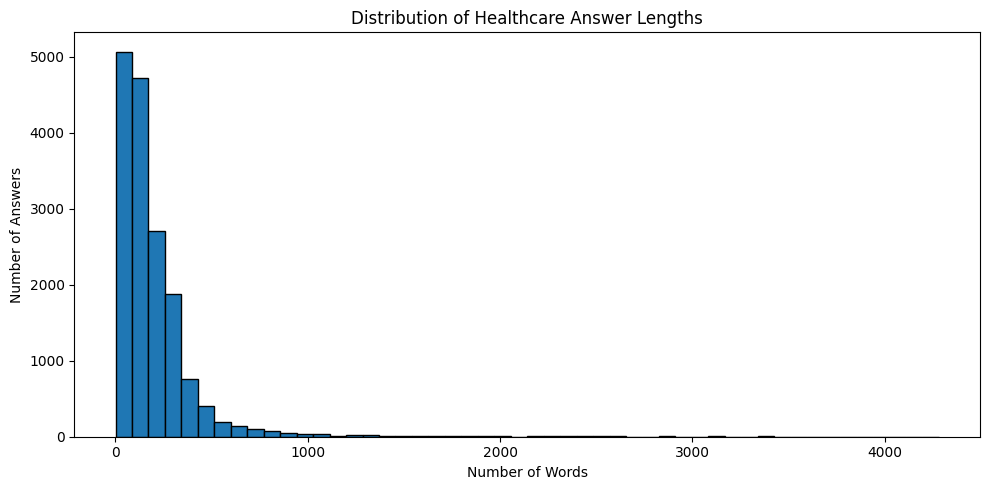

In [ ]:

import matplotlib.pyplot as plt

# Count words in each question and answer
df_clean["question_word_count"] = (
    df_clean["question"].str.split().str.len()
)

df_clean["answer_word_count"] = (
    df_clean["answer"].str.split().str.len()
)

# Display summary statistics
print("Question length statistics:")
print(df_clean["question_word_count"].describe())

print("\nAnswer length statistics:")
print(df_clean["answer_word_count"].describe())

# Count very short and long answers
print("\nAnswers with fewer than 10 words:",
      (df_clean["answer_word_count"] < 10).sum())

print("Answers with more than 300 words:",
      (df_clean["answer_word_count"] > 300).sum())

# Plot the distribution of answer lengths
plt.figure(figsize=(10, 5))

plt.hist(
    df_clean["answer_word_count"],
    bins=50,
    edgecolor="black"
)

plt.title("Distribution of Healthcare Answer Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Answers")

plt.tight_layout()
plt.show()



## 7. Investigating Answer Length Outliers

The answer length analysis revealed that:

- 79 answers contain fewer than 10 words.
- 2,709 answers contain more than 300 words.
- The longest answer contains 4,281 words.

These findings indicate considerable variation in response length.

### Objective

We will manually inspect examples of unusually short and long answers to determine whether they contain useful medical information.

Short answers may be incomplete or consist only of references, while long answers may contain detailed medical explanations.

We will use these findings to guide further preprocessing and model selection rather than removing records based only on their length.


> **Dataset-stage note:** Counts and leakage observations here describe this stage of the workflow; later cleaning and group-aware splitting establish the final 13,045 / 1,674 / 1,638 train/validation/test partitions.


In [ ]:
# Identify short and long answers
short_answers = df_clean[
    df_clean["answer_word_count"] < 10
]

long_answers = df_clean[
    df_clean["answer_word_count"] > 300
]

print("===== SHORT ANSWERS =====")

for _, row in short_answers.head(5).iterrows():
    print("\nQuestion:", row["question"])
    print("Answer:", row["answer"])
    print("-" * 60)

print("\n===== LONG ANSWERS =====")

for _, row in long_answers.head(3).iterrows():
    print("\nQuestion:", row["question"])
    print("Answer preview:", row["answer"][:700])
    print("Total words:", row["answer_word_count"])
    print("-" * 60)


===== SHORT ANSWERS =====

Question: How many people are affected by Pallister-Hall syndrome ?
Answer: This condition is very rare; its prevalence is unknown.
------------------------------------------------------------

Question: How many people are affected by Greig cephalopolysyndactyly syndrome ?
Answer: This condition is very rare; its prevalence is unknown.
------------------------------------------------------------

Question: How many people are affected by CATSPER1-related nonsyndromic male infertility ?
Answer: The prevalence of CATSPER1-related nonsyndromic male infertility is unknown.
------------------------------------------------------------

Question: How many people are affected by familial glucocorticoid deficiency ?
Answer: The prevalence of familial glucocorticoid deficiency is unknown.
------------------------------------------------------------

Question: How many people are affected by childhood myocerebrohepatopathy spectrum ?
Answer: The prevalence of childhood


## 8. Analysis of Healthcare Question Types

The MedQuAD dataset contains different types of healthcare questions, including information, symptoms, causes, treatments, and prevention.

After removing missing answers and duplicate question-answer pairs, we analyze the distribution of question types in the cleaned dataset.

### Objectives

- Identify the most common healthcare question types.
- Determine whether the dataset is balanced across question categories.
- Understand which types of questions our model will have the most training examples for.
- Identify possible limitations caused by underrepresented question types.

This analysis will help us evaluate how well our healthcare assistant performs across different medical information needs.


Number of unique question types: 16

Question type distribution:
question_type
information        4520
symptoms           2747
treatment          2440
inheritance        1446
frequency          1120
genetic changes    1087
causes              708
exams and tests     650
research            395
outlook             361
susceptibility      324
considerations      228
prevention          209
stages               77
complications        46
support groups        1
Name: count, dtype: int64


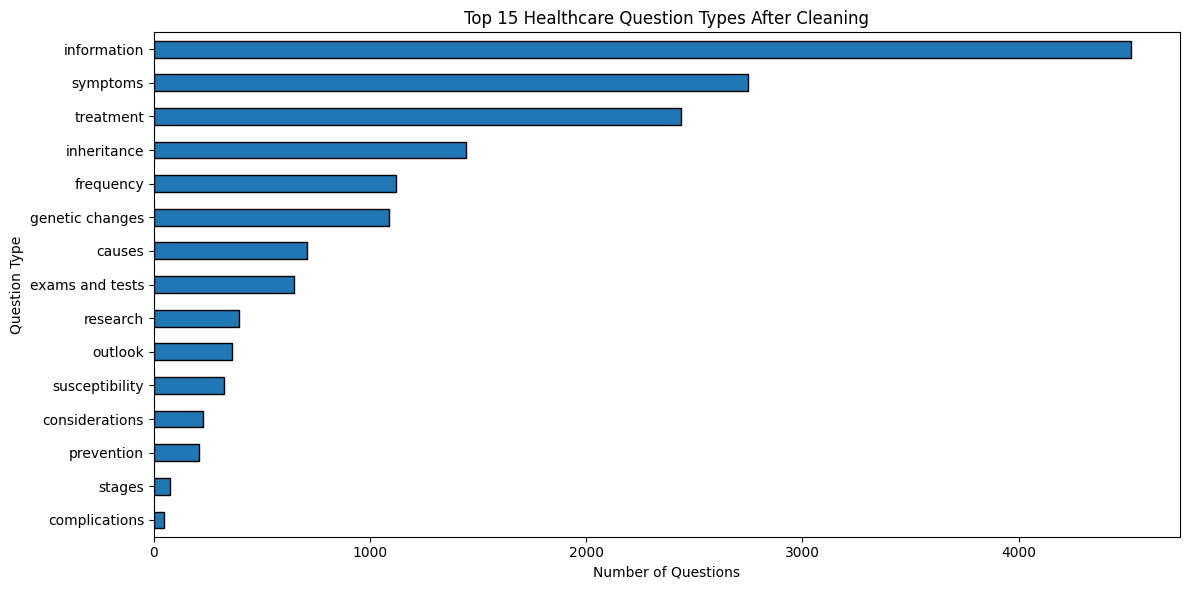

In [ ]:
import matplotlib.pyplot as plt

# Count question types after cleaning
question_counts = df_clean["question_type"].value_counts()

print("Number of unique question types:",
      df_clean["question_type"].nunique())

print("\nQuestion type distribution:")
print(question_counts)

# Visualize the 15 most common question types
plt.figure(figsize=(12, 6))

question_counts.head(15).sort_values().plot(
    kind="barh",
    edgecolor="black"
)

plt.title("Top 15 Healthcare Question Types After Cleaning")
plt.xlabel("Number of Questions")
plt.ylabel("Question Type")

plt.tight_layout()
plt.show()



## 9. Analysis of Medical Data Sources
The MedQuAD dataset contains medical question-answer pairs collected from different healthcare information sources.
In this section, we investigate the distribution of data sources after cleaning.
### Objectives
- Identify the medical information sources represented in the dataset.
- Determine how many questions and answers come from each source.
- Assess whether the dataset is dominated by particular sources.
- Understand potential limitations related to source representation.
This analysis is important because the quality and diversity of medical information sources can influence the reliability and generalization of our healthcare question-answering model.


Number of unique medical sources:
9

Distribution of medical sources:
document_source
GHR                  5430
GARD                 5389
NIDDK                1144
NINDS                1088
MPlusHealthTopics     981
NIHSeniorHealth       769
CancerGov             729
NHLBI                 559
CDC                   270
Name: count, dtype: int64


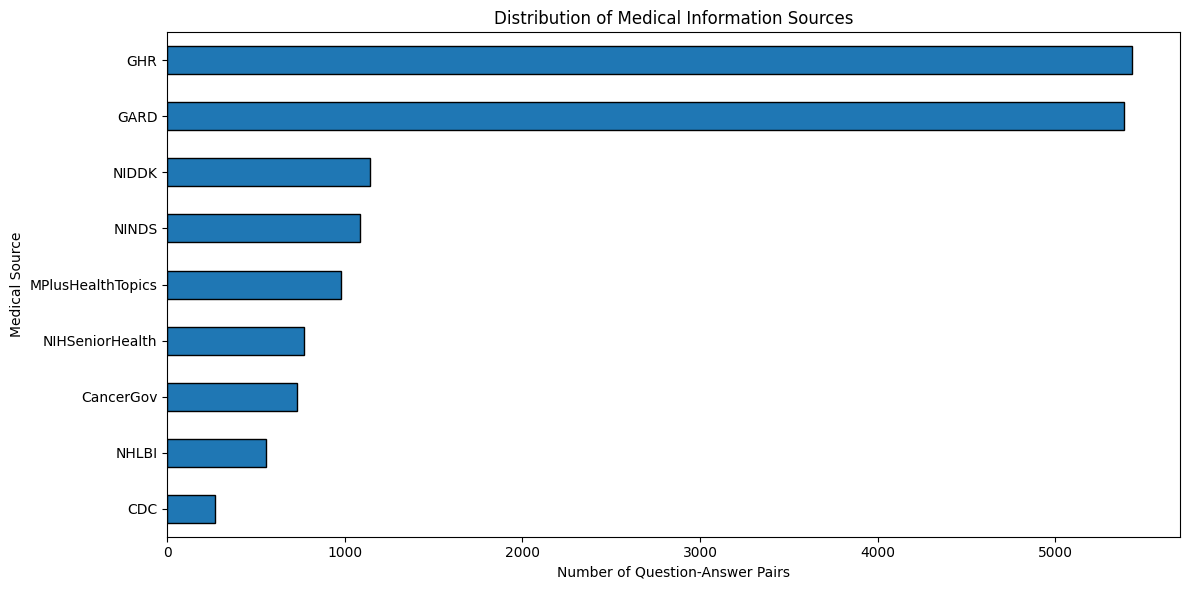

In [ ]:
# Count records from each medical source
source_counts = df_clean["document_source"].value_counts()
print("Number of unique medical sources:")
print(df_clean["document_source"].nunique())
print("\nDistribution of medical sources:")
print(source_counts)

# Visualize source distribution
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))
source_counts.sort_values().plot(
    kind="barh",
    edgecolor="black"
)
plt.title("Distribution of Medical Information Sources")
plt.xlabel("Number of Question-Answer Pairs")
plt.ylabel("Medical Source")
plt.tight_layout()
plt.show()


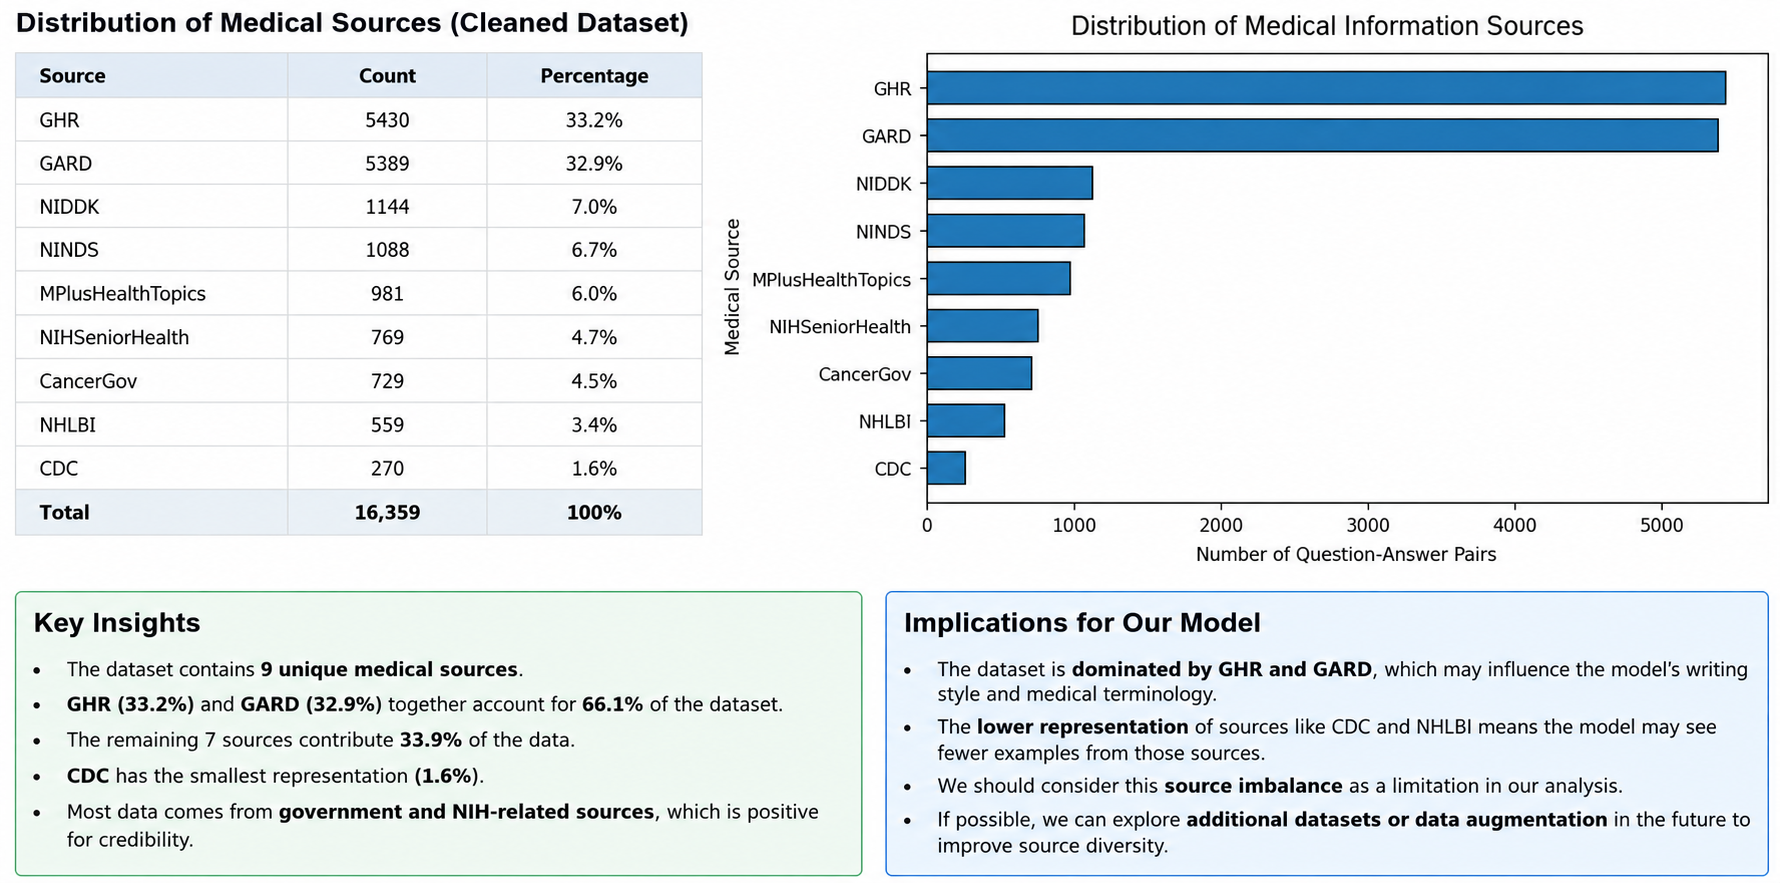


## 10. Analysis of Repeated Medical Topics
The MedQuAD dataset contains multiple questions related to the same medical conditions.
For example, a single disease may have questions about its symptoms, causes, diagnosis, treatment, and prevention.
### Objectives
- Identify the number of unique medical topics.
- Determine how frequently medical topics are repeated.
- Examine examples of questions related to the same condition.
- Investigate potential data leakage between training and testing datasets.
### Importance
If questions about the same medical condition appear in both training and testing datasets, the model may benefit from information already encountered during training.
To evaluate generalization to unseen medical topics, we may use a group-based data splitting strategy.
This analysis will help us determine an appropriate method for dividing our dataset into training, validation, and testing sets.


In [ ]:
# Count unique medical topics
print("Total question-answer pairs:", len(df_clean))
print("Unique medical topics:", df_clean["question_focus"].nunique())

# Count questions per medical topic
topic_counts = df_clean["question_focus"].value_counts()
print("\nTop 15 most frequent medical topics:")
print(topic_counts.head(15))

# Display questions about the most frequent topic
most_common_topic = topic_counts.index[0]
print("\nMost frequent topic:", most_common_topic)
print("\nQuestions about this topic:")
topic_examples = df_clean[
    df_clean["question_focus"] == most_common_topic
]
for question in topic_examples["question"].head(10):
    print("-", question)


Total question-answer pairs: 16359
Unique medical topics: 5125

Top 15 most frequent medical topics:
question_focus
Breast Cancer             53
Prostate Cancer           43
Stroke                    35
Skin Cancer               34
Alzheimer's Disease       30
Lung Cancer               29
Colorectal Cancer         29
High Blood Cholesterol    28
Heart Attack              28
Heart Failure             28
High Blood Pressure       27
Parkinson's Disease       25
Leukemia                  22
Shingles                  21
Osteoporosis              21
Name: count, dtype: int64

Most frequent topic: Breast Cancer

Questions about this topic:
- What is (are) Breast Cancer ?
- How to prevent Breast Cancer ?
- Who is at risk for Breast Cancer? ?
- what research (or clinical trials) is being done for Breast Cancer ?
- What is (are) Breast Cancer ?
- Who is at risk for Breast Cancer? ?
- what research (or clinical trials) is being done for Breast Cancer ?
- What is (are) Breast Cancer ?
- Who is at

## 11. Investigation of Repeated Medical Questions
The cleaned MedQuAD dataset contains 16,359 question-answer pairs covering 5,125 unique medical topics.
Our analysis revealed that some medical conditions have multiple questions, and certain questions appear more than once.
For example, Breast Cancer appears in 53 records, including repeated questions about its definition, prevention, and risk factors.
### Objectives
- Identify questions that appear multiple times.
- Determine whether repeated questions have different answers.
- Investigate whether repeated questions originate from different medical sources.
- Understand how repeated questions may affect model training and evaluation.
### Importance
Repeated questions with different answers may introduce inconsistencies during model training.
Additionally, placing identical questions in both training and testing datasets could lead to data leakage and overly optimistic evaluation results.
We will investigate these repetitions before deciding how to split the dataset.


In [ ]:
# Count repeated questions
question_counts = df_clean["question"].value_counts()
repeated_questions = question_counts[question_counts > 1]
print("Unique questions:", df_clean["question"].nunique())
print("Questions appearing more than once:", len(repeated_questions))
print("Total records involving repeated questions:", repeated_questions.sum())

# Examine the most frequently repeated question
if len(repeated_questions) > 0:
    most_repeated = repeated_questions.index[0]
    print("\nMost repeated question:", most_repeated)
    print("Number of occurrences:", repeated_questions.iloc[0])
    examples = df_clean[df_clean["question"] == most_repeated]
    for _, row in examples.head(5).iterrows():
        print("\nSource:", row["document_source"])
        print("Answer:", row["answer"][:500])
        print("-" * 50)


Unique questions: 14979
Questions appearing more than once: 875
Total records involving repeated questions: 2255

Most repeated question: What is (are) High Blood Cholesterol ?
Number of occurrences: 19

Source: NHLBI
Answer: To understand high blood cholesterol (ko-LES-ter-ol), it helps to learn about cholesterol. Cholesterol is a waxy, fat-like substance thats found in all cells of the body.
                
Your body needs some cholesterol to make hormones, vitamin D, and substances that help you digest foods. Your body makes all the cholesterol it needs. However, cholesterol also is found in some of the foods you eat.
                
Cholesterol travels through your bloodstream in small packages called lipoprote
--------------------------------------------------

Source: NIHSeniorHealth
Answer: What is Cholesterol? Cholesterol is a waxy, fat-like substance that your liver makes. It is also found in some foods that come from animals. Cholesterol is found in all parts of your body. 

## 12. Splitting the Dataset into Training, Validation, and Testing Sets
The cleaned MedQuAD dataset contains 16,359 question-answer pairs covering 5,125 unique medical topics.
Our analysis identified 875 questions that appear multiple times, sometimes with different answers from different medical sources.
### Objective
We divide the dataset into three subsets:
- Training set (approximately 80%): Used to train the machine learning model.
- Validation set (approximately 10%): Used to evaluate and improve the model during development.
- Testing set (approximately 10%): Reserved for final evaluation on unseen data.
### Group-Based Splitting
Instead of randomly splitting individual questions, we use a group-based splitting strategy based on medical topics.
This approach aims to prevent questions about the same medical condition from appearing in multiple subsets.
The resulting evaluation will help measure how effectively the model generalizes to medical topics not encountered during training.
A fixed random seed is used to ensure reproducibility.

**Status — preliminary split:** The counts produced in this step are not the final experimental dataset. The following leakage audit identifies cross-split duplicate questions, and Step 14 rebuilds the splits using connected topic groups. The final dataset is further refined in Steps 22–25.

> **Dataset-stage note:** Counts and leakage observations here describe this stage of the workflow; later cleaning and group-aware splitting establish the final 13,045 / 1,674 / 1,638 train/validation/test partitions.


In [ ]:

from sklearn.model_selection import GroupShuffleSplit
# Create a working copy
df_split = df_clean.copy()

# Create grouping labels using medical topics
# Fall back to document ID when question_focus is missing
df_split["topic_group"] = df_split["question_focus"].fillna(
    df_split["document_id"]
)
# Give any remaining missing groups a unique identifier
missing = df_split["topic_group"].isna()
df_split.loc[missing, "topic_group"] = [
    f"missing_topic_{i}" for i in df_split.index[missing]
]
# First split: 80% training, 20% temporary
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)
train_idx, temp_idx = next(
    splitter.split(df_split, groups=df_split["topic_group"])
)
train_df = df_split.iloc[train_idx].copy()
temp_df = df_split.iloc[temp_idx].copy()
# Second split: divide temporary data into validation and test
splitter2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.5,
    random_state=42
)
val_idx, test_idx = next(
    splitter2.split(temp_df, groups=temp_df["topic_group"])
)
val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

# Display results
print("Training records:", len(train_df))
print("Validation records:", len(val_df))
print("Testing records:", len(test_df))
print("\nTotal records:", len(train_df) + len(val_df) + len(test_df))

# Check for overlapping medical topics
train_topics = set(train_df["topic_group"])
val_topics = set(val_df["topic_group"])
test_topics = set(test_df["topic_group"])
print("\nOverlapping topics:")
print("Train vs Validation:", len(train_topics & val_topics))
print("Train vs Test:", len(train_topics & test_topics))
print("Validation vs Test:", len(val_topics & test_topics))


Training records: 13075
Validation records: 1686
Testing records: 1598

Total records: 16359

Overlapping topics:
Train vs Validation: 0
Train vs Test: 0
Validation vs Test: 0


## 13. Checking for Question Leakage Across Dataset Splits
After applying group-based splitting, the dataset was divided into 13,075 training records, 1,686 validation records, and 1,598 testing records.
No overlapping medical topic-group labels were found between the three subsets.
However, identical questions may still occur under different topic labels or medical sources.
### Objective
- Identify identical questions shared between dataset splits.
- Investigate potential data leakage.
- Determine whether additional grouping or preprocessing is necessary.
### Importance
Data leakage occurs when information from the training dataset improperly influences evaluation on validation or test data.
Preventing question overlap helps ensure that model performance reflects generalization rather than memorization of identical questions.

**Finding:** The initial split was **not accepted** for modeling: 80 normalized questions overlapped between training and validation, 118 between training and test, and 10 between validation and test. Distinct topic labels alone were insufficient to prevent identical-question leakage.

> **Dataset-stage note:** Counts and leakage observations here describe this stage of the workflow; later cleaning and group-aware splitting establish the final 13,045 / 1,674 / 1,638 train/validation/test partitions.


In [ ]:
# Normalize questions for comparison
def normalize_question(text):
    return " ".join(str(text).lower().split())
train_questions = set(train_df["question"].apply(normalize_question))
val_questions = set(val_df["question"].apply(normalize_question))
test_questions = set(test_df["question"].apply(normalize_question))

# Check for overlapping questions
train_val_overlap = train_questions & val_questions
train_test_overlap = train_questions & test_questions
val_test_overlap = val_questions & test_questions
print("Train vs Validation:", len(train_val_overlap))
print("Train vs Test:", len(train_test_overlap))
print("Validation vs Test:", len(val_test_overlap))

# Display examples if overlaps exist
if train_test_overlap:
    print("\nExamples of overlapping questions:")
    for question in list(sorted(train_test_overlap))[:5]:
        print("-", question)


Train vs Validation: 80
Train vs Test: 118
Validation vs Test: 10

Examples of overlapping questions:
- how many people are affected by prostate cancer ?
- is achondrogenesis inherited ?
- is amelogenesis imperfecta inherited ?
- is ankylosing spondylitis inherited ?
- is dentatorubral-pallidoluysian atrophy inherited ?


## 14. Fixing Data Leakage Using Connected Groups
The initial group-based split showed zero overlapping topic labels, but further analysis revealed identical questions across the training, validation, and testing sets.
Specifically, we found 80 overlapping questions between training and validation, 118 between training and testing, and 10 between validation and testing.
### Objective
- Prevent identical questions from appearing in different dataset splits.
- Keep related medical topics together.
- Recreate the training, validation, and testing datasets.
- Verify that no identical questions or connected topic groups overlap.
### Method
We connect medical topics whenever they share an identical normalized question.
We then assign each connected group entirely to one dataset split.
This helps reduce data leakage and supports more reliable evaluation.

**Finding:** The connected-group split resolves the identified identical-question overlap across partitions. Its initial sizes (13,046 / 1,675 / 1,638) are **intermediate**, before two low-information answers are removed.

> **Dataset-stage note:** Counts and leakage observations here describe this stage of the workflow; later cleaning and group-aware splitting establish the final 13,045 / 1,674 / 1,638 train/validation/test partitions.


In [ ]:
from sklearn.model_selection import GroupShuffleSplit
# Start with the cleaned dataset
df_split = df_clean.copy().reset_index(drop=True)
df_split["normalized_question"] = (
    df_split["question"].astype(str).str.lower().str.split().str.join(" ")
)
# Create topic labels
df_split["topic_group"] = df_split["question_focus"].fillna(
    df_split["document_id"]
)
missing = df_split["topic_group"].isna()
df_split.loc[missing, "topic_group"] = [
    f"missing_topic_{i}" for i in df_split.index[missing]
]
# Connect topics that share the same question
parent = {}
def find(x):
    parent.setdefault(x, x)
    if parent[x] != x:
        parent[x] = find(parent[x])
    return parent[x]
def union(a, b):
    root_a, root_b = find(a), find(b)
    if root_a != root_b:
        parent[root_b] = root_a
question_to_topic = {}
for topic, question in zip(
    df_split["topic_group"], df_split["normalized_question"]
):
    if question in question_to_topic:
        union(topic, question_to_topic[question])
    else:
        question_to_topic[question] = topic
df_split["connected_group"] = df_split["topic_group"].apply(find)
# Split by connected groups
splitter = GroupShuffleSplit(
    n_splits=1, test_size=0.2, random_state=42
)
train_idx, temp_idx = next(
    splitter.split(df_split, groups=df_split["connected_group"])
)
train_df = df_split.iloc[train_idx].copy()
temp_df = df_split.iloc[temp_idx].copy()
splitter2 = GroupShuffleSplit(
    n_splits=1, test_size=0.5, random_state=42
)
val_idx, test_idx = next(
    splitter2.split(temp_df, groups=temp_df["connected_group"])
)
val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()
# Verify the new split
print("Training records:", len(train_df))
print("Validation records:", len(val_df))
print("Testing records:", len(test_df))
print("Total records:", len(train_df) + len(val_df) + len(test_df))
for name, a, b in [
    ("Train vs Validation", train_df, val_df),
    ("Train vs Test", train_df, test_df),
    ("Validation vs Test", val_df, test_df)
]:
    question_overlap = len(
        set(a["normalized_question"]) & set(b["normalized_question"])
    )
    group_overlap = len(
        set(a["connected_group"]) & set(b["connected_group"])
    )
    print(f"{name}: {question_overlap} shared questions, {group_overlap} shared groups")


Training records: 13046
Validation records: 1675
Testing records: 1638
Total records: 16359
Train vs Validation: 0 shared questions, 0 shared groups
Train vs Test: 0 shared questions, 0 shared groups
Validation vs Test: 0 shared questions, 0 shared groups


## 15. Saving the Prepared Datasets
The MedQuAD dataset was cleaned and divided into training, validation, and testing subsets using connected medical-topic groups.
The final datasets contain:
- Training: 13,046 question-answer pairs
- Validation: 1,675 question-answer pairs
- Testing: 1,638 question-answer pairs
### Objective
Save the three datasets as CSV files for reproducibility and future model development.
### Importance
Saving the processed datasets ensures that all experiments use the same data splits, allowing fair comparisons between baseline and fine-tuned models.

**Status — intermediate version:** These files contain the connected-group split *before* the final two-record cleaning. Later saved CSVs in Step 25 (13,045 / 1,674 / 1,638) supersede them for the final experiments.

In [ ]:
# Save the three datasets as CSV files
train_df.to_csv("train.csv", index=False)
val_df.to_csv("validation.csv", index=False)
test_df.to_csv("test.csv", index=False)
# Verify the saved files
import os
for filename in ["train.csv", "validation.csv", "test.csv"]:
    print(filename, "- Saved:", os.path.exists(filename))

train.csv - Saved: True
validation.csv - Saved: True
test.csv - Saved: True


## 16. Building a TF-IDF Baseline Model
TF-IDF (Term Frequency–Inverse Document Frequency) is a technique that converts text into numerical features based on the importance of words.
### Objective
Build a baseline question-answering system that retrieves relevant medical answers by comparing user questions with questions in the training dataset.
### Method
1. Extract questions from the training dataset.
2. Convert questions into TF-IDF vectors.
3. Use cosine similarity to compare questions.
4. Retrieve the answer associated with the most similar training question.
### Importance
This baseline provides a reference point for evaluating more advanced machine learning models.
Unlike a generative language model, TF-IDF retrieves existing answers rather than generating new responses.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
# Extract training questions
train_questions = train_df["question"].tolist()
# Initialize TF-IDF vectorizer
tfidf_vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 2),
    max_features=10000
)
# Learn vocabulary and transform training questions
tfidf_matrix = tfidf_vectorizer.fit_transform(train_questions)
# Display results
print("Number of training questions:", len(train_questions))
print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("Vocabulary size:", len(tfidf_vectorizer.vocabulary_))

Number of training questions: 13046
TF-IDF matrix shape: (13046, 10000)
Vocabulary size: 10000


## 17. Building the Question-Answering Function
The TF-IDF vectorizer has successfully transformed 13,046 training questions into numerical representations with 10,000 features.
### Objective
Create a function that accepts a medical question and retrieves the most relevant answer from the training dataset.
### Method
1. Accept a question from the user.
2. Transform the question using the trained TF-IDF vectorizer.
3. Calculate cosine similarity between the user question and all training questions.
4. Identify the training question with the highest similarity score.
5. Return its associated medical answer.
### Importance
This function forms our first working healthcare question-answering baseline. It will later be evaluated against the validation and testing datasets.

**Dataset version:** This baseline uses the intermediate training set of 13,046 questions. The final baseline is rebuilt after cleaning in Step 24.

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
# Create a function to answer medical questions
def answer_question(user_question):
    # Convert the user's question into a TF-IDF vector
    question_vector = tfidf_vectorizer.transform([user_question])
    # Compare it with all training questions
    similarities = cosine_similarity(question_vector, tfidf_matrix).flatten()
    # Find the most similar question
    best_match_index = np.argmax(similarities)
    # Retrieve the corresponding question and answer
    matched_question = train_df.iloc[best_match_index]["question"]
    matched_answer = train_df.iloc[best_match_index]["answer"]
    similarity_score = similarities[best_match_index]
    # Display results
    print("Your Question:", user_question)
    print("\nMost Similar Question:", matched_question)
    print("\nSimilarity Score:", round(float(similarity_score), 4))
    print("\nHealthAssist AI Answer:\n", matched_answer)
# Test our first question
answer_question("What are the symptoms of diabetes?")

Your Question: What are the symptoms of diabetes?

Most Similar Question: What are the symptoms of Diabetes ?

Similarity Score: 1.0

HealthAssist AI Answer:
 Diabetes is often called a "silent" disease because it can cause serious complications even before you have symptoms. Symptoms can also be so mild that you dont notice them. An estimated 8 million people in the United States have type 2 diabetes and dont know it, according to 2012 estimates by the Centers for Disease Control and Prevention (CDC). Common Signs Some common symptoms of diabetes are: - being very thirsty  - frequent urination  - feeling very hungry or tired  - losing weight without trying  - having sores that heal slowly  - having dry, itchy skin  - loss of feeling or tingling in the feet  - having blurry eyesight. being very thirsty frequent urination feeling very hungry or tired losing weight without trying having sores that heal slowly having dry, itchy skin loss of feeling or tingling in the feet having blurry ey

## 18. Testing the Baseline on Unseen Questions
The TF-IDF baseline successfully retrieved an answer to a diabetes-related question with a cosine similarity score of 1.0.
However, this example was closely matched to a question in the training dataset.
### Objective
Test the baseline using a question from the validation dataset.
### Method
1. Select a question from the validation dataset.
2. Retrieve the most similar training question.
3. Display the retrieved answer.
4. Compare the retrieved answer with the reference answer.
### Importance
Testing on unseen questions helps us understand whether the baseline can generalize beyond questions used during training.
Cosine similarity measures textual similarity, not medical correctness.

In [ ]:
# Select a question from the validation dataset
sample = val_df.iloc[0]
validation_question = sample["question"]
reference_answer = sample["answer"]
# Display the validation question
print("VALIDATION QUESTION:")
print(validation_question)
# Retrieve an answer using our baseline
print("\nBASELINE MODEL RESULT:")
answer_question(validation_question)
# Display the actual reference answer
print("\nREFERENCE ANSWER:")
print(reference_answer)

VALIDATION QUESTION:
What is (are) primary ciliary dyskinesia ?

BASELINE MODEL RESULT:
Your Question: What is (are) primary ciliary dyskinesia ?

Most Similar Question: What is (are) Hypohidrotic ectodermal dysplasia with hypothyroidism and ciliary dyskinesia ?

Similarity Score: 0.5339

HealthAssist AI Answer:
 Hypohidrotic ectodermal dysplasia with hypothyroidism and ciliary dyskinesia is a rare condition characterized by alopecia (hair loss); nail dystrophy (abnormal development of the nails); ophthalmic (eye-related) complications; thyroid dysfunction (primary hypothyroidism); hypohidrosis; ephelides (freckles); enteropathy (disease of the intestine); and respiratory tract infections due to ciliary dyskinesia. These features have lead to the acronym ANOTHER syndrome as an alternative name for the condition. The gene that causes the condition is currently unknown but it is thought to be inherited in an autosomal recessive manner. Treatment is generally symptomatic and supportive.



## 19. Evaluating the TF-IDF Baseline Using ROUGE
The first validation example revealed that TF-IDF retrieved information about a related but different medical condition.
Although the retrieved question shared medical terminology with the validation question, the answer did not correctly address the target condition.
### Objective
Evaluate the TF-IDF baseline across the entire validation dataset.
### Evaluation Metrics
- ROUGE-1: Measures overlap between individual words.
- ROUGE-2: Measures overlap between consecutive pairs of words.
- ROUGE-L: Measures similarity based on the longest common subsequence.
### Method
1. Retrieve an answer for every validation question.
2. Compare each retrieved answer with its reference answer.
3. Calculate average ROUGE scores.
4. Use the results as baseline metrics for later model comparisons.
### Limitations
ROUGE measures textual overlap rather than factual or clinical correctness. Therefore, we will also examine individual predictions and use additional evaluation methods.
**Recorded-output clarification:** The TF-IDF evaluation cell below reports **1,675 validation questions** and ROUGE-1/2/L of **0.3465 / 0.1618 / 0.2424**. This is an **earlier evaluation before the two uninformative records were removed**. The later finalized split contains **1,674 validation records**. Do not substitute the later split count for this historical saved output.


In [ ]:
!pip install rouge-score -q

  Preparing metadata (setup.py) ... done


In [ ]:
from rouge_score import rouge_scorer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
# Convert all validation questions into TF-IDF vectors
val_vectors = tfidf_vectorizer.transform(val_df["question"].tolist())
# Retrieve the most similar training question for each validation question
similarities = cosine_similarity(val_vectors, tfidf_matrix)
best_match_indices = np.argmax(similarities, axis=1)
# Get predicted and reference answers
predicted_answers = train_df.iloc[best_match_indices]["answer"].tolist()
reference_answers = val_df["answer"].tolist()
# Initialize ROUGE scorer
scorer = rouge_scorer.RougeScorer(
    ["rouge1", "rouge2", "rougeL"],
    use_stemmer=True
)
# Calculate ROUGE scores
scores = {"rouge1": [], "rouge2": [], "rougeL": []}
for predicted, reference in zip(predicted_answers, reference_answers):
    result = scorer.score(str(reference), str(predicted))
    for metric in scores:
        scores[metric].append(result[metric].fmeasure)
# Display average scores
print("TF-IDF Baseline Evaluation Results")
print("Validation questions:", len(val_df))
for metric, values in scores.items():
    print(f"{metric.upper()}: {np.mean(values):.4f}")

TF-IDF Baseline Evaluation Results
Validation questions: 1675
ROUGE1: 0.3465
ROUGE2: 0.1618
ROUGEL: 0.2424


## 20. Error Analysis of the TF-IDF Baseline
The TF-IDF baseline was evaluated on 1,675 validation questions.
### Results
- ROUGE-1: 0.3465
- ROUGE-2: 0.1618
- ROUGE-L: 0.2424
### Objective
Identify examples where the baseline performs poorly and investigate why.
### Method
1. Calculate ROUGE-L for each validation prediction.
2. Identify the five lowest-scoring examples.
3. Compare the original question, matched training question, predicted answer, and reference answer.
4. Investigate common failure patterns.
### Importance
Error analysis helps explain model limitations and provides evidence for selecting a more advanced question-answering approach.

**Dataset version:** These scores (0.3465 / 0.1618 / 0.2424) are from the **pre-final-cleaning** validation set of 1,675 questions. The updated full-validation results after removing two records are 0.3468 / 0.1619 / 0.2426 (Step 25).

In [ ]:
# Create a table of validation predictions
results_df = val_df[["question", "answer"]].reset_index(drop=True).copy()
results_df["matched_question"] = train_df.iloc[best_match_indices]["question"].values
results_df["predicted_answer"] = predicted_answers
results_df["rougeL"] = scores["rougeL"]
# Find the five lowest-scoring examples
worst_examples = results_df.nsmallest(5, "rougeL")
for i, row in worst_examples.iterrows():
    print("=" * 60)
    print("VALIDATION EXAMPLE:", i)
    print("QUESTION:", row["question"])
    print("MATCHED QUESTION:", row["matched_question"])
    print("ROUGE-L:", round(row["rougeL"], 4))
    print("PREDICTED ANSWER:", str(row["predicted_answer"])[:400])
    print("REFERENCE ANSWER:", str(row["answer"])[:400])
    print()

VALIDATION EXAMPLE: 1519
QUESTION: What is (are) Parasites - Lymphatic Filariasis ?
MATCHED QUESTION: What is (are) Lymphatic filariasis ?
ROUGE-L: 0.0
PREDICTED ANSWER: Lymphatic filariasis is a parasitic disease caused by microscopic, thread-like worms that only live in the human lymph system, which maintains the body's fluid balance and fights infections. It is spread from person to person by mosquitoes. Most infected people are asymptomatic and never develop clinical symptoms. A small percentage of people develop lymphedema, which may affect the legs, arms, br
REFERENCE ANSWER: Frequently Asked Questions (FAQs)
    
    Vector Information

VALIDATION EXAMPLE: 1532
QUESTION: What is (are) Parasites - Trichinellosis (also known as Trichinosis) ?
MATCHED QUESTION: What is (are) Parasites - Toxocariasis (also known as Roundworm Infection) ?
ROUGE-L: 0.0
PREDICTED ANSWER: Frequently Asked Questions (FAQs)
    
    
                
    Fact Sheets
REFERENCE ANSWER: Trichinellosis, also 

## 21. Investigating Potentially Uninformative Medical Answers
Error analysis revealed that some MedQuAD reference answers contain website navigation text rather than meaningful medical information.
For example, one reference answer contained only "Frequently Asked Questions (FAQs) Vector Information."
### Objective
- Identify answers containing potentially uninformative website text.
- Count how many records may be affected.
- Examine examples before making any cleaning decisions.
### Method
Search for common navigation phrases in the cleaned dataset and inspect the matching records.
### Importance
Poor-quality reference answers can affect both model training and evaluation.
We will not automatically remove these records because some answers may contain useful medical information alongside navigation text.

In [ ]:
# Search for potentially uninformative answers
patterns = [
    "Frequently Asked Questions (FAQs)",
    "Fact Sheets",
    "Vector Information",
    "Click here",
    "Learn more"
]
# Count answers containing each phrase
for pattern in patterns:
    count = df_clean["answer"].str.contains(
        pattern, case=False, regex=False, na=False
    ).sum()
    print(f"{pattern}: {count} records")
# Inspect short answers containing these phrases
pattern = "|".join([
    "Frequently Asked Questions",
    "Fact Sheets",
    "Vector Information"
])
suspect_answers = df_clean[
    df_clean["answer"].str.contains(
        pattern, case=False, regex=True, na=False
    ) & (df_clean["answer_word_count"] < 30)
]
print("\nPotentially uninformative short answers:", len(suspect_answers))
display(suspect_answers[[
    "question", "answer", "document_source"
]].head(15))

Frequently Asked Questions (FAQs): 4 records
Fact Sheets: 6 records
Vector Information: 1 records
Click here: 101 records
Learn more: 210 records

Potentially uninformative short answers: 2


,question,answer,document_source
15007,What is (are) Parasites - Toxocariasis (also k...,Frequently Asked Questions (FAQs)\n \n \...,CDC
15072,What is (are) Parasites - Lymphatic Filariasis ?,Frequently Asked Questions (FAQs)\n \n V...,CDC


 ## 22. Removing Uninformative Answers
Dataset quality analysis identified two short answers containing website navigation headings rather than useful medical explanations.
### Objective
Remove these two records from the existing training, validation, and testing datasets.
### Method
Identify the suspicious records using their original cleaned dataset indices and remove them from their respective subsets.
### Importance
This targeted cleaning helps improve dataset quality while preserving the existing group-based splitting strategy.
The remaining records will stay in their original dataset subsets to avoid introducing data leakage.
After cleaning, we will need to rebuild and reevaluate the TF-IDF baseline so that all results correspond to the updated dataset.

In [ ]:
# Identify the two suspicious records
print("Records selected for removal:")
display(suspect_answers[["question", "answer", "document_source"]].to_string(index=True))

# Preserve the existing splits and remove only these records
remove_indices = set(suspect_answers.index)
train_before = len(train_df)
val_before = len(val_df)
test_before = len(test_df)
train_df = train_df.drop(index=train_df.index.intersection(remove_indices)).copy()
val_df = val_df.drop(index=val_df.index.intersection(remove_indices)).copy()
test_df = test_df.drop(index=test_df.index.intersection(remove_indices)).copy()

print("\nRecords removed:")
print("Training:", train_before - len(train_df))
print("Validation:", val_before - len(val_df))
print("Testing:", test_before - len(test_df))
print("\nUpdated dataset sizes:")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))
print("Total:", len(train_df) + len(val_df) + len(test_df))

Records selected for removal:


'                                                                           question                                                                            answer document_source\n15007  What is (are) Parasites - Toxocariasis (also known as Roundworm Infection) ?  Frequently Asked Questions (FAQs)\\n    \\n    \\n                \\n    Fact Sheets             CDC\n15072                              What is (are) Parasites - Lymphatic Filariasis ?                   Frequently Asked Questions (FAQs)\\n    \\n    Vector Information             CDC'


Records removed:
Training: 1
Validation: 1
Testing: 0

Updated dataset sizes:
Training: 13045
Validation: 1674
Testing: 1638
Total: 16357


In [ ]:
print("Suspicious records:")
for idx, row in suspect_answers.iterrows():
    print("\nIndex:", idx)
    print("Question:", row["question"])
    print("Full answer:", repr(row["answer"]))
    print("In training:", idx in train_df.index)
    print("In validation:", idx in val_df.index)
    print("In testing:", idx in test_df.index)
    print("-" * 50)

Suspicious records:

Index: 15007
Question: What is (are) Parasites - Toxocariasis (also known as Roundworm Infection) ?
Full answer: 'Frequently Asked Questions (FAQs)\n    \n    \n                \n    Fact Sheets'
In training: False
In validation: False
In testing: False
--------------------------------------------------

Index: 15072
Question: What is (are) Parasites - Lymphatic Filariasis ?
Full answer: 'Frequently Asked Questions (FAQs)\n    \n    Vector Information'
In training: False
In validation: False
In testing: False
--------------------------------------------------


## 23. Verifying Dataset Cleaning
Two MedQuAD records were identified as containing only website navigation text rather than medical explanations.
The records correspond to questions about Toxocariasis and Lymphatic Filariasis.
### Objective
Verify whether these records are still present in the training, validation, or testing datasets.
### Method
Search for the exact question-answer pairs rather than relying on DataFrame indices.
### Importance
This prevents accidental deletion of unrelated records and confirms whether the cleaning operation was successful.

In [ ]:
# Check for the two suspicious question-answer pairs
for name, dataset in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    matches = 0
    for _, suspect in suspect_answers.iterrows():
        matches += (
            (dataset["question"] == suspect["question"]) &
            (dataset["answer"] == suspect["answer"])
        ).sum()
    print(f"{name} suspicious records remaining: {matches}")

# Display current dataset sizes
print("\nCurrent dataset sizes:")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))
print("Total:", len(train_df) + len(val_df) + len(test_df))

Training suspicious records remaining: 0
Validation suspicious records remaining: 0
Testing suspicious records remaining: 0

Current dataset sizes:
Training: 13045
Validation: 1674
Testing: 1638
Total: 16357


## 24. Rebuilding the TF-IDF Baseline After Data Cleaning
Two uninformative answers were removed from the MedQuAD dataset.
The updated dataset contains 16,357 question-answer pairs.
### Updated Dataset Sizes
- Training: 13,045 records
- Validation: 1,674 records
- Testing: 1,638 records
### Objective
Rebuild and reevaluate the TF-IDF baseline using the updated dataset.
### Method
1. Fit the TF-IDF vectorizer on the updated training questions.
2. Retrieve answers for the updated validation questions.
3. Calculate ROUGE-1, ROUGE-2, and ROUGE-L.
4. Compare the results with the previous baseline.
### Importance
Reevaluating the model ensures that all reported results correspond to the final cleaned dataset. The testing dataset remains untouched for final evaluation.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from rouge_score import rouge_scorer
import numpy as np
# Rebuild TF-IDF using the cleaned training dataset
tfidf_vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 2),
    max_features=10000
)
train_questions = train_df["question"].tolist()
tfidf_matrix = tfidf_vectorizer.fit_transform(train_questions)

# Retrieve answers for the cleaned validation dataset
val_vectors = tfidf_vectorizer.transform(val_df["question"].tolist())
similarities = cosine_similarity(val_vectors, tfidf_matrix)
best_match_indices = np.argmax(similarities, axis=1)
predicted_answers = train_df.iloc[best_match_indices]["answer"].tolist()
reference_answers = val_df["answer"].tolist()

# Calculate ROUGE scores
scorer = rouge_scorer.RougeScorer(
    ["rouge1", "rouge2", "rougeL"],
    use_stemmer=True
)
scores = {"rouge1": [], "rouge2": [], "rougeL": []}
for predicted, reference in zip(predicted_answers, reference_answers):
    result = scorer.score(str(reference), str(predicted))
    for metric in scores:
        scores[metric].append(result[metric].fmeasure)

# Display updated results
print("UPDATED TF-IDF BASELINE")
print("Training records:", len(train_df))
print("Validation records:", len(val_df))
print("TF-IDF matrix:", tfidf_matrix.shape)
for metric, values in scores.items():
    print(f"{metric.upper()}: {np.mean(values):.4f}")

UPDATED TF-IDF BASELINE
Training records: 13045
Validation records: 1674
TF-IDF matrix: (13045, 10000)
ROUGE1: 0.3468
ROUGE2: 0.1619
ROUGEL: 0.2426


## 25. Saving the Final Cleaned Datasets
After removing two uninformative medical answers, the dataset contains 16,357 question-answer pairs.
### Final Dataset Sizes
- Training: 13,045 records
- Validation: 1,674 records
- Testing: 1,638 records
### Final TF-IDF Baseline Results
- ROUGE-1: 0.3468
- ROUGE-2: 0.1619
- ROUGE-L: 0.2426
### Objective
Save the final cleaned datasets to Google Drive so they can be reused in future experiments.
### Importance
Persistent storage prevents data loss when the Google Colab runtime disconnects.
All future models will use the same training and validation datasets for fair comparison.
The testing dataset will remain reserved for final evaluation.

**Final-data checkpoint:** The cleaned split counts here are the ones used in subsequent fine-tuning and the final model comparison. Earlier split sizes and ROUGE scores are retained as a transparent record of preprocessing decisions, not as competing final results.

In [ ]:
from google.colab import drive
import os

# Mount Google Drive
drive.mount("/content/drive")

# Create a project folder
project_folder = "/content/drive/MyDrive/HealthAssist_AI"
os.makedirs(project_folder, exist_ok=True)

# Save the final cleaned datasets
train_df.to_csv(f"{project_folder}/train.csv", index=False)
val_df.to_csv(f"{project_folder}/validation.csv", index=False)
test_df.to_csv(f"{project_folder}/test.csv", index=False)

# Verify saved files
print("Final datasets saved to Google Drive!")

for filename in ["train.csv", "validation.csv", "test.csv"]:
    filepath = os.path.join(project_folder, filename)
    print(filename, "- Saved:", os.path.exists(filepath))

Mounted at /content/drive
Final datasets saved to Google Drive!
train.csv - Saved: True
validation.csv - Saved: True
test.csv - Saved: True


## 26. Preparing the FLAN-T5 Model

**Purpose:** Briefly test a pretrained FLAN-T5-small checkpoint before supervised domain fine-tuning. The code and saved output below document this exploratory comparison; it is **not** the selected final model.

**Interpretation:** Initial responses were unreliable and sometimes repetitive, so this zero-shot route was not used for the final evaluation. The project subsequently fine-tuned standard T5-small on MedQuAD.

In [ ]:
!pip install -q transformers datasets accelerate sentencepiece evaluate rouge-score

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.0 MB/s eta 0:00:00


## 27. Loading the Pretrained FLAN-T5 Model

**Purpose:** Briefly test a pretrained FLAN-T5-small checkpoint before supervised domain fine-tuning. The code and saved output below document this exploratory comparison; it is **not** the selected final model.

**Interpretation:** Initial responses were unreliable and sometimes repetitive, so this zero-shot route was not used for the final evaluation. The project subsequently fine-tuned standard T5-small on MedQuAD.

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

# Select the pretrained model
model_name = "google/flan-t5-small"

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(model_name)

# Load pretrained model
model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

# Check available device
device = "cuda" if torch.cuda.is_available() else "cpu"
model = model.to(device)

# Count model parameters
total_parameters = sum(p.numel() for p in model.parameters())

print("Model:", model_name)
print("Device:", device)
print("Total parameters:", f"{total_parameters:,}")
print("Model and tokenizer loaded successfully!")

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

Model: google/flan-t5-small
Device: cuda
Total parameters: 76,961,152
Model and tokenizer loaded successfully!


## 28. Testing the Pretrained FLAN-T5 Model

**Purpose:** Briefly test a pretrained FLAN-T5-small checkpoint before supervised domain fine-tuning. The code and saved output below document this exploratory comparison; it is **not** the selected final model.

**Interpretation:** Initial responses were unreliable and sometimes repetitive, so this zero-shot route was not used for the final evaluation. The project subsequently fine-tuned standard T5-small on MedQuAD.

In [ ]:
import torch

# Define a medical question
question = "What are the symptoms of diabetes?"

# Create an instruction for FLAN-T5
prompt = f"Answer this medical question: {question}"

# Convert the instruction into tokens
inputs = tokenizer(
    prompt,
    return_tensors="pt",
    truncation=True,
    max_length=256
).to(device)

# Generate an answer without training
model.eval()

with torch.no_grad():
    outputs = model.generate(
        **inputs,
        max_new_tokens=150,
        num_beams=4,
        do_sample=False
    )

# Convert generated tokens into readable text
answer = tokenizer.decode(outputs[0], skip_special_tokens=True)

print("QUESTION:")
print(question)

print("\nPRETRAINED FLAN-T5 ANSWER:")
print(answer)

QUESTION:
What are the symptoms of diabetes?

PRETRAINED FLAN-T5 ANSWER:
swollen swollen swollen swollen swollen swollen swollen swollen swollen swollen swollen swollen swollen swollen swollen swollen swollen swollen swollen swollen swollen swollen swollen swollen swollen swollen swollen swollen swollen swollen swollen swollen swollen swollen swollen swollen swollen s


## 46. Evaluating an Alternative Model for Medical Question Answering

FLAN-T5-small produced unreliable responses despite repeated checkpoint and configuration investigations.

The alternative T5-small model successfully loaded and generated a correct translation.

### Objective
Evaluate whether T5-small can serve as a suitable pretrained baseline for medical question-answering fine-tuning.

### Method
1. Load the pretrained T5-small model.
2. Test generation using medical questions.
3. Examine the relevance and quality of generated responses.
4. Determine whether to proceed with fine-tuning on MedQuAD.

### Limitation
T5-small was pretrained using text-to-text objectives but was not instruction-tuned like FLAN-T5. Poor zero-shot medical answers do not necessarily mean it cannot be fine-tuned successfully.

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

model_name = "google-t5/t5-small"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

device = "cuda" if torch.cuda.is_available() else "cpu"
model = model.to(device)
model.eval()

questions = [
    "What is diabetes?",
    "What are the symptoms of asthma?",
    "What causes high blood pressure?"
]

for question in questions:
    prompt = "question: " + question + " answer:"

    inputs = tokenizer(
        prompt,
        return_tensors="pt"
    ).to(device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=80,
            num_beams=4,
            do_sample=False
        )

    answer = tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

    print("QUESTION:", question)
    print("ANSWER:", answer)
    print("-" * 50)

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

QUESTION: What is diabetes?
ANSWER: False
--------------------------------------------------
QUESTION: What are the symptoms of asthma?
ANSWER: True:
--------------------------------------------------
QUESTION: What causes high blood pressure?
ANSWER: True
--------------------------------------------------


## 47. Preparing the MedQuAD Dataset for Fine-Tuning

The pretrained T5-small model produced incorrect answers to medical questions before fine-tuning.

This establishes the need for task-specific training.

### Objective
Load the previously cleaned MedQuAD datasets and prepare them for supervised fine-tuning.

### Method
1. Mount Google Drive.
2. Load the saved training, validation, and testing datasets.
3. Verify their sizes and required columns.
4. Inspect sample question-answer pairs.

### Importance
Using the previously prepared datasets ensures that the transformer model and TF-IDF baseline are evaluated using consistent data splits.

The test dataset will remain unused until final evaluation.

In [ ]:
import pandas as pd
from google.colab import drive

drive.mount("/content/drive")

data_path = "/content/drive/MyDrive/HealthAssist_AI/"

train_df = pd.read_csv(data_path + "train.csv")
val_df = pd.read_csv(data_path + "validation.csv")
test_df = pd.read_csv(data_path + "test.csv")

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))

print("\nTraining columns:")
print(train_df.columns.tolist())

print("\nSample question:")
print(train_df.iloc[0]["question"])

print("\nSample answer:")
print(str(train_df.iloc[0]["answer"])[:500])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training samples: 13045
Validation samples: 1674
Testing samples: 1638

Training columns:
['document_id', 'document_source', 'document_url', 'category', 'umls_cui', 'umls_semantic_types', 'umls_semantic_group', 'synonyms', 'question_id', 'question_focus', 'question_type', 'question', 'answer', 'question_word_count', 'answer_word_count', 'normalized_question', 'topic_group', 'connected_group']

Sample question:
What is (are) keratoderma with woolly hair ?

Sample answer:
Keratoderma with woolly hair is a group of related conditions that affect the skin and hair and in many cases increase the risk of potentially life-threatening heart problems. People with these conditions have hair that is unusually coarse, dry, fine, and tightly curled. In some cases, the hair is also sparse. The woolly hair texture typically affects only scalp hair and is present from birth.

## 48. Tokenizing the MedQuAD Dataset

The cleaned MedQuAD dataset contains 13,045 training samples, 1,674 validation samples, and 1,638 testing samples.

### Objective
Convert medical questions and answers into token sequences suitable for T5-small fine-tuning.

### Method
1. Load the pretrained T5-small tokenizer.
2. Format each medical question using a consistent text-to-text prompt.
3. Tokenize questions and answers separately.
4. Apply maximum sequence lengths of 128 tokens for questions and 256 tokens for answers.
5. Prepare the training and validation datasets.

### Importance
Tokenization converts text into numerical representations that the transformer model can process during supervised learning.

The test dataset will remain reserved for final evaluation.

In [ ]:
from datasets import Dataset
from transformers import AutoTokenizer

model_name = "google-t5/t5-small"

tokenizer = AutoTokenizer.from_pretrained(model_name)

# Keep only the columns needed for training
train_data = Dataset.from_pandas(
    train_df[["question", "answer"]].reset_index(drop=True)
)

val_data = Dataset.from_pandas(
    val_df[["question", "answer"]].reset_index(drop=True)
)

# Tokenization settings
max_input_length = 128
max_target_length = 256

def preprocess_function(examples):
    inputs = [
        "question: " + question + " answer:"
        for question in examples["question"]
    ]

    model_inputs = tokenizer(
        inputs,
        max_length=max_input_length,
        truncation=True
    )

    labels = tokenizer(
        text_target=examples["answer"],
        max_length=max_target_length,
        truncation=True
    )

    model_inputs["labels"] = labels["input_ids"]

    return model_inputs

# Tokenize the datasets
tokenized_train = train_data.map(
    preprocess_function,
    batched=True,
    remove_columns=train_data.column_names
)

tokenized_val = val_data.map(
    preprocess_function,
    batched=True,
    remove_columns=val_data.column_names
)

print("Tokenized training samples:", len(tokenized_train))
print("Tokenized validation samples:", len(tokenized_val))

print("\nFirst tokenized example:")
print("Input token count:", len(tokenized_train[0]["input_ids"]))
print("Target token count:", len(tokenized_train[0]["labels"]))

print("\nDecoded input:")
print(tokenizer.decode(
    tokenized_train[0]["input_ids"],
    skip_special_tokens=True
))

print("\nDecoded target (first 300 characters):")
print(tokenizer.decode(
    tokenized_train[0]["labels"],
    skip_special_tokens=True
)[:300])

Map:   0%|          | 0/13045 [00:00<?, ? examples/s]

Map:   0%|          | 0/1674 [00:00<?, ? examples/s]

Tokenized training samples: 13045
Tokenized validation samples: 1674

First tokenized example:
Input token count: 21
Target token count: 256

Decoded input:
question: What is (are) keratoderma with woolly hair? answer:

Decoded target (first 300 characters):
Keratoderma with woolly hair is a group of related conditions that affect the skin and hair and in many cases increase the risk of potentially life-threatening heart problems. People with these conditions have hair that is unusually coarse, dry, fine, and tightly curled. In some cases, the hair is a


## 49. Analyzing Answer Lengths Before Fine-Tuning

The MedQuAD dataset was successfully tokenized for T5-small.

The first target sequence reached the maximum length of 256 tokens, indicating possible truncation.

### Objective
Measure the distribution of medical answer lengths and determine how much information may be lost during tokenization.

### Method
1. Calculate token lengths for all training answers.
2. Measure how many answers exceed 128, 256, and 512 tokens.
3. Summarize the distribution of answer lengths.
4. Use the results to justify the selected maximum target length.

### Importance
Medical explanations can be lengthy. Excessive truncation may remove clinically relevant information and reduce model performance.

In [ ]:
import numpy as np

# Calculate answer lengths without truncation
answer_lengths = [
    len(tokenizer.encode(answer))
    for answer in train_df["answer"].astype(str)
]

answer_lengths = np.array(answer_lengths)

print("Total training answers:", len(answer_lengths))
print("Minimum tokens:", answer_lengths.min())
print("Median tokens:", np.median(answer_lengths))
print("Mean tokens:", round(answer_lengths.mean(), 2))
print("Maximum tokens:", answer_lengths.max())

print("\nAnswer length distribution:")

for limit in [128, 256, 512]:
    count = int((answer_lengths > limit).sum())
    percentage = count / len(answer_lengths) * 100

    print(
        f"Longer than {limit} tokens: "
        f"{count} answers ({percentage:.2f}%)"
    )

print("\nPercentiles:")
for percentile in [50, 75, 90, 95]:
    print(
        f"{percentile}th percentile:",
        np.percentile(answer_lengths, percentile)
    )

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (569 > 512). Running this sequence through the model will result in indexing errors


Total training answers: 13045
Minimum tokens: 3
Median tokens: 207.0
Mean tokens: 299.86
Maximum tokens: 6137

Answer length distribution:
Longer than 128 tokens: 9162 answers (70.23%)
Longer than 256 tokens: 5260 answers (40.32%)
Longer than 512 tokens: 1741 answers (13.35%)

Percentiles:
50th percentile: 207.0
75th percentile: 371.0
90th percentile: 585.0
95th percentile: 803.0


## 50. Configuring T5-small Fine-Tuning

The training dataset contains 13,045 medical question-answer pairs.

Answer-length analysis showed that 40.32% of training answers exceed 256 tokens. A maximum target length of 256 tokens was selected as an initial compromise between answer coverage, computational cost, and GPU memory.

### Objective
Prepare the training configuration for supervised fine-tuning of T5-small.

### Method
1. Set a reproducible random seed.
2. Define batch size, learning rate, and number of epochs.
3. Configure dynamic padding for input and target sequences.
4. Set up model checkpoint storage.
5. Verify that GPU acceleration is available.

### Importance
A consistent training configuration allows us to evaluate the fine-tuned model and compare it fairly with the TF-IDF baseline.

The test dataset will remain unused until final evaluation.

In [ ]:
import torch
from transformers import (
    DataCollatorForSeq2Seq,
    set_seed
)

# Reproducibility
set_seed(42)

# Training hyperparameters
learning_rate = 3e-4
num_train_epochs = 3
train_batch_size = 4
eval_batch_size = 4
gradient_accumulation_steps = 4

# Save checkpoints to Google Drive
output_dir = "/content/drive/MyDrive/HealthAssist_AI/t5_finetuned"

# Dynamic padding for efficient training
data_collator = DataCollatorForSeq2Seq(
    tokenizer=tokenizer,
    model=model,
    padding=True,
    label_pad_token_id=-100
)

print("Model:", model.config._name_or_path)
print("Training samples:", len(tokenized_train))
print("Validation samples:", len(tokenized_val))

print("\nTraining configuration:")
print("Learning rate:", learning_rate)
print("Epochs:", num_train_epochs)
print("Batch size:", train_batch_size)
print("Gradient accumulation:", gradient_accumulation_steps)
print("Effective batch size:",
      train_batch_size * gradient_accumulation_steps)

print("\nGPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nCheckpoint directory:", output_dir)

Model: google-t5/t5-small
Training samples: 13045
Validation samples: 1674

Training configuration:
Learning rate: 0.0003
Epochs: 3
Batch size: 4
Gradient accumulation: 4
Effective batch size: 16

GPU available: True
GPU: Tesla T4

Checkpoint directory: /content/drive/MyDrive/HealthAssist_AI/t5_finetuned


## 51. Initializing the T5-small Fine-Tuning Trainer

The MedQuAD training and validation datasets have been tokenized successfully, and the training hyperparameters have been configured.

### Objective
Initialize the supervised fine-tuning process for T5-small using medical question-answer pairs.

### Method
1. Configure the Seq2Seq training arguments.
2. Use dynamic padding to reduce unnecessary computation.
3. Enable validation after each epoch.
4. Save model checkpoints during training.
5. Use mixed precision when CUDA is available to reduce GPU memory usage.

### Training Configuration
- Model: google-t5/t5-small
- Training samples: 13,045
- Validation samples: 1,674
- Learning rate: 0.0003
- Epochs: 3
- Batch size: 4
- Gradient accumulation steps: 4
- Maximum input length: 128 tokens
- Maximum target length: 256 tokens

### Expected Outcome
A configured trainer ready to fine-tune T5-small on the MedQuAD dataset. Model performance will be evaluated after training.

In [ ]:
from transformers import Seq2SeqTrainer, Seq2SeqTrainingArguments

training_args = Seq2SeqTrainingArguments(
    output_dir=output_dir,
    learning_rate=learning_rate,
    num_train_epochs=num_train_epochs,
    per_device_train_batch_size=train_batch_size,
    per_device_eval_batch_size=eval_batch_size,
    gradient_accumulation_steps=gradient_accumulation_steps,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="steps",
    logging_steps=100,
    save_total_limit=2,
    predict_with_generate=False,
    fp16=torch.cuda.is_available(),
    optim="adamw_torch",
    report_to="none",
    seed=42
)

trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    data_collator=data_collator,
    processing_class=tokenizer
)

print("Trainer initialized successfully!")
print("Model:", model.config._name_or_path)
print("Epochs:", training_args.num_train_epochs)
print("Learning rate:", training_args.learning_rate)
print("Training batch size:", training_args.per_device_train_batch_size)
print("Validation strategy:", training_args.eval_strategy)
print("Checkpoint directory:", training_args.output_dir)

Trainer initialized successfully!
Model: google-t5/t5-small
Epochs: 3
Learning rate: 0.0003
Training batch size: 4
Validation strategy: IntervalStrategy.EPOCH
Checkpoint directory: /content/drive/MyDrive/HealthAssist_AI/t5_finetuned


## 52. Fine-Tuning T5-small on MedQuAD

The T5-small model and Seq2SeqTrainer have been configured successfully.

### Objective
Fine-tune the pretrained T5-small model to generate answers to medical questions using the MedQuAD dataset.

### Method
1. Train the model for three epochs.
2. Use supervised learning with medical questions as inputs and reference answers as targets.
3. Monitor training loss throughout the process.
4. Evaluate validation loss after each epoch.
5. Save model checkpoints to Google Drive.

### Intended Outcome (Before Running the Experiment)
A fine-tuned medical question-answering model capable of generating responses based on patterns learned from MedQuAD.

### Evaluation
Training and validation loss will be examined to assess learning progress and identify possible overfitting. ROUGE evaluation will be performed separately after training.

### Limitations
Some reference answers are truncated to 256 tokens. The model may produce incomplete or inaccurate medical information and is not intended for clinical diagnosis.

**Observed training result:** Three epochs of fine-tuning produced decreasing validation loss (approximately 2.3810 to 2.2440). This indicates improvement on the training objective, but not verified factual or clinical accuracy; subsequent generated examples still exhibited repetition and irrelevant content.

In [ ]:
import time

print("Starting T5-small fine-tuning...")
print("Training examples:", len(tokenized_train))
print("Validation examples:", len(tokenized_val))
print("Epochs:", num_train_epochs)

start_time = time.time()

# Start fine-tuning
train_result = trainer.train()

end_time = time.time()
training_minutes = (end_time - start_time) / 60

print("\nTraining completed!")
print(f"Total training time: {training_minutes:.2f} minutes")
print(f"Final training loss: {train_result.training_loss:.4f}")

# Save training metrics
trainer.save_metrics("train", train_result.metrics)
trainer.save_state()

Starting T5-small fine-tuning...
Training examples: 13045
Validation examples: 1674
Epochs: 3


Epoch,Training Loss,Validation Loss
1,10.378783,2.380985
2,9.800547,2.274910


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss
1,10.378783,2.380985
2,9.800547,2.274910
3,9.625305,2.244041


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Training completed!
Total training time: 13.92 minutes
Final training loss: 10.2937


## 53. Testing the Fine-Tuned Medical Question-Answering Model

The T5-small model completed three epochs of supervised fine-tuning on the MedQuAD training dataset.

Validation loss decreased from 2.3810 in the first epoch to 2.2440 in the third epoch, suggesting improved predictive performance.

### Objective
Qualitatively evaluate whether fine-tuning improved the model's ability to generate medical answers.

### Method
1. Set the fine-tuned model to evaluation mode.
2. Provide three medical questions.
3. Generate answers using beam search.
4. Inspect the relevance, completeness, and clarity of the generated responses.

### Importance
Training loss alone cannot establish answer quality. Generated responses must be examined before quantitative evaluation.

### Limitations
Generated answers may contain medical inaccuracies. The model is intended for educational research, not diagnosis or treatment.

**Finding:** Although the validation loss decreased, inspection of generated answers identified repetition, incompleteness, and responses that could be medically misleading. Loss alone is therefore insufficient to justify real-world healthcare use.

In [57]:
import torch

# Use the model fine-tuned by the trainer
model = trainer.model
model.eval()

questions = [
    "What is diabetes?",
    "What are the symptoms of asthma?",
    "What causes high blood pressure?"
]

device = next(model.parameters()).device

for question in questions:
    prompt = "question: " + question + " answer:"

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        max_length=128,
        truncation=True
    ).to(device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=150,
            num_beams=4,
            do_sample=False,
            repetition_penalty=1.2
        )

    answer = tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

    print("QUESTION:", question)
    print("GENERATED ANSWER:", answer)
    print("-" * 70)

QUESTION: What is diabetes?
GENERATED ANSWER: Diabetes is a type of diabetes that affects the body's ability to function properly. Diabetes is a type of diabetes that affects the body's ability to function properly. Diabetes is a type of diabetes that affects the body's ability to function properly. Diabetes is a type of diabetes that affects the body's ability to function properly. Diabetes is a type of diabetes that affects the body's ability to function properly. Diabetes is a type of diabetes that affects the body's ability to function properly.
----------------------------------------------------------------------
QUESTION: What are the symptoms of asthma?
GENERATED ANSWER: What are the signs and symptoms of asthma? The Human Phenotype Ontology provides the following list of signs and symptoms for asthma. If the information is available, the table below includes how often the symptom is seen in people with this condition. You can use the MedlinePlus Medical Dictionary to look up t

## 54. Preliminary ROUGE Evaluation of Fine-Tuned T5-small

The fine-tuned T5-small model generated longer medical responses than the pretrained model, but qualitative testing revealed repetition, irrelevant content, and medically unreliable explanations.

### Objective
Quantitatively evaluate the fine-tuned model's answer generation using ROUGE metrics.

### Method
1. Select 100 validation examples using a fixed random seed.
2. Generate answers using the fine-tuned T5-small model.
3. Compare generated answers with the reference MedQuAD answers.
4. Calculate average ROUGE-1, ROUGE-2, and ROUGE-L F1 scores.

### Importance
ROUGE measures lexical overlap between generated answers and reference answers. It provides a useful baseline for comparing model experiments but does not establish clinical accuracy.

### Limitation
This preliminary evaluation uses only 100 validation examples. A full validation evaluation will be performed before selecting the final model.

**Evaluation status:** This is a **100-question validation sample**, not the full validation set and not the final test. ROUGE reflects overlap with MedQuAD reference text, not clinical correctness.

In [58]:
import numpy as np
import torch
from rouge_score import rouge_scorer

# Select reproducible validation examples
sample_size = 100
rng = np.random.default_rng(42)

sample_indices = rng.choice(
    len(val_df),
    size=sample_size,
    replace=False
)

# Initialize ROUGE scorer
scorer = rouge_scorer.RougeScorer(
    ["rouge1", "rouge2", "rougeL"],
    use_stemmer=True
)

scores = {
    "rouge1": [],
    "rouge2": [],
    "rougeL": []
}

model = trainer.model
model.eval()
device = next(model.parameters()).device

predictions = []
references = []

for i, index in enumerate(sample_indices):
    question = str(val_df.iloc[index]["question"])
    reference = str(val_df.iloc[index]["answer"])

    prompt = "question: " + question + " answer:"

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        max_length=128,
        truncation=True
    ).to(device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=256,
            num_beams=4,
            do_sample=False
        )

    prediction = tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

    result = scorer.score(reference, prediction)

    for metric in scores:
        scores[metric].append(result[metric].fmeasure)

    predictions.append(prediction)
    references.append(reference)

    if (i + 1) % 20 == 0:
        print(f"Evaluated {i + 1}/{sample_size} examples")

print("\nPreliminary T5-small ROUGE scores:")

for metric, values in scores.items():
    print(f"{metric.upper()}: {np.mean(values):.4f}")

Evaluated 20/100 examples
Evaluated 40/100 examples
Evaluated 60/100 examples
Evaluated 80/100 examples
Evaluated 100/100 examples

Preliminary T5-small ROUGE scores:
ROUGE1: 0.3509
ROUGE2: 0.2382
ROUGEL: 0.3089


## 55. Comparing T5-small Against the TF-IDF Baseline

### Objective
Compare the fine-tuned T5-small model with the TF-IDF retrieval baseline using identical validation examples.

### Method
1. Reuse the 100 validation examples selected in Step 54.
2. Retrieve answers using the TF-IDF baseline.
3. Calculate ROUGE-1, ROUGE-2, and ROUGE-L F1 scores.
4. Compare both models on the same examples.

### Importance
Using identical evaluation examples provides a fairer comparison between retrieval-based and generative approaches.

### Limitations
ROUGE scores measure textual similarity and cannot independently establish factual accuracy or clinical safety.

**Interpretation:** The baseline and T5 were compared on the same 100 validation examples. The original fine-tuned T5-small achieved ROUGE-1 0.3509, ROUGE-2 0.2382 and ROUGE-L 0.3089; TF-IDF on the matched 100-example sample achieved 0.3318 / 0.1576 / 0.2332. These results support lexical-overlap comparisons only.

In [59]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

# Rebuild the original TF-IDF baseline if needed
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 2),
    max_features=10000
)

train_questions = train_df["question"].fillna("").astype(str).tolist()
train_answers = train_df["answer"].fillna("").astype(str).tolist()

train_tfidf = tfidf_vectorizer.fit_transform(train_questions)

# Use the SAME validation questions as Step 54
sample_questions = [
    str(val_df.iloc[index]["question"])
    for index in sample_indices
]

sample_references = [
    str(val_df.iloc[index]["answer"])
    for index in sample_indices
]

validation_tfidf = tfidf_vectorizer.transform(sample_questions)

# Find the most similar training question for each validation question
similarities = cosine_similarity(validation_tfidf, train_tfidf)
best_indices = np.argmax(similarities, axis=1)

tfidf_predictions = [
    train_answers[index]
    for index in best_indices
]

# Calculate TF-IDF ROUGE scores
tfidf_scores = {
    "rouge1": [],
    "rouge2": [],
    "rougeL": []
}

for reference, prediction in zip(sample_references, tfidf_predictions):
    result = scorer.score(reference, prediction)

    for metric in tfidf_scores:
        tfidf_scores[metric].append(result[metric].fmeasure)

print("MODEL COMPARISON (100 IDENTICAL VALIDATION QUESTIONS)")
print("-" * 55)
print(f"{'Metric':<12} {'TF-IDF':>12} {'T5-small':>12}")
print("-" * 55)

for metric in ["rouge1", "rouge2", "rougeL"]:
    baseline = np.mean(tfidf_scores[metric])
    transformer = np.mean(scores[metric])

    print(f"{metric.upper():<12} {baseline:>12.4f} {transformer:>12.4f}")

MODEL COMPARISON (100 IDENTICAL VALIDATION QUESTIONS)
-------------------------------------------------------
Metric             TF-IDF     T5-small
-------------------------------------------------------
ROUGE1             0.3318       0.3509
ROUGE2             0.1576       0.2382
ROUGEL             0.2332       0.3089


## 56. Analyzing MedQuAD Answer Quality

### Objective
Investigate characteristics of the training answers that may contribute to repetitive or irrelevant model outputs.

### Method
1. Measure answer lengths.
2. Identify potentially repetitive answers.
3. Search for website-specific phrases.
4. Examine examples of problematic training answers.

### Research Motivation
Qualitative testing revealed that the fine-tuned T5-small model sometimes generated repeated phrases and copied medical website language.

Analyzing the training targets may help identify data quality issues and guide the next experiment.

### Expected Outcome
Evidence to support decisions about answer cleaning, shortening, or other improvements before retraining.

In [60]:
import pandas as pd
import re

answers = train_df["answer"].fillna("").astype(str)

# Calculate answer lengths
answer_words = answers.apply(lambda x: len(x.split()))

# Identify common website-specific phrases
website_phrases = [
    "Human Phenotype Ontology",
    "MedlinePlus Medical Dictionary",
    "The table below",
    "Click here",
    "For more information"
]

print("TRAINING ANSWER ANALYSIS")
print("-" * 50)

print("Total training answers:", len(answers))
print("Average words:", round(answer_words.mean(), 2))
print("Median words:", round(answer_words.median(), 2))
print("Answers longer than 200 words:", (answer_words > 200).sum())
print("Answers longer than 500 words:", (answer_words > 500).sum())

print("\nWEBSITE-SPECIFIC PHRASES")
print("-" * 50)

for phrase in website_phrases:
    count = answers.str.contains(
        re.escape(phrase),
        case=False,
        regex=True
    ).sum()

    print(f"{phrase}: {count}")

print("\nEXAMPLE LONG ANSWER")
print("-" * 50)

longest_index = answer_words.idxmax()

print("Question:", train_df.loc[longest_index, "question"])
print("\nAnswer excerpt:")
print(answers.loc[longest_index][:1500])

TRAINING ANSWER ANALYSIS
--------------------------------------------------
Total training answers: 13045
Average words: 199.7
Median words: 137.0
Answers longer than 200 words: 4494
Answers longer than 500 words: 692

WEBSITE-SPECIFIC PHRASES
--------------------------------------------------
Human Phenotype Ontology: 1784
MedlinePlus Medical Dictionary: 1784
The table below: 1787
Click here: 79
For more information: 269

EXAMPLE LONG ANSWER
--------------------------------------------------
Question: What are the treatments for Breast Cancer ?

Answer excerpt:
Key Points
                    - There are different types of treatment for patients with breast cancer.    - Five types of standard treatment are used:         - Surgery      - Radiation therapy      - Chemotherapy      - Hormone therapy      - Targeted therapy        - New types of treatment are being tested in clinical trials.          - High-dose chemotherapy with stem cell transplant        - Treatment for breast cancer ma

## 57. Inspecting Website-Specific Content in MedQuAD

### Objective
Examine examples of website-specific text found in the training answers before designing a cleaning strategy.

### Method
1. Identify answers containing the phrase "Human Phenotype Ontology".
2. Display three examples alongside their medical questions.
3. Inspect the surrounding text to distinguish medical information from website navigation or formatting content.

### Importance
Medical answer cleaning should preserve useful clinical information while removing irrelevant website instructions and repetitive text.

### Expected Outcome
Identify recurring text patterns that can be safely targeted in the second training experiment.

In [61]:
# Find answers containing the repeated website phrase
mask = train_df["answer"].fillna("").str.contains(
    "Human Phenotype Ontology",
    case=False,
    regex=False
)

examples = train_df.loc[mask, ["question", "answer"]].head(3)

for number, (_, row) in enumerate(examples.iterrows(), start=1):
    answer = str(row["answer"])

    position = answer.lower().find("human phenotype ontology")

    start = max(0, position - 250)
    end = min(len(answer), position + 1000)

    print(f"\nEXAMPLE {number}")
    print("=" * 70)
    print("QUESTION:", row["question"])
    print("\nANSWER EXCERPT:")
    print(answer[start:end])
    print("=" * 70)


EXAMPLE 1
QUESTION: What are the symptoms of Mental retardation X-linked syndromic 11 ?

ANSWER EXCERPT:
What are the signs and symptoms of Mental retardation X-linked syndromic 11? The Human Phenotype Ontology provides the following list of signs and symptoms for Mental retardation X-linked syndromic 11. If the information is available, the table below includes how often the symptom is seen in people with this condition. You can use the MedlinePlus Medical Dictionary to look up the definitions for these medical terms. Signs and Symptoms Approximate number of patients (when available) Abnormal nasal morphology 90% Blepharophimosis 90% Coarse facial features 90% Cognitive impairment 90% Macroorchidism 90% Macrotia 90% Neurological speech impairment 90% Obesity 90% Palpebral edema 90% Prominent supraorbital ridges 90% Seizures 7.5% Bulbous nose - Intellectual disability, moderate - Periorbital fullness - Specific learning disability - Thick lower lip vermilion - X-linked recessive inher

## 58. Removing Repeated Website Introductions

### Objective
Develop a conservative text-cleaning function to remove irrelevant website introductions from MedQuAD training answers.

### Method
1. Identify the repeated Human Phenotype Ontology introduction.
2. Remove the introduction while preserving the symptom information.
3. Normalize excessive whitespace.
4. Create a separate cleaned training dataset.
5. Inspect examples before retraining.

### Experimental Design
Experiment 1 uses the original MedQuAD training answers.

Experiment 2 will use cleaned training answers while maintaining the same dataset split and model architecture.

### Safety Considerations
Medical content must not be removed indiscriminately. The cleaning function will target a specific repeated introduction, and its output will be inspected before training.

In [62]:
import re

def clean_medical_answer(answer):
    text = str(answer)

    # Remove the repeated HPO introduction only when its
    # full recognizable structure is present.
    hpo_pattern = (
        r"^What are the signs and symptoms of .*?"
        r"The Human Phenotype Ontology provides the following list "
        r"of signs and symptoms for .*?"
        r"If the information is available, the table below includes "
        r"how often the symptom is seen in people with this condition\. "
        r"You can use the MedlinePlus Medical Dictionary to look up "
        r"the definitions for these medical terms\. "
        r"Signs and Symptoms Approximate number of patients "
        r"\(when available\)\s*"
    )

    text = re.sub(
        hpo_pattern,
        "",
        text,
        count=1,
        flags=re.IGNORECASE | re.DOTALL
    )

    # Normalize whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Preserve the original dataset
train_clean_df = train_df.copy()

train_clean_df["answer"] = train_clean_df["answer"].apply(
    clean_medical_answer
)

# Count modified answers
changed = (
    train_df["answer"].fillna("").astype(str).str.strip()
    != train_clean_df["answer"]
)

print("Total training answers:", len(train_clean_df))
print("Answers modified:", changed.sum())

print("\nCLEANING EXAMPLES")
print("=" * 70)

modified_indices = train_clean_df.index[changed][:3]

for index in modified_indices:
    print("\nQUESTION:", train_clean_df.loc[index, "question"])
    print("\nCLEANED ANSWER:")
    print(train_clean_df.loc[index, "answer"][:700])
    print("-" * 70)

Total training answers: 13045
Answers modified: 8056

CLEANING EXAMPLES

QUESTION: What is (are) keratoderma with woolly hair ?

CLEANED ANSWER:
Keratoderma with woolly hair is a group of related conditions that affect the skin and hair and in many cases increase the risk of potentially life-threatening heart problems. People with these conditions have hair that is unusually coarse, dry, fine, and tightly curled. In some cases, the hair is also sparse. The woolly hair texture typically affects only scalp hair and is present from birth. Starting early in life, affected individuals also develop palmoplantar keratoderma, a condition that causes skin on the palms of the hands and the soles of the feet to become thick, scaly, and calloused. Cardiomyopathy, which is a disease of the heart muscle, is a life-threatening health problem that c
----------------------------------------------------------------------

QUESTION: How many people are affected by keratoderma with woolly hair ?

CLEANED 

## 59. Validating the Answer-Cleaning Procedure

### Objective
Verify that the cleaning function removes repeated website introductions without accidentally removing important medical information.

### Method
1. Count answers containing the original HPO introduction.
2. Count answers still containing that introduction after cleaning.
3. Identify examples where the introduction was removed.
4. Inspect the cleaned medical content.

### Importance
Whitespace normalization alone can modify an answer without removing irrelevant content. We must distinguish formatting changes from meaningful cleaning.

### Expected Outcome
Confirm that repeated website introductions were removed and that symptom information was preserved.

In [63]:
import re

original_answers = train_df["answer"].fillna("").astype(str)
cleaned_answers = train_clean_df["answer"].fillna("").astype(str)

# Count the specific repeated HPO introduction
intro_phrase = "The Human Phenotype Ontology provides the following list"

original_count = original_answers.str.contains(
    intro_phrase, case=False, regex=False
).sum()

cleaned_count = cleaned_answers.str.contains(
    intro_phrase, case=False, regex=False
).sum()

print("CLEANING VALIDATION")
print("-" * 50)
print("Original answers containing HPO introduction:", original_count)
print("Cleaned answers containing HPO introduction:", cleaned_count)
print("HPO introductions removed:", original_count - cleaned_count)

# Find answers where the introduction was actually removed
removed_mask = (
    original_answers.str.contains(
        intro_phrase, case=False, regex=False
    )
    &
    ~cleaned_answers.str.contains(
        intro_phrase, case=False, regex=False
    )
)

print("\nEXAMPLES WITH INTRODUCTION REMOVED")
print("=" * 70)

for index in train_df.index[removed_mask][:3]:
    print("\nQUESTION:", train_df.loc[index, "question"])
    print("\nCLEANED ANSWER:")
    print(train_clean_df.loc[index, "answer"][:800])
    print("-" * 70)

# Check for empty answers after cleaning
print("\nEmpty cleaned answers:", cleaned_answers.str.strip().eq("").sum())

CLEANING VALIDATION
--------------------------------------------------
Original answers containing HPO introduction: 1784
Cleaned answers containing HPO introduction: 0
HPO introductions removed: 1784

EXAMPLES WITH INTRODUCTION REMOVED

QUESTION: What are the symptoms of Mental retardation X-linked syndromic 11 ?

CLEANED ANSWER:
Abnormal nasal morphology 90% Blepharophimosis 90% Coarse facial features 90% Cognitive impairment 90% Macroorchidism 90% Macrotia 90% Neurological speech impairment 90% Obesity 90% Palpebral edema 90% Prominent supraorbital ridges 90% Seizures 7.5% Bulbous nose - Intellectual disability, moderate - Periorbital fullness - Specific learning disability - Thick lower lip vermilion - X-linked recessive inheritance - The Human Phenotype Ontology (HPO) has collected information on how often a sign or symptom occurs in a condition. Much of this information comes from Orphanet, a European rare disease database. The frequency of a sign or symptom is usually listed as 

## 60. Removing Repeated HPO Website Explanations

### Objective
Improve the cleaned MedQuAD training dataset by removing repeated Human Phenotype Ontology explanatory text that appears after symptom lists.

### Method
1. Identify answers where the HPO introduction was previously removed.
2. Locate the repeated HPO explanation following the symptom information.
3. Remove that explanation and subsequent website-specific content.
4. Preserve the medical symptom lists.
5. Verify that no answers become empty.

### Expected Outcome
Cleaner training targets that contain relevant medical symptoms without unnecessary website introductions and explanations.

### Experimental Design
The original MedQuAD training data remains unchanged. These modifications apply only to the cleaned dataset used in Experiment 2.

In [64]:
import re

footer_phrase = (
    "The Human Phenotype Ontology (HPO) has collected "
    "information on how often a sign or symptom occurs"
)

# Only modify answers where we removed the HPO introduction
hpo_indices = train_df.index[removed_mask]

footer_removed = 0

for index in hpo_indices:
    answer = str(train_clean_df.loc[index, "answer"])

    position = answer.find(footer_phrase)

    if position != -1:
        cleaned = answer[:position].strip()

        if cleaned:
            train_clean_df.loc[index, "answer"] = cleaned
            footer_removed += 1

print("HPO introductions previously removed:", len(hpo_indices))
print("HPO footers removed:", footer_removed)

print("\nCHECK CLEANED EXAMPLES")
print("=" * 70)

for index in hpo_indices[:3]:
    print("\nQUESTION:", train_clean_df.loc[index, "question"])
    print("\nCLEANED ANSWER:")
    print(str(train_clean_df.loc[index, "answer"])[:900])
    print("-" * 70)

empty_count = (
    train_clean_df["answer"]
    .fillna("")
    .astype(str)
    .str.strip()
    .eq("")
    .sum()
)

print("\nEmpty cleaned answers:", empty_count)

HPO introductions previously removed: 1784
HPO footers removed: 1784

CHECK CLEANED EXAMPLES

QUESTION: What are the symptoms of Mental retardation X-linked syndromic 11 ?

CLEANED ANSWER:
Abnormal nasal morphology 90% Blepharophimosis 90% Coarse facial features 90% Cognitive impairment 90% Macroorchidism 90% Macrotia 90% Neurological speech impairment 90% Obesity 90% Palpebral edema 90% Prominent supraorbital ridges 90% Seizures 7.5% Bulbous nose - Intellectual disability, moderate - Periorbital fullness - Specific learning disability - Thick lower lip vermilion - X-linked recessive inheritance -
----------------------------------------------------------------------

QUESTION: What are the symptoms of Diffuse cutaneous mastocytosis ?

CLEANED ANSWER:
Abnormal blistering of the skin 90% Mastocytosis 90% Abnormality of skin pigmentation 50% Hypotension 50% Impaired temperature sensation 50% Pruritus 50% Subcutaneous hemorrhage 50% Thickened skin 50% Urticaria 50% Gastrointestinal hemorr

## 61. Preparing the Cleaned Dataset for Experiment 2

### Objective
Prepare the cleaned MedQuAD training dataset for a second T5-small fine-tuning experiment.

### Method
1. Save the cleaned training dataset to Google Drive.
2. Convert the cleaned dataset into Hugging Face Dataset format.
3. Tokenize the questions and cleaned answers.
4. Preserve the original validation dataset.
5. Verify the number of training examples.

### Experimental Controls
The second experiment will use the same:
- T5-small base model
- Training and validation split
- Tokenization lengths
- Learning rate
- Batch size
- Number of epochs

The main experimental change is the cleaning of training answers.

### Expected Outcome
A tokenized training dataset ready for the second fine-tuning experiment.

In [65]:
import os
from datasets import Dataset

# Save cleaned training data
cleaned_path = "/content/drive/MyDrive/HealthAssist_AI/train_cleaned.csv"

train_clean_df.to_csv(cleaned_path, index=False)

print("Cleaned dataset saved to:", cleaned_path)

# Convert to Hugging Face Dataset
cleaned_train_dataset = Dataset.from_pandas(
    train_clean_df[["question", "answer"]].reset_index(drop=True)
)

# Reuse the preprocessing function from Step 48
tokenized_train_clean = cleaned_train_dataset.map(
    preprocess_function,
    batched=True,
    remove_columns=cleaned_train_dataset.column_names
)

print("\nEXPERIMENT 2 DATASET")
print("-" * 50)
print("Original training examples:", len(tokenized_train))
print("Cleaned training examples:", len(tokenized_train_clean))
print("Validation examples:", len(tokenized_val))

print("\nTOKENIZATION CHECK")
print("Input tokens:", len(tokenized_train_clean[0]["input_ids"]))
print("Target tokens:", len(tokenized_train_clean[0]["labels"]))

print("\nReady for Experiment 2!")

Cleaned dataset saved to: /content/drive/MyDrive/HealthAssist_AI/train_cleaned.csv


Map:   0%|          | 0/13045 [00:00<?, ? examples/s]


EXPERIMENT 2 DATASET
--------------------------------------------------
Original training examples: 13045
Cleaned training examples: 13045
Validation examples: 1674

TOKENIZATION CHECK
Input tokens: 21
Target tokens: 256

Ready for Experiment 2!


## 62. Initializing T5-small for Experiment 2

### Objective
Initialize a fresh pretrained T5-small model for fine-tuning on cleaned MedQuAD answers.

### Experimental Design
- Experiment 1: Original MedQuAD training answers
- Experiment 2: Cleaned MedQuAD training answers

Both experiments use the same base model, dataset split, tokenization settings, and training hyperparameters.

### Method
1. Load a fresh copy of google-t5/t5-small.
2. Move the model to the available GPU.
3. Verify that the model is ready for training.
4. Define a separate checkpoint directory for Experiment 2.

### Expected Outcome
A fresh pretrained T5-small model ready for the second controlled experiment.

In [66]:
import torch
from transformers import AutoModelForSeq2SeqLM

# Release the first experiment's model and trainer from memory
del trainer
del model

if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Load a fresh pretrained model
model_exp2 = AutoModelForSeq2SeqLM.from_pretrained(
    "google-t5/t5-small"
)

device = "cuda" if torch.cuda.is_available() else "cpu"
model_exp2 = model_exp2.to(device)

# Separate directory to protect Experiment 1
output_dir_exp2 = "/content/drive/MyDrive/HealthAssist_AI/t5_cleaned"

print("EXPERIMENT 2 MODEL")
print("-" * 50)
print("Model:", model_exp2.config._name_or_path)
print("Device:", device)
print("Parameters:", f"{sum(p.numel() for p in model_exp2.parameters()):,}")
print("Training examples:", len(tokenized_train_clean))
print("Validation examples:", len(tokenized_val))
print("Checkpoint directory:", output_dir_exp2)
print("\nFresh model loaded successfully!")

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

EXPERIMENT 2 MODEL
--------------------------------------------------
Model: google-t5/t5-small
Device: cuda
Parameters: 60,506,624
Training examples: 13045
Validation examples: 1674
Checkpoint directory: /content/drive/MyDrive/HealthAssist_AI/t5_cleaned

Fresh model loaded successfully!


## 63. Configuring Experiment 2 Training

### Objective
Configure a second T5-small fine-tuning experiment using cleaned MedQuAD training answers.

### Experimental Controls
The same model architecture, random seed, learning rate, batch size, gradient accumulation, training epochs, and validation dataset will be used.

The primary experimental difference is the cleaned training targets.

### Method
1. Initialize the sequence-to-sequence data collator.
2. Configure training arguments.
3. Create a new Seq2SeqTrainer.
4. Verify the configuration before training.

### Expected Outcome
A trainer ready to fine-tune T5-small on the cleaned MedQuAD dataset without overwriting Experiment 1.

In [67]:
from transformers import (
    Seq2SeqTrainer,
    Seq2SeqTrainingArguments,
    DataCollatorForSeq2Seq,
    set_seed
)

set_seed(42)

# Use the same padding strategy as Experiment 1
data_collator_exp2 = DataCollatorForSeq2Seq(
    tokenizer=tokenizer,
    model=model_exp2,
    padding=True,
    label_pad_token_id=-100
)

# Same training settings, different checkpoint directory
training_args_exp2 = Seq2SeqTrainingArguments(
    output_dir=output_dir_exp2,
    learning_rate=learning_rate,
    num_train_epochs=num_train_epochs,
    per_device_train_batch_size=train_batch_size,
    per_device_eval_batch_size=eval_batch_size,
    gradient_accumulation_steps=gradient_accumulation_steps,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="steps",
    logging_steps=100,
    save_total_limit=2,
    predict_with_generate=False,
    fp16=torch.cuda.is_available(),
    optim="adamw_torch",
    report_to="none",
    seed=42
)

trainer_exp2 = Seq2SeqTrainer(
    model=model_exp2,
    args=training_args_exp2,
    train_dataset=tokenized_train_clean,
    eval_dataset=tokenized_val,
    data_collator=data_collator_exp2,
    processing_class=tokenizer
)

print("EXPERIMENT 2 TRAINER")
print("-" * 50)
print("Model:", model_exp2.config._name_or_path)
print("Training examples:", len(tokenized_train_clean))
print("Validation examples:", len(tokenized_val))
print("Epochs:", training_args_exp2.num_train_epochs)
print("Learning rate:", training_args_exp2.learning_rate)
print("Batch size:", training_args_exp2.per_device_train_batch_size)
print("Checkpoint directory:", training_args_exp2.output_dir)
print("\nExperiment 2 trainer initialized successfully!")

EXPERIMENT 2 TRAINER
--------------------------------------------------
Model: google-t5/t5-small
Training examples: 13045
Validation examples: 1674
Epochs: 3
Learning rate: 0.0003
Batch size: 4
Checkpoint directory: /content/drive/MyDrive/HealthAssist_AI/t5_cleaned

Experiment 2 trainer initialized successfully!


## 64. Fine-Tuning T5-small on Cleaned MedQuAD Answers

### Objective
Fine-tune T5-small using the cleaned medical question-answer dataset and compare its performance with Experiment 1.

### Method
1. Train the model for three epochs.
2. Monitor training and validation loss.
3. Save checkpoints after each epoch.
4. Record the total training time.
5. Preserve the original validation dataset for fair comparison.

### Experimental Hypothesis
Removing repeated website introductions and explanations from the training answers may improve the relevance and quality of generated medical responses.

### Intended Outcome (Before Running the Experiment)
A second fine-tuned T5-small model that can be evaluated against the original model using identical validation examples and metrics.

### Limitations
Cleaner training answers do not guarantee medically accurate responses. Quantitative and qualitative evaluations are still required.

**Experiment outcome:** The cleaned-answer T5 model was trained and evaluated, but its subsequent validation ROUGE scores were lower than those of the original-answer T5 model. Removing repeated website text did not improve the chosen overlap metrics in this experiment.

In [68]:
import time

print("Starting Experiment 2: Cleaned MedQuAD Fine-Tuning")
print("-" * 55)
print("Training examples:", len(tokenized_train_clean))
print("Validation examples:", len(tokenized_val))
print("Epochs:", num_train_epochs)

start_time_exp2 = time.time()

# Train the second model
train_result_exp2 = trainer_exp2.train()

end_time_exp2 = time.time()
training_minutes_exp2 = (end_time_exp2 - start_time_exp2) / 60

print("\nEXPERIMENT 2 COMPLETED!")
print("-" * 55)
print(f"Training time: {training_minutes_exp2:.2f} minutes")
print(f"Final training loss: {train_result_exp2.training_loss:.4f}")

# Save training metrics and trainer state
trainer_exp2.save_metrics("train", train_result_exp2.metrics)
trainer_exp2.save_state()

print("\nExperiment 2 checkpoints saved to:")
print(output_dir_exp2)

Starting Experiment 2: Cleaned MedQuAD Fine-Tuning
-------------------------------------------------------
Training examples: 13045
Validation examples: 1674
Epochs: 3


Epoch,Training Loss,Validation Loss
1,11.242445,2.644810
2,10.677932,2.537234
3,10.297540,2.507017


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


EXPERIMENT 2 COMPLETED!
-------------------------------------------------------
Training time: 14.04 minutes
Final training loss: 11.1421

Experiment 2 checkpoints saved to:
/content/drive/MyDrive/HealthAssist_AI/t5_cleaned


## 65. Qualitative Evaluation of Experiment 2

### Objective
Examine whether training on cleaned MedQuAD answers improves the quality of generated medical responses.

### Method
1. Use the fine-tuned model from Experiment 2.
2. Generate answers to the same three medical questions used in Experiment 1.
3. Inspect relevance, repetition, completeness, and factual reliability.
4. Compare the responses with Experiment 1.

### Research Question
Does removing repeated website introductions and explanations improve the quality of medical question-answering responses?

### Limitations
Three examples are insufficient to establish overall model quality. A quantitative comparison will follow.

In [69]:
import torch

model_exp2 = trainer_exp2.model
model_exp2.eval()

questions = [
    "What is diabetes?",
    "What are the symptoms of asthma?",
    "What causes high blood pressure?"
]

device = next(model_exp2.parameters()).device

for question in questions:
    prompt = "question: " + question + " answer:"

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        max_length=128,
        truncation=True
    ).to(device)

    with torch.no_grad():
        outputs = model_exp2.generate(
            **inputs,
            max_new_tokens=150,
            num_beams=4,
            do_sample=False,
            repetition_penalty=1.2
        )

    answer = tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

    print("QUESTION:", question)
    print("EXPERIMENT 2 ANSWER:", answer)
    print("-" * 70)

QUESTION: What is diabetes?
EXPERIMENT 2 ANSWER: Diabetes is a type of diabetes that affects the body's ability to regulate the blood glucose levels. People with diabetes are more likely to have diabetes than people with other types of diabetes. People with diabetes have a higher risk of developing diabetes than people with other types of diabetes. People with diabetes have a higher risk of developing diabetes than people with other types of diabetes. People with diabetes have a higher risk of developing diabetes. People with diabetes have a higher risk of developing diabetes. People with diabetes have a higher risk of developing diabetes.
----------------------------------------------------------------------
QUESTION: What are the symptoms of asthma?
EXPERIMENT 2 ANSWER: Abnormality of the lungs 90% Abnormality of the bowel 90% Abnormality of the bowel 90% Abnormality of the bowel 90% Abnormality of the bowel 90% Abnormality of the bowel 90% Abnormality of the bowel 90% Abnormality of

## 66. Quantitative Evaluation of Experiment 2

### Objective
Evaluate the T5-small model trained on cleaned MedQuAD answers and compare its performance with Experiment 1 and the TF-IDF baseline.

### Method
1. Reuse the same 100 validation questions selected previously.
2. Generate answers using Experiment 2.
3. Calculate ROUGE-1, ROUGE-2, and ROUGE-L F1 scores.
4. Compare the results with both previous models.

### Research Question
Does cleaning website-specific content from the training answers improve the lexical similarity of generated medical responses?

### Limitations
ROUGE evaluates textual overlap rather than factual correctness. Qualitative analysis has already identified medically unreliable responses from both fine-tuned models.

**Observed result:** On the sampled validation evaluation, the cleaned-answer T5 model scored ROUGE-1 **0.2524**, ROUGE-2 **0.1370**, and ROUGE-L **0.2149**, compared with **0.3509 / 0.2382 / 0.3089** for the original-answer T5. This supports selecting the original-answer model **by sampled validation ROUGE**, not claiming superior clinical reliability.

**Answer-length limitation.** Long MedQuAD answers may exceed the configured decoder target length. Truncation and source-specific formatting can reduce fidelity even when the training objective improves. The model should be evaluated using held-out answers and qualitative error inspection.


In [70]:
import numpy as np
import torch

model_exp2 = trainer_exp2.model
model_exp2.eval()

device = next(model_exp2.parameters()).device

exp2_scores = {
    "rouge1": [],
    "rouge2": [],
    "rougeL": []
}

exp2_predictions = []

for i, index in enumerate(sample_indices):
    question = str(val_df.iloc[index]["question"])
    reference = str(val_df.iloc[index]["answer"])

    prompt = "question: " + question + " answer:"

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        max_length=128,
        truncation=True
    ).to(device)

    with torch.no_grad():
        outputs = model_exp2.generate(
            **inputs,
            max_new_tokens=256,
            num_beams=4,
            do_sample=False
        )

    prediction = tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

    result = scorer.score(reference, prediction)

    for metric in exp2_scores:
        exp2_scores[metric].append(result[metric].fmeasure)

    exp2_predictions.append(prediction)

    if (i + 1) % 20 == 0:
        print(f"Evaluated {i + 1}/100 examples")

print("\nTHREE-MODEL COMPARISON")
print("-" * 65)
print(f"{'Metric':<12} {'TF-IDF':>12} {'T5 Original':>14} {'T5 Cleaned':>14}")
print("-" * 65)

for metric in ["rouge1", "rouge2", "rougeL"]:
    baseline = np.mean(tfidf_scores[metric])
    original = np.mean(scores[metric])
    cleaned = np.mean(exp2_scores[metric])

    print(
        f"{metric.upper():<12} "
        f"{baseline:>12.4f} "
        f"{original:>14.4f} "
        f"{cleaned:>14.4f}"
    )

Evaluated 20/100 examples
Evaluated 40/100 examples
Evaluated 60/100 examples
Evaluated 80/100 examples
Evaluated 100/100 examples

THREE-MODEL COMPARISON
-----------------------------------------------------------------
Metric             TF-IDF    T5 Original     T5 Cleaned
-----------------------------------------------------------------
ROUGE1             0.3318         0.3509         0.2524
ROUGE2             0.1576         0.2382         0.1370
ROUGEL             0.2332         0.3089         0.2149


## 67. Loading the Selected Model for Final Evaluation

### Objective
Load the best-performing model based on validation ROUGE scores for final evaluation on the held-out test dataset.

### Model Selection
The original fine-tuned T5-small achieved the highest ROUGE-1, ROUGE-2, and ROUGE-L scores among the three evaluated approaches.

### Method
1. Identify the final checkpoint from Experiment 1.
2. Load the saved fine-tuned model.
3. Verify the model and test dataset.
4. Prepare for final held-out test evaluation.

### Research Integrity
The test dataset must not be used to select hyperparameters or improve the model. It will provide a final estimate of performance on previously unseen questions.

### Limitations
Strong ROUGE performance does not establish clinical accuracy or safety. The model remains an experimental medical question-answering system.

**Selection criterion:** “Best-performing” here means **highest ROUGE overlap on the selected validation sample** among the approaches compared. It does not mean the model has been medically validated, and it does not imply that its outputs are safer than retrieved source answers.

In [71]:
import os
import torch
from transformers import AutoModelForSeq2SeqLM

# Original experiment checkpoint directory
original_dir = "/content/drive/MyDrive/HealthAssist_AI/t5_finetuned"

# Find available checkpoints
checkpoints = [
    folder for folder in os.listdir(original_dir)
    if folder.startswith("checkpoint-")
    and os.path.isdir(os.path.join(original_dir, folder))
]

checkpoints = sorted(
    checkpoints,
    key=lambda name: int(name.split("-")[-1])
)

print("Available Experiment 1 checkpoints:")
for checkpoint in checkpoints:
    print("-", checkpoint)

if not checkpoints:
    raise FileNotFoundError("No Experiment 1 checkpoints found.")

# Load the final checkpoint
selected_checkpoint = os.path.join(original_dir, checkpoints[-1])

best_model = AutoModelForSeq2SeqLM.from_pretrained(
    selected_checkpoint
)

device = "cuda" if torch.cuda.is_available() else "cpu"
best_model = best_model.to(device)
best_model.eval()

print("\nSELECTED MODEL")
print("-" * 50)
print("Checkpoint:", selected_checkpoint)
print("Device:", device)
print("Test examples:", len(test_df))
print("\nModel loaded successfully!")

Available Experiment 1 checkpoints:
- checkpoint-1632
- checkpoint-2448


Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]


SELECTED MODEL
--------------------------------------------------
Checkpoint: /content/drive/MyDrive/HealthAssist_AI/t5_finetuned/checkpoint-2448
Device: cuda
Test examples: 1638

Model loaded successfully!


## 68. Final Held-Out Test Evaluation

### Objective
Evaluate the selected fine-tuned T5-small model and the TF-IDF baseline on the previously unseen MedQuAD test dataset.

### Method
1. Generate answers for all 1,638 test questions using T5-small.
2. Retrieve answers for the same questions using the TF-IDF baseline.
3. Calculate ROUGE-1, ROUGE-2, and ROUGE-L F1 scores.
4. Compare both approaches using identical test examples.
5. Save predictions and evaluation results for the academic report.

### Research Integrity
The test dataset was not used for model training or hyperparameter selection. This evaluation provides a final estimate of generalization performance.

### Limitations
ROUGE measures lexical similarity, not medical correctness. The generated answers may still contain repetition, hallucinations, or clinically misleading information.

**Held-out test results (1,638 questions):** Fine-tuned T5-small: ROUGE-1 **0.3697**, ROUGE-2 **0.2534**, ROUGE-L **0.3286**. TF-IDF: **0.3545 / 0.1798 / 0.2581**. This is the final comparison of the original models on the held-out split. Later prototype retrieval rules were iterated with inspected examples and should **not** be described as an independent held-out clinical evaluation.

**Methodological interpretation.** This experiment uses the original answer texts as fine-tuning targets. A reduction in training or validation loss indicates better prediction of target tokens under the training objective; it does not demonstrate that generated answers are factually correct, current, or safe medical advice.


In [72]:
import os
import numpy as np
import pandas as pd
import torch
from rouge_score import rouge_scorer
from sklearn.metrics.pairwise import cosine_similarity

test_questions = test_df["question"].fillna("").astype(str).tolist()
test_references = test_df["answer"].fillna("").astype(str).tolist()

# Generate T5-small predictions
best_model.eval()
device = next(best_model.parameters()).device

t5_test_predictions = []

print("Generating T5-small test predictions...")

for start in range(0, len(test_questions), 8):
    batch_questions = test_questions[start:start + 8]

    prompts = [
        "question: " + question + " answer:"
        for question in batch_questions
    ]

    inputs = tokenizer(
        prompts,
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=128
    ).to(device)

    with torch.no_grad():
        outputs = best_model.generate(
            **inputs,
            max_new_tokens=256,
            num_beams=4,
            do_sample=False
        )

    batch_predictions = tokenizer.batch_decode(
        outputs,
        skip_special_tokens=True
    )

    t5_test_predictions.extend(batch_predictions)

    if len(t5_test_predictions) % 200 < 8:
        print(f"Generated {len(t5_test_predictions)}/{len(test_questions)} answers")

# Generate TF-IDF baseline predictions
print("\nGenerating TF-IDF predictions...")

test_tfidf = tfidf_vectorizer.transform(test_questions)
similarities = cosine_similarity(test_tfidf, train_tfidf)

best_indices = np.argmax(similarities, axis=1)

tfidf_test_predictions = [
    train_answers[index]
    for index in best_indices
]

# Calculate ROUGE scores
scorer = rouge_scorer.RougeScorer(
    ["rouge1", "rouge2", "rougeL"],
    use_stemmer=True
)

def calculate_rouge(references, predictions):
    results = {
        "rouge1": [],
        "rouge2": [],
        "rougeL": []
    }

    for reference, prediction in zip(references, predictions):
        scores = scorer.score(reference, prediction)

        for metric in results:
            results[metric].append(scores[metric].fmeasure)

    return {
        metric: float(np.mean(values))
        for metric, values in results.items()
    }

t5_results = calculate_rouge(
    test_references,
    t5_test_predictions
)

tfidf_results = calculate_rouge(
    test_references,
    tfidf_test_predictions
)

print("\nFINAL TEST RESULTS")
print("-" * 50)
print(f"{'Metric':<12} {'TF-IDF':>12} {'T5-small':>12}")
print("-" * 50)

for metric in ["rouge1", "rouge2", "rougeL"]:
    print(
        f"{metric.upper():<12} "
        f"{tfidf_results[metric]:>12.4f} "
        f"{t5_results[metric]:>12.4f}"
    )

# Save test predictions
results_df = pd.DataFrame({
    "question": test_questions,
    "reference": test_references,
    "tfidf_prediction": tfidf_test_predictions,
    "t5_prediction": t5_test_predictions
})

results_path = "/content/drive/MyDrive/HealthAssist_AI/test_predictions.csv"
results_df.to_csv(results_path, index=False)

print("\nPredictions saved to:", results_path)

Generating T5-small test predictions...
Generated 200/1638 answers
Generated 400/1638 answers
Generated 600/1638 answers
Generated 800/1638 answers
Generated 1000/1638 answers
Generated 1200/1638 answers
Generated 1400/1638 answers
Generated 1600/1638 answers

Generating TF-IDF predictions...

FINAL TEST RESULTS
--------------------------------------------------
Metric             TF-IDF     T5-small
--------------------------------------------------
ROUGE1             0.3545       0.3697
ROUGE2             0.1798       0.2534
ROUGEL             0.2581       0.3286

Predictions saved to: /content/drive/MyDrive/HealthAssist_AI/test_predictions.csv


## 69. Saving the Final HealthAssist AI Model

### Objective
Save the selected fine-tuned T5-small model and tokenizer for deployment and reproducibility.

### Model Selection
The original T5-small model was selected using validation ROUGE scores before final test evaluation.

### Final Test Results
- ROUGE-1: 0.3697
- ROUGE-2: 0.2534
- ROUGE-L: 0.3286

### Method
1. Save the selected model weights and configuration.
2. Save the tokenizer.
3. Verify that the saved files are available.
4. Preserve the model in Google Drive for use in the Gradio application.

### Limitations
The model is a research prototype and may generate incorrect or repetitive medical information.

In [73]:
import os
import json

final_model_dir = "/content/drive/MyDrive/HealthAssist_AI/final_model"

os.makedirs(final_model_dir, exist_ok=True)

# Save selected fine-tuned model
best_model.save_pretrained(final_model_dir)

# Save tokenizer
tokenizer.save_pretrained(final_model_dir)

# Save final test metrics
final_metrics = {
    "model": "google-t5/t5-small",
    "training_dataset": "MedQuAD",
    "test_examples": len(test_df),
    "t5_small": t5_results,
    "tfidf_baseline": tfidf_results
}

metrics_path = os.path.join(final_model_dir, "test_metrics.json")

with open(metrics_path, "w") as file:
    json.dump(final_metrics, file, indent=4)

print("FINAL MODEL SAVED")
print("-" * 50)
print("Model directory:", final_model_dir)
print("Metrics file:", metrics_path)

print("\nSaved files:")
for filename in sorted(os.listdir(final_model_dir)):
    print("-", filename)

print("\nHealthAssist AI model is ready for application development!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

FINAL MODEL SAVED
--------------------------------------------------
Model directory: /content/drive/MyDrive/HealthAssist_AI/final_model
Metrics file: /content/drive/MyDrive/HealthAssist_AI/final_model/test_metrics.json

Saved files:
- config.json
- generation_config.json
- model.safetensors
- test_metrics.json
- tokenizer.json
- tokenizer_config.json

HealthAssist AI model is ready for application development!


## 70. Installing Gradio for HealthAssist AI

### Objective
Install Gradio to develop an interactive web interface for the fine-tuned HealthAssist AI model.

### Application Features
- Medical question input
- AI-generated answer display
- Simple, user-friendly interface
- Clear medical safety disclaimer

### Method
1. Install the Gradio Python package.
2. Import Gradio.
3. Verify the installed version.

### Expected Outcome
A working Gradio installation ready for application development.

### Safety
HealthAssist AI is an experimental educational system. Generated responses may be inaccurate and must not be used as medical diagnoses or treatment recommendations.

In [74]:
%pip install -q gradio

import gradio as gr

print("Gradio installed successfully!")
print("Gradio version:", gr.__version__)
print("Ready to build HealthAssist AI!")

Gradio installed successfully!
Gradio version: 6.29.0
Ready to build HealthAssist AI!


## 70. Reducing Repetition in Generated Medical Answers

### Objective
Investigate whether changing text generation settings can reduce repetitive responses from the fine-tuned T5-small model.

### Method
Compare three decoding configurations:
1. Original beam search settings.
2. Beam search with repetition penalties and repeated n-gram blocking.
3. Shorter answers with stronger repetition controls.

### Evaluation
Inspect generated responses for repetition, relevance, completeness, and factual correctness.

### Important
Decoding adjustments may improve readability but do not guarantee medical accuracy. This experiment will not change the trained model weights.

In [75]:
import torch

best_model.eval()
device = next(best_model.parameters()).device

question = "What are the symptoms of asthma?"
prompt = "question: " + question + " answer:"

inputs = tokenizer(
    prompt,
    return_tensors="pt",
    max_length=128,
    truncation=True
).to(device)

settings = {
    "Original": {
        "max_new_tokens": 150,
        "num_beams": 4
    },
    "Repetition Control": {
        "max_new_tokens": 150,
        "num_beams": 4,
        "repetition_penalty": 1.3,
        "no_repeat_ngram_size": 3
    },
    "Shorter Answer": {
        "max_new_tokens": 80,
        "num_beams": 4,
        "repetition_penalty": 1.5,
        "no_repeat_ngram_size": 3,
        "length_penalty": 0.8
    }
}

for name, config in settings.items():
    with torch.no_grad():
        outputs = best_model.generate(
            **inputs,
            do_sample=False,
            **config
        )

    answer = tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

    print("\nSETTING:", name)
    print("QUESTION:", question)
    print("ANSWER:", answer)
    print("-" * 70)


SETTING: Original
QUESTION: What are the symptoms of asthma?
ANSWER: What are the signs and symptoms of asthma? The Human Phenotype Ontology provides the following list of signs and symptoms for asthma. If the information is available, the table below includes how often the symptom is seen in people with this condition. You can use the MedlinePlus Medical Dictionary to look up the definitions for these medical terms. Signs and Symptoms Approximate number of patients (when available) Autosomal dominant inheritance - Autosomal recessive inheritance - Autosomal recessive inheritance - The Human Phenotype Ontology (HPO) has collected information on how often a sign or symptom occurs in a condition. Much of this
----------------------------------------------------------------------

SETTING: Repetition Control
QUESTION: What are the symptoms of asthma?
ANSWER: What are the signs and symptoms of asthma? The Human Phenotype Ontology provides the following list of signs and symptomes for asth

## 71. Testing Retrieval-Grounded Medical Question Answering

### Objective
Investigate whether retrieving existing MedQuAD answers provides a more relevant and traceable alternative to unrestricted T5-small generation.

### Method
1. Accept a medical question.
2. Identify the most similar question in the training dataset using TF-IDF.
3. Retrieve the corresponding medical answer.
4. Display the matched question, similarity score, answer, and source URL.

### Research Motivation
The fine-tuned T5-small model achieved higher ROUGE scores than TF-IDF but generated repetitive and medically unreliable responses.

Retrieval-based answering may provide more traceable information because it displays existing source material rather than generating new medical claims.

### Limitations
Retrieval can return information about the wrong condition, and similarity scores do not measure medical correctness. Retrieved answers also require appropriate source verification.

In [76]:
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

def retrieve_medical_answer(question):
    question_vector = tfidf_vectorizer.transform([question])

    similarities = cosine_similarity(
        question_vector,
        train_tfidf
    )[0]

    best_index = int(np.argmax(similarities))
    best_score = float(similarities[best_index])

    matched_row = train_df.iloc[best_index]

    return {
        "matched_question": matched_row["question"],
        "answer": matched_row["answer"],
        "similarity": best_score,
        "source": matched_row.get("document_url", "Not available")
    }

test_questions = [
    "What are the symptoms of asthma?",
    "What is diabetes?",
    "What causes high blood pressure?"
]

for question in test_questions:
    result = retrieve_medical_answer(question)

    print("\nUSER QUESTION:", question)
    print("MATCHED QUESTION:", result["matched_question"])
    print("SIMILARITY:", round(result["similarity"], 4))
    print("SOURCE:", result["source"])
    print("\nRETRIEVED ANSWER:")
    print(str(result["answer"])[:800])
    print("-" * 70)


USER QUESTION: What are the symptoms of asthma?
MATCHED QUESTION: What are the symptoms of Asthma ?
SIMILARITY: 1.0
SOURCE: https://rarediseases.info.nih.gov/gard/10246/asthma

RETRIEVED ANSWER:
What are the signs and symptoms of Asthma? The Human Phenotype Ontology provides the following list of signs and symptoms for Asthma. If the information is available, the table below includes how often the symptom is seen in people with this condition. You can use the MedlinePlus Medical Dictionary to look up the definitions for these medical terms. Signs and Symptoms Approximate number of patients (when available) Asthma - The Human Phenotype Ontology (HPO) has collected information on how often a sign or symptom occurs in a condition. Much of this information comes from Orphanet, a European rare disease database. The frequency of a sign or symptom is usually listed as a rough estimate of the percentage of patients who have that feature. The frequency may also be listed as a fraction. The
---

## 72. Detecting Low-Quality Retrieved Medical Answers

### Objective
Develop basic quality checks to identify retrieved MedQuAD answers containing irrelevant website text or insufficient medical information.

### Method
1. Retrieve the most similar medical question.
2. Inspect the corresponding answer.
3. Identify repeated website instructions.
4. Detect unusually short answers.
5. Flag potentially unsuitable answers for review.

### Expected Outcome
A retrieval pipeline that distinguishes potentially useful source answers from answers requiring additional review.

### Limitations
These checks do not verify medical accuracy, source currency, or whether the answer correctly addresses the user's condition. Flagged answers should not automatically be replaced with generated medical claims.

In [77]:
def check_answer_quality(answer):
    text = str(answer).strip()
    lower_text = text.lower()

    issues = []

    website_phrases = [
        "the human phenotype ontology provides",
        "you can use the medlineplus medical dictionary",
        "the table below includes",
        "click here for more information"
    ]

    for phrase in website_phrases:
        if phrase in lower_text:
            issues.append("Contains website-specific instructions")
            break

    if len(text.split()) < 15:
        issues.append("Answer contains very little information")

    if len(text) < 50:
        issues.append("Answer is unusually short")

    return {
        "passed": len(issues) == 0,
        "issues": issues
    }


questions = [
    "What are the symptoms of asthma?",
    "What is diabetes?",
    "What causes high blood pressure?"
]

for question in questions:
    result = retrieve_medical_answer(question)
    quality = check_answer_quality(result["answer"])

    print("\nQUESTION:", question)
    print("MATCHED:", result["matched_question"])
    print("QUALITY CHECK:", "PASS" if quality["passed"] else "FLAGGED")
    print("ISSUES:", quality["issues"])
    print("-" * 60)


QUESTION: What are the symptoms of asthma?
MATCHED: What are the symptoms of Asthma ?
QUALITY CHECK: FLAGGED
ISSUES: ['Contains website-specific instructions']
------------------------------------------------------------

QUESTION: What is diabetes?
MATCHED: What is (are) Diabetes ?
QUALITY CHECK: PASS
ISSUES: []
------------------------------------------------------------

QUESTION: What causes high blood pressure?
MATCHED: What causes High Blood Pressure ?
QUALITY CHECK: PASS
ISSUES: []
------------------------------------------------------------


## 73. Improving Retrieval with Alternative Answers

### Objective
Improve HealthAssist AI by searching multiple relevant medical answers rather than relying only on the highest-ranked match.

### Method
1. Retrieve the five most similar questions using TF-IDF.
2. Check each answer for obvious quality problems.
3. Select the highest-ranked answer that passes the quality checks.
4. Return the source URL and similarity score.
5. Abstain when no suitable answer is found.

### Safety Considerations
Passing the quality filter does not guarantee that an answer is medically correct. A high similarity score also does not guarantee that the retrieved information addresses the user's question.

### Expected Outcome
A more robust retrieval system that can skip some unsuitable answers without generating unsupported medical information.

In [78]:
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

def retrieve_best_answer(question, top_k=5, min_similarity=0.3):
    question_vector = tfidf_vectorizer.transform([question])

    similarities = cosine_similarity(
        question_vector,
        train_tfidf
    )[0]

    top_indices = np.argsort(similarities)[::-1][:top_k]

    for index in top_indices:
        similarity = float(similarities[index])

        if similarity < min_similarity:
            continue

        row = train_df.iloc[index]
        answer = str(row["answer"])
        quality = check_answer_quality(answer)

        if quality["passed"]:
            return {
                "status": "found",
                "matched_question": row["question"],
                "answer": answer,
                "similarity": similarity,
                "source": row.get("document_url", "Not available")
            }

    return {
        "status": "not_found",
        "matched_question": None,
        "answer": "I could not find a suitable answer in the available medical information.",
        "similarity": None,
        "source": None
    }


test_questions = [
    "What are the symptoms of asthma?",
    "What is diabetes?",
    "What causes high blood pressure?"
]

for question in test_questions:
    result = retrieve_best_answer(question)

    print("\nUSER QUESTION:", question)
    print("STATUS:", result["status"])
    print("MATCHED QUESTION:", result["matched_question"])
    print("SIMILARITY:", result["similarity"])
    print("SOURCE:", result["source"])
    print("\nANSWER:")
    print(result["answer"][:600])
    print("-" * 70)


USER QUESTION: What are the symptoms of asthma?
STATUS: found
MATCHED QUESTION: What are the symptoms of Asthma ?
SIMILARITY: 1.0
SOURCE: http://www.nhlbi.nih.gov/health/health-topics/topics/asthma

ANSWER:
Common signs and symptoms of asthma include:
                
Coughing. Coughing from asthma often is worse at night or early in the morning, making it hard to sleep.
                
Wheezing. Wheezing is a whistling or squeaky sound that occurs when you breathe.
                
Chest tightness. This may feel like something is squeezing or sitting on your chest.
                
Shortness of breath. Some people who have asthma say they can't catch their breath or they feel out of breath. You may feel like you can't get air out of your lungs.
                
Not all people who have asthma ha
----------------------------------------------------------------------

USER QUESTION: What is diabetes?
STATUS: found
MATCHED QUESTION: What is (are) Diabetes ?
SIMILARITY: 1.0
SOURCE: http:

## 74. Formatting Retrieved Medical Answers

### Objective
Improve the readability of retrieved MedQuAD answers while preserving their original medical meaning.

### Method
1. Normalize excessive whitespace.
2. Remove unnecessary leading and trailing spaces.
3. Preserve medical terminology and original wording.
4. Flag suspicious text formatting for manual review.
5. Display the cleaned answer alongside its source.

### Limitations
Whitespace normalization cannot repair every extraction error. Automatic formatting does not verify medical correctness or source reliability.

In [79]:
import re

def format_medical_answer(answer):
    text = str(answer).strip()

    # Normalize unusual spaces
    text = text.replace("\u00a0", " ")

    # Normalize repeated whitespace
    text = re.sub(r"\s+", " ", text)

    # Add a space after punctuation when clearly missing
    text = re.sub(r"([.!?])([A-Z])", r"\1 \2", text)

    return text


questions = [
    "What are the symptoms of asthma?",
    "What is diabetes?",
    "What causes high blood pressure?"
]

for question in questions:
    result = retrieve_best_answer(question)

    print("\nQUESTION:", question)
    print("STATUS:", result["status"])

    if result["status"] == "found":
        formatted_answer = format_medical_answer(result["answer"])

        print("SOURCE:", result["source"])
        print("\nFORMATTED ANSWER:")
        print(formatted_answer[:800])
    else:
        print(result["answer"])

    print("-" * 70)


QUESTION: What are the symptoms of asthma?
STATUS: found
SOURCE: http://www.nhlbi.nih.gov/health/health-topics/topics/asthma

FORMATTED ANSWER:
Common signs and symptoms of asthma include: Coughing. Coughing from asthma often is worse at night or early in the morning, making it hard to sleep. Wheezing. Wheezing is a whistling or squeaky sound that occurs when you breathe. Chest tightness. This may feel like something is squeezing or sitting on your chest. Shortness of breath. Some people who have asthma say they can't catch their breath or they feel out of breath. You may feel like you can't get air out of your lungs. Not all people who have asthma have these symptoms. Likewise, having these symptoms doesn't always mean that you have asthma. The best way to diagnose asthma for certain is to use a lung function test, a medical history (including type and frequency of symptoms), and a physical exam. The types of asthma symptoms you 
------------------------------------------------------

## 75. Testing Retrieval Reliability on Unrelated Questions

### Objective
Investigate whether HealthAssist AI incorrectly retrieves medical answers for unrelated, ambiguous, or unsupported questions.

### Method
1. Test questions outside the medical domain.
2. Test ambiguous medical questions.
3. Inspect the matched questions and similarity scores.
4. Identify potentially misleading retrieval results.

### Research Importance
A medical question-answering system should be able to abstain when it cannot find reliable supporting information.

### Limitations
The current similarity threshold is experimental and has not been calibrated against a labeled evaluation dataset. Passing the quality filter does not establish medical accuracy.

In [80]:
test_questions = [
    "How do I bake a chocolate cake?",
    "Who won the football World Cup?",
    "Why is my computer running slowly?",
    "What disease do I have?",
    "I have chest pain. What medicine should I take?",
    "What is the treatment for an unknown disease called XYZ123?"
]

for question in test_questions:
    result = retrieve_best_answer(question)

    print("\nUSER QUESTION:", question)
    print("STATUS:", result["status"])
    print("MATCHED QUESTION:", result["matched_question"])
    print("SIMILARITY:", result["similarity"])

    if result["status"] == "found":
        print("ANSWER PREVIEW:", format_medical_answer(result["answer"])[:250])
    else:
        print("ANSWER:", result["answer"])

    print("-" * 70)


USER QUESTION: How do I bake a chocolate cake?
STATUS: not_found
MATCHED QUESTION: None
SIMILARITY: None
ANSWER: I could not find a suitable answer in the available medical information.
----------------------------------------------------------------------

USER QUESTION: Who won the football World Cup?
STATUS: not_found
MATCHED QUESTION: None
SIMILARITY: None
ANSWER: I could not find a suitable answer in the available medical information.
----------------------------------------------------------------------

USER QUESTION: Why is my computer running slowly?
STATUS: not_found
MATCHED QUESTION: None
SIMILARITY: None
ANSWER: I could not find a suitable answer in the available medical information.
----------------------------------------------------------------------

USER QUESTION: What disease do I have?
STATUS: found
MATCHED QUESTION: What is (are) Kidney Disease ?
SIMILARITY: 0.40805291911859565
ANSWER PREVIEW: Kidney disease -- also known as chronic kidney disease (CKD) -- occurs w

## 76. Adding a Safety Gate to HealthAssist AI

### Objective
Reduce the risk of providing inappropriate retrieved answers to personal diagnosis, treatment, or potentially urgent medical questions.

### Method
1. Examine the user's question before retrieval.
2. Detect selected personal diagnosis requests.
3. Detect selected requests for medication based on symptoms.
4. Recognize selected emergency warning signs.
5. Reject questions involving unsupported placeholder disease names.
6. Allow general educational questions to proceed to retrieval.

### Limitations
This is a preliminary rule-based safety layer. It is not a clinically validated triage system and may miss important symptoms or incorrectly block harmless questions.

### Expected Outcome
HealthAssist AI will avoid answering some high-risk questions through its ordinary retrieval pipeline.

In [81]:
import re

def medical_safety_gate(question):
    text = str(question).lower().strip()

    emergency_patterns = [
        r"\b(chest pain|chest pressure)\b",
        r"\b(can't breathe|cannot breathe|difficulty breathing)\b",
        r"\b(stroke symptoms|signs of a stroke)\b",
        r"\b(severe bleeding|unconscious)\b"
    ]

    diagnosis_patterns = [
        r"\bwhat disease do i have\b",
        r"\bdiagnose me\b",
        r"\bwhat is wrong with me\b",
        r"\bdo i have\b",
        r"\bwhat illness do i have\b"
    ]

    medication_patterns = [
        r"\bwhat medicine should i take\b",
        r"\bwhat medication should i take\b",
        r"\bwhich drug should i take\b",
        r"\bprescribe\b"
    ]

    if any(re.search(pattern, text) for pattern in emergency_patterns):
        return {
            "allowed": False,
            "category": "potential_emergency",
            "message": (
                "I cannot assess urgent symptoms or recommend treatment. "
                "If you are experiencing chest pain, serious breathing difficulty, "
                "or other severe symptoms, seek emergency medical care immediately."
            )
        }

    if any(re.search(pattern, text) for pattern in diagnosis_patterns):
        return {
            "allowed": False,
            "category": "personal_diagnosis",
            "message": (
                "I cannot diagnose medical conditions. "
                "A qualified healthcare professional can evaluate your symptoms."
            )
        }

    if any(re.search(pattern, text) for pattern in medication_patterns):
        return {
            "allowed": False,
            "category": "personal_medication",
            "message": (
                "I cannot recommend medication for your personal symptoms. "
                "Please consult a qualified healthcare professional."
            )
        }

    if re.search(r"\bxyz\d+\b", text):
        return {
            "allowed": False,
            "category": "unsupported_condition",
            "message": (
                "I could not verify the condition mentioned in your question. "
                "Please check the condition name."
            )
        }

    return {
        "allowed": True,
        "category": "general_information",
        "message": "Question may proceed to retrieval."
    }


test_questions = [
    "What are the symptoms of asthma?",
    "What is diabetes?",
    "What causes high blood pressure?",
    "What disease do I have?",
    "I have chest pain. What medicine should I take?",
    "What is the treatment for an unknown disease called XYZ123?"
]

for question in test_questions:
    result = medical_safety_gate(question)

    print("\nQUESTION:", question)
    print("ALLOWED:", result["allowed"])
    print("CATEGORY:", result["category"])
    print("MESSAGE:", result["message"])
    print("-" * 70)


QUESTION: What are the symptoms of asthma?
ALLOWED: True
CATEGORY: general_information
MESSAGE: Question may proceed to retrieval.
----------------------------------------------------------------------

QUESTION: What is diabetes?
ALLOWED: True
CATEGORY: general_information
MESSAGE: Question may proceed to retrieval.
----------------------------------------------------------------------

QUESTION: What causes high blood pressure?
ALLOWED: True
CATEGORY: general_information
MESSAGE: Question may proceed to retrieval.
----------------------------------------------------------------------

QUESTION: What disease do I have?
ALLOWED: False
CATEGORY: personal_diagnosis
MESSAGE: I cannot diagnose medical conditions. A qualified healthcare professional can evaluate your symptoms.
----------------------------------------------------------------------

QUESTION: I have chest pain. What medicine should I take?
ALLOWED: False
CATEGORY: potential_emergency
MESSAGE: I cannot assess urgent symptoms 

## 77. Integrating the HealthAssist AI Pipeline

### Objective
Combine the safety gate, TF-IDF retrieval, answer quality checks, and formatting into one question-answering function.

### Method
1. Validate the user's question.
2. Apply the preliminary medical safety gate.
3. Retrieve the highest-ranked answer that passes basic quality checks.
4. Format the answer.
5. Return the answer with its source URL.
6. Abstain when no suitable answer is found.

### Expected Outcome
A single HealthAssist AI function ready for integration into a Gradio research prototype.

### Limitations
The pipeline has not been clinically validated. The safety rules may miss high-risk questions, and retrieved medical content may be incorrect, outdated, or irrelevant.

In [82]:
def healthassist_answer(question):
    question = str(question).strip()

    if not question:
        return {
            "status": "invalid",
            "answer": "Please enter a medical question.",
            "source": None,
            "matched_question": None
        }

    # Step 1: Preliminary safety check
    safety = medical_safety_gate(question)

    if not safety["allowed"]:
        return {
            "status": "blocked",
            "answer": safety["message"],
            "source": None,
            "matched_question": None
        }

    # Step 2: Retrieve a relevant answer
    result = retrieve_best_answer(question)

    if result["status"] != "found":
        return {
            "status": "not_found",
            "answer": result["answer"],
            "source": None,
            "matched_question": None
        }

    # Step 3: Format retrieved answer
    formatted_answer = format_medical_answer(result["answer"])

    return {
        "status": "found",
        "answer": formatted_answer,
        "source": result["source"],
        "matched_question": result["matched_question"]
    }


# Test the complete pipeline
questions = [
    "What are the symptoms of asthma?",
    "What is diabetes?",
    "What disease do I have?",
    "I have chest pain. What medicine should I take?",
    "How do I bake a chocolate cake?"
]

for question in questions:
    result = healthassist_answer(question)

    print("\nQUESTION:", question)
    print("STATUS:", result["status"])
    print("ANSWER:", result["answer"][:300])
    print("SOURCE:", result["source"])
    print("-" * 70)


QUESTION: What are the symptoms of asthma?
STATUS: found
ANSWER: Common signs and symptoms of asthma include: Coughing. Coughing from asthma often is worse at night or early in the morning, making it hard to sleep. Wheezing. Wheezing is a whistling or squeaky sound that occurs when you breathe. Chest tightness. This may feel like something is squeezing or sitting
SOURCE: http://www.nhlbi.nih.gov/health/health-topics/topics/asthma
----------------------------------------------------------------------

QUESTION: What is diabetes?
STATUS: found
ANSWER: Diabetes means your blood glucose (often called blood sugar) is too high. Your blood always has some glucose in it because your body needs glucose for energy to keep you going. But too much glucose in the blood isn't good for your health. Glucose comes from the food you eat and is also made in your 
SOURCE: http://nihseniorhealth.gov/diabetes/toc.html
----------------------------------------------------------------------

QUESTION: What di

## 79. Building the HealthAssist AI Web Interface

### Objective
Create an interactive Gradio application using the integrated HealthAssist AI retrieval pipeline.

### Features
- Text input for medical questions
- Answer display
- Source URL and matched question
- Safety gate for selected high-risk questions
- Medical disclaimer

### Method
Connect the existing `healthassist_answer()` function to a Gradio interface and launch it inside Google Colab.

### Limitations
This is an educational research prototype, not a clinical decision-support system. Answers may be inaccurate, outdated, or irrelevant. The safety gate is not a substitute for medical triage.

In [83]:
import gradio as gr

def gradio_healthassist(question):
    result = healthassist_answer(question)

    answer = result["answer"]

    if result["status"] == "found":
        source = result["source"] or "Not available"
        details = (
            f"Matched question: {result['matched_question']}\n"
            f"Source: {source}"
        )
    else:
        details = "No source available."

    return answer, details


with gr.Blocks(title="HealthAssist AI") as demo:
    gr.Markdown("# HealthAssist AI")
    gr.Markdown(
        "### Medical Information Research Prototype\n"
        "Ask general educational questions about medical conditions."
    )

    question_input = gr.Textbox(
        label="Your Medical Question",
        placeholder="Example: What are the symptoms of asthma?",
        lines=2
    )

    ask_button = gr.Button("Ask HealthAssist AI", variant="primary")

    answer_output = gr.Textbox(
        label="HealthAssist AI Answer",
        lines=8,
        interactive=False
    )

    source_output = gr.Textbox(
        label="Retrieved Source",
        lines=2,
        interactive=False
    )

    ask_button.click(
        fn=gradio_healthassist,
        inputs=question_input,
        outputs=[answer_output, source_output]
    )

    gr.Examples(
        examples=[
            ["What is diabetes?"],
            ["What are the symptoms of asthma?"],
            ["What causes high blood pressure?"]
        ],
        inputs=question_input
    )

    gr.Markdown(
        "**Medical Disclaimer:** This is an experimental educational "
        "research prototype. Information may be incorrect or outdated. "
        "It does not provide medical diagnoses or treatment advice. "
        "Do not enter sensitive personal health information. "
        "Consult a qualified healthcare professional for medical concerns. "
        "For urgent symptoms, seek emergency medical care."
    )

demo.launch(share=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
Note: opening Chrome Inspector may crash demo inside Colab notebooks.
* To create a public link, set `share=True` in `launch()`.


<IPython.core.display.Javascript object>

## 80. Improving HealthAssist AI Answer Readability

### Objective
Improve the presentation of retrieved medical information without changing its medical content.

### Method
1. Preserve the original retrieved answer.
2. Separate sentences into readable paragraphs.
3. Keep the original wording and medical terminology.
4. Preserve source attribution.

### Expected Outcome
HealthAssist AI displays medical information in a more readable format.

### Limitations
Formatting does not verify medical accuracy or correct errors already present in the source dataset.

In [84]:
import re

def format_answer_for_display(answer):
    text = format_medical_answer(answer)

    # Separate sentences into paragraphs without rewriting them
    sentences = re.split(r"(?<=[.!?])\s+(?=[A-Z])", text)

    paragraphs = []

    for start in range(0, len(sentences), 3):
        paragraph = " ".join(sentences[start:start + 3])
        paragraphs.append(paragraph)

    return "\n\n".join(paragraphs)


def gradio_healthassist(question):
    result = healthassist_answer(question)

    if result["status"] == "found":
        answer = format_answer_for_display(result["answer"])

        details = (
            f"Matched question: {result['matched_question']}\n"
            f"Source: {result['source']}"
        )
    else:
        answer = result["answer"]
        details = "No source available."

    return answer, details


# Test formatting
result = healthassist_answer("What are the symptoms of asthma?")

print(format_answer_for_display(result["answer"])[:1200])

Common signs and symptoms of asthma include: Coughing. Coughing from asthma often is worse at night or early in the morning, making it hard to sleep. Wheezing.

Wheezing is a whistling or squeaky sound that occurs when you breathe. Chest tightness. This may feel like something is squeezing or sitting on your chest.

Shortness of breath. Some people who have asthma say they can't catch their breath or they feel out of breath. You may feel like you can't get air out of your lungs.

Not all people who have asthma have these symptoms. Likewise, having these symptoms doesn't always mean that you have asthma. The best way to diagnose asthma for certain is to use a lung function test, a medical history (including type and frequency of symptoms), and a physical exam.

The types of asthma symptoms you have, how often they occur, and how severe they are may vary over time. Sometimes your symptoms may just annoy you. Other times, they may be troublesome enough to limit your daily routine.

Severe

## 81. Updating the HealthAssist AI Gradio Interface

### Objective
Update the existing Gradio application to display retrieved medical answers in readable paragraphs.

### Method
1. Close the previous Gradio interface.
2. Reconnect the updated answer function.
3. Relaunch the application.
4. Test the updated interface using an asthma question.

### Expected Outcome
Medical answers are displayed in shorter paragraphs while retaining their source information.

### Limitations
The application remains an educational research prototype. Formatting does not guarantee medical accuracy.

In [85]:
# Close the previous Gradio application
demo.close()

# Reconnect the updated answer function
# Rebuild the interface to ensure it uses the new function

with gr.Blocks(title="HealthAssist AI") as demo:
    gr.Markdown("# HealthAssist AI")
    gr.Markdown(
        "### Medical Information Research Prototype\n"
        "Ask general educational questions about medical conditions."
    )

    question_input = gr.Textbox(
        label="Your Medical Question",
        placeholder="Example: What are the symptoms of asthma?",
        lines=2
    )

    ask_button = gr.Button("Ask HealthAssist AI", variant="primary")

    answer_output = gr.Textbox(
        label="HealthAssist AI Answer",
        lines=12,
        interactive=False
    )

    source_output = gr.Textbox(
        label="Retrieved Source",
        lines=2,
        interactive=False
    )

    ask_button.click(
        fn=gradio_healthassist,
        inputs=question_input,
        outputs=[answer_output, source_output]
    )

    gr.Examples(
        examples=[
            ["What is diabetes?"],
            ["What are the symptoms of asthma?"],
            ["What causes high blood pressure?"]
        ],
        inputs=question_input
    )

    gr.Markdown(
        "**Medical Disclaimer:** This is an experimental educational "
        "research prototype. Information may be incorrect or outdated. "
        "It does not provide medical diagnoses or treatment advice. "
        "Do not enter sensitive personal health information. "
        "Consult a qualified healthcare professional for medical concerns. "
        "For urgent symptoms, seek emergency medical care."
    )

demo.launch(share=False)

Closing server running on port: 7860
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
Note: opening Chrome Inspector may crash demo inside Colab notebooks.
* To create a public link, set `share=True` in `launch()`.


<IPython.core.display.Javascript object>

## 82. Functional Testing of HealthAssist AI

### Objective
Evaluate the behavior of the integrated HealthAssist AI application across a wider range of questions.

### Method
1. Test general medical information questions.
2. Test unrelated questions.
3. Test personal diagnosis and treatment requests.
4. Record whether the system retrieved, blocked, or rejected each question.
5. Save the results for manual review.

### Evaluation
Inspect whether retrieved answers are relevant, appropriately sourced, and suitable for an educational research prototype.

### Limitations
This is a small functional test, not a clinical safety evaluation or a statistically representative benchmark.

In [86]:
import pandas as pd

evaluation_questions = [
    "What is diabetes?",
    "What are the symptoms of asthma?",
    "What causes high blood pressure?",
    "What is malaria?",
    "What are the symptoms of tuberculosis?",
    "How is pneumonia diagnosed?",
    "What causes anemia?",
    "What is epilepsy?",
    "What are the symptoms of kidney disease?",
    "What is breast cancer?",
    "How do I bake a cake?",
    "Who invented the telephone?",
    "What disease do I have?",
    "I have chest pain. What medicine should I take?",
    "What is the treatment for XYZ123?"
]

evaluation_results = []

for question in evaluation_questions:
    result = healthassist_answer(question)

    evaluation_results.append({
        "question": question,
        "status": result["status"],
        "matched_question": result["matched_question"],
        "answer_preview": result["answer"][:200],
        "source": result["source"]
    })

evaluation_df = pd.DataFrame(evaluation_results)

display(evaluation_df)

evaluation_path = "/content/drive/MyDrive/HealthAssist_AI/functional_test_results.csv"
evaluation_df.to_csv(evaluation_path, index=False)

print("\nStatus counts:")
print(evaluation_df["status"].value_counts())

print("\nResults saved to:", evaluation_path)

,question,status,matched_question,answer_preview,source
0,What is diabetes?,found,What is (are) Diabetes ?,Diabetes means your blood glucose (often calle...,http://nihseniorhealth.gov/diabetes/toc.html
1,What are the symptoms of asthma?,found,What are the symptoms of Asthma ?,Common signs and symptoms of asthma include: C...,http://www.nhlbi.nih.gov/health/health-topics/...
2,What causes high blood pressure?,found,What causes High Blood Pressure ?,"Changes, either fromgenesor the environment, i...",http://www.nhlbi.nih.gov/health/health-topics/...
3,What is malaria?,found,What is (are) Malaria ?,Malaria is a serious and sometimes fatal disea...,https://rarediseases.info.nih.gov/gard/6961/ma...
4,What are the symptoms of tuberculosis?,not_found,None,I could not find a suitable answer in the avai...,None
5,How is pneumonia diagnosed?,found,What is (are) Pneumonia ?,Pneumonia is an infection in one or both of th...,https://www.nlm.nih.gov/medlineplus/pneumonia....
6,What causes anemia?,found,What causes Anemia ?,The three main causes of anemia are: Blood los...,http://www.nhlbi.nih.gov/health/health-topics/...
7,What is epilepsy?,found,What is (are) Epilepsy ?,The epilepsies are a spectrum of brain disorde...,http://www.ninds.nih.gov/disorders/epilepsy/ep...
8,What are the symptoms of kidney disease?,found,What are the symptoms of Kidney Disease ?,"Kidney disease is often called a ""silent"" dise...",http://nihseniorhealth.gov/kidneydisease/toc.html
9,What is breast cancer?,found,What is (are) Breast Cancer ?,Breast cancer occurs when a malignant tumor fo...,http://nihseniorhealth.gov/breastcancer/toc.html



Status counts:
status
found        9
not_found    3
blocked      3
Name: count, dtype: int64

Results saved to: /content/drive/MyDrive/HealthAssist_AI/functional_test_results.csv


## 83. Investigating Retrieval Errors

### Objective
Identify why HealthAssist AI fails to answer some medical questions or retrieves answers addressing a different question.

### Questions Investigated
1. What are the symptoms of tuberculosis?
2. How is pneumonia diagnosed?

### Method
1. Retrieve the five highest-ranked TF-IDF matches.
2. Examine similarity scores.
3. Inspect matched questions.
4. Check whether the answers pass basic quality filtering.
5. Identify opportunities to improve retrieval relevance.

### Expected Outcome
Understand whether the errors are caused by question matching, low-quality source answers, or limitations in the current retrieval method.

In [87]:
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

investigation_questions = [
    "What are the symptoms of tuberculosis?",
    "How is pneumonia diagnosed?"
]

for question in investigation_questions:
    question_vector = tfidf_vectorizer.transform([question])
    similarities = cosine_similarity(question_vector, train_tfidf)[0]

    top_indices = np.argsort(similarities)[::-1][:5]

    print("\n" + "=" * 70)
    print("USER QUESTION:", question)
    print("=" * 70)

    for rank, index in enumerate(top_indices, start=1):
        row = train_df.iloc[index]
        quality = check_answer_quality(row["answer"])

        print(f"\nRANK {rank}")
        print("MATCHED QUESTION:", row["question"])
        print("SIMILARITY:", round(float(similarities[index]), 4))
        print("QUALITY:", "PASS" if quality["passed"] else "FLAGGED")
        print("ISSUES:", quality["issues"])
        print("ANSWER PREVIEW:", format_medical_answer(row["answer"])[:250])
        print("-" * 60)


USER QUESTION: What are the symptoms of tuberculosis?

RANK 1
MATCHED QUESTION: What are the symptoms of Sarcosinemia ?
SIMILARITY: 1.0
QUALITY: FLAGGED
ISSUES: ['Contains website-specific instructions']
ANSWER PREVIEW: What are the signs and symptoms of Sarcosinemia? The Human Phenotype Ontology provides the following list of signs and symptoms for Sarcosinemia. If the information is available, the table below includes how often the symptom is seen in people with t
------------------------------------------------------------

RANK 2
MATCHED QUESTION: What are the symptoms of Carnosinemia ?
SIMILARITY: 1.0
QUALITY: FLAGGED
ISSUES: ['Contains website-specific instructions']
ANSWER PREVIEW: What are the signs and symptoms of Carnosinemia? The Human Phenotype Ontology provides the following list of signs and symptoms for Carnosinemia. If the information is available, the table below includes how often the symptom is seen in people with t
--------------------------------------------------

## 84. Improving TF-IDF Vocabulary Coverage

### Objective
Investigate whether the 10,000-feature vocabulary limit causes unrelated disease questions to receive identical similarity scores.

### Method
1. Rebuild TF-IDF using the original training questions.
2. Remove the maximum vocabulary restriction.
3. Preserve unigram and bigram features.
4. Compare vocabulary sizes.
5. Inspect retrieval results for tuberculosis and pneumonia.

### Hypothesis
Increasing vocabulary coverage may help distinguish medical conditions that were previously represented by similar generic words.

### Limitations
A larger vocabulary does not guarantee semantic understanding or correct question-intent matching.

### Research Note
This is a post-test development experiment. We must not present its results as part of the original held-out test evaluation without an appropriately separate evaluation.

In [88]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

# Preserve original baseline
original_tfidf_vectorizer = tfidf_vectorizer
original_train_tfidf = train_tfidf

# Build improved TF-IDF vocabulary
tfidf_vectorizer_v2 = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 2),
    max_features=None
)

train_tfidf_v2 = tfidf_vectorizer_v2.fit_transform(
    train_df["question"].fillna("").astype(str)
)

print("Original vocabulary size:",
      len(original_tfidf_vectorizer.vocabulary_))

print("New vocabulary size:",
      len(tfidf_vectorizer_v2.vocabulary_))

questions = [
    "What are the symptoms of tuberculosis?",
    "How is pneumonia diagnosed?"
]

for question in questions:
    query_vector = tfidf_vectorizer_v2.transform([question])

    similarities = cosine_similarity(
        query_vector,
        train_tfidf_v2
    )[0]

    top_indices = np.argsort(similarities)[::-1][:5]

    print("\n" + "=" * 65)
    print("USER QUESTION:", question)

    for rank, index in enumerate(top_indices, start=1):
        row = train_df.iloc[index]

        print(
            f"{rank}. {row['question']} "
            f"| Similarity: {similarities[index]:.4f}"
        )

Original vocabulary size: 10000
New vocabulary size: 15497

USER QUESTION: What are the symptoms of tuberculosis?
1. What is (are) Tuberculosis ? | Similarity: 0.9618
2. What are the symptoms of N syndrome ? | Similarity: 0.0791
3. What are the symptoms of Down syndrome ? | Similarity: 0.0791
4. What are the symptoms of C syndrome ? | Similarity: 0.0791
5. What are the symptoms of Dystonia 8 ? | Similarity: 0.0717

USER QUESTION: How is pneumonia diagnosed?
1. What is (are) Pneumonia ? | Similarity: 0.6400
2. What is (are) Pneumonia ? | Similarity: 0.6400
3. how is rabies diagnosed? | Similarity: 0.4284
4. What are the symptoms of Pneumonia ? | Similarity: 0.3760
5. What are the treatments for Pneumonia ? | Similarity: 0.3752


 ## 85. Identifying Medical Question Intent

### Objective
Develop a rule-based method to identify the type of medical information requested by a user.

### Question Categories
- Definition
- Symptoms
- Causes
- Diagnosis
- Treatment
- Prevention
- Other

### Method
1. Examine common phrases in medical questions.
2. Assign an intent category.
3. Test the classifier using example questions.
4. Prepare to incorporate intent into the retrieval ranking.

### Limitations
Rule-based intent classification may misclassify complex or ambiguous questions. This experiment does not verify the correctness of retrieved medical answers.

In [89]:
import re

def detect_question_intent(question):
    text = str(question).lower().strip()

    patterns = {
        "symptoms": [
            r"\bsymptoms?\b",
            r"\bsigns?\b"
        ],
        "diagnosis": [
            r"\bdiagnos(?:e|ed|is|ing|tic|tics)\b",
            r"\btests?\b",
            r"\bdetected\b"
        ],
        "treatment": [
            r"\btreat(?:ment|ments|ed|ing)?\b",
            r"\btherapy\b",
            r"\bcure\b"
        ],
        "causes": [
            r"\bcauses?\b",
            r"\bwhy does\b",
            r"\brisk factors?\b"
        ],
        "prevention": [
            r"\bprevent(?:ion|ed|ing)?\b",
            r"\bavoid\b"
        ],
        "definition": [
            r"\bwhat is\b",
            r"\bwhat are\b",
            r"\bdefine\b"
        ]
    }

    for intent, regex_list in patterns.items():
        if any(re.search(regex, text) for regex in regex_list):
            return intent

    return "other"


test_questions = [
    "What are the symptoms of tuberculosis?",
    "How is pneumonia diagnosed?",
    "What is diabetes?",
    "What causes high blood pressure?",
    "How is malaria treated?",
    "How can asthma be prevented?",
    "Tell me about epilepsy."
]

for question in test_questions:
    print(
        f"{question:<45} -> {detect_question_intent(question)}"
    )

What are the symptoms of tuberculosis?        -> symptoms
How is pneumonia diagnosed?                   -> diagnosis
What is diabetes?                             -> definition
What causes high blood pressure?              -> causes
How is malaria treated?                       -> treatment
How can asthma be prevented?                  -> prevention
Tell me about epilepsy.                       -> other


## 86. Intent-Aware Medical Information Retrieval

### Objective
Improve retrieval relevance by combining TF-IDF similarity with medical question intent.

### Method
1. Detect the user's question intent.
2. Retrieve candidate questions using the expanded TF-IDF vocabulary.
3. Prioritize candidates with matching intent.
4. Apply basic answer quality checks.
5. Abstain when no suitable matching answer exists.

### Expected Outcome
Reduce incorrect matches between different medical question types, such as returning definitions for diagnosis questions.

### Limitations
Matching intent does not guarantee that the disease or answer is correct. The similarity threshold remains experimental, and this approach requires broader evaluation.

In [90]:
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

# Detect intent for all training questions once
train_intents = [
    detect_question_intent(q)
    for q in train_df["question"].fillna("").astype(str)
]

def retrieve_intent_aware(question, top_k=20, min_similarity=0.3):
    user_intent = detect_question_intent(question)

    question_vector = tfidf_vectorizer_v2.transform([question])
    similarities = cosine_similarity(
        question_vector,
        train_tfidf_v2
    )[0]

    top_indices = np.argsort(similarities)[::-1][:top_k]

    for index in top_indices:
        score = float(similarities[index])

        if score < min_similarity:
            continue

        matched_intent = train_intents[index]

        # Require matching intent for known categories
        if user_intent != "other" and matched_intent != user_intent:
            continue

        row = train_df.iloc[index]
        quality = check_answer_quality(row["answer"])

        if not quality["passed"]:
            continue

        return {
            "status": "found",
            "matched_question": row["question"],
            "answer": format_medical_answer(row["answer"]),
            "similarity": score,
            "source": row.get("document_url", "Not available"),
            "intent": user_intent
        }

    return {
        "status": "not_found",
        "matched_question": None,
        "answer": "I could not find a suitable answer matching your question.",
        "similarity": None,
        "source": None,
        "intent": user_intent
    }


test_questions = [
    "What are the symptoms of tuberculosis?",
    "How is pneumonia diagnosed?",
    "What is diabetes?",
    "What causes high blood pressure?"
]

for question in test_questions:
    result = retrieve_intent_aware(question)

    print("\nQUESTION:", question)
    print("INTENT:", result["intent"])
    print("STATUS:", result["status"])
    print("MATCHED:", result["matched_question"])
    print("SIMILARITY:", result["similarity"])
    print("ANSWER:", result["answer"][:250])
    print("-" * 70)


QUESTION: What are the symptoms of tuberculosis?
INTENT: symptoms
STATUS: not_found
MATCHED: None
SIMILARITY: None
ANSWER: I could not find a suitable answer matching your question.
----------------------------------------------------------------------

QUESTION: How is pneumonia diagnosed?
INTENT: diagnosis
STATUS: found
MATCHED: how is rabies diagnosed?
SIMILARITY: 0.42837910390422207
ANSWER: In animals, rabies is diagnosed using the direct fluorescent antibody (DFA) test, which looks for the presence of rabies virus antigens in brain tissue. In humans, several tests are required. Rapid and accurate laboratory diagnosis of rabies in human
----------------------------------------------------------------------

QUESTION: What is diabetes?
INTENT: definition
STATUS: found
MATCHED: What is (are) Diabetes ?
SIMILARITY: 1.0
ANSWER: Diabetes is a disease in which your blood glucose, or blood sugar, levels are too high. Glucose comes from the foods you eat. Insulin is a hormone that helps t

## 87. Extracting Medical Conditions from Questions

### Objective
Identify the medical condition mentioned in a question to reduce retrieval errors involving different diseases.

### Method
1. Remove common question prefixes.
2. Extract the remaining medical condition.
3. Normalize capitalization and punctuation.
4. Compare extracted conditions from user and dataset questions.

### Expected Outcome
Distinguish questions about pneumonia from questions about rabies, even when their intents are identical.

### Limitations
Rule-based extraction may fail on complex questions, synonyms, abbreviations, or questions mentioning multiple conditions. Unknown conditions must not be assumed to match.

In [91]:
import re

def extract_medical_condition(question):
    text = str(question).lower().strip()
    text = re.sub(r"\s+", " ", text)
    text = text.rstrip(" ?.!")

    patterns = [
        r"^what (?:is|are)(?: \([^)]+\))? (.+)$",
        r"^what are the symptoms of (.+)$",
        r"^what are the signs of (.+)$",
        r"^what causes (.+)$",
        r"^how is (.+) diagnosed$",
        r"^how is (.+) treated$",
        r"^how can (.+) be prevented$",
        r"^what are the treatments for (.+)$",
        r"^what is the treatment for (.+)$"
    ]

    for pattern in patterns:
        match = re.match(pattern, text)

        if match:
            condition = match.group(1).strip()
            return condition if condition else None

    return None


test_questions = [
    "What are the symptoms of tuberculosis?",
    "How is pneumonia diagnosed?",
    "how is rabies diagnosed?",
    "What is (are) Diabetes ?",
    "What causes High Blood Pressure ?",
    "What are the symptoms of Asthma ?",
    "Tell me about epilepsy."
]

for question in test_questions:
    condition = extract_medical_condition(question)

    print("QUESTION:", question)
    print("CONDITION:", condition)
    print("-" * 55)

QUESTION: What are the symptoms of tuberculosis?
CONDITION: the symptoms of tuberculosis
-------------------------------------------------------
QUESTION: How is pneumonia diagnosed?
CONDITION: pneumonia
-------------------------------------------------------
QUESTION: how is rabies diagnosed?
CONDITION: rabies
-------------------------------------------------------
QUESTION: What is (are) Diabetes ?
CONDITION: diabetes
-------------------------------------------------------
QUESTION: What causes High Blood Pressure ?
CONDITION: high blood pressure
-------------------------------------------------------
QUESTION: What are the symptoms of Asthma ?
CONDITION: the symptoms of asthma
-------------------------------------------------------
QUESTION: Tell me about epilepsy.
CONDITION: None
-------------------------------------------------------


## 88. Fixing Medical Condition Extraction

### Objective
Correct the condition extraction function so that symptom questions return only the medical condition.

### Problem Identified
General question patterns were evaluated before specific symptom patterns, causing phrases such as "the symptoms of" to be included in extracted conditions.

### Solution
Evaluate specific question patterns before general definition patterns.

### Expected Outcome
All supported test questions return the correct condition name, while unsupported question formats return None.

In [92]:
import re

def extract_medical_condition(question):
    text = str(question).lower().strip()
    text = re.sub(r"\s+", " ", text)
    text = text.rstrip(" ?.!")

    # Specific patterns must come before general patterns
    patterns = [
        r"^what are the symptoms of (.+)$",
        r"^what are the signs of (.+)$",
        r"^how is (.+) diagnosed$",
        r"^how is (.+) treated$",
        r"^how can (.+) be prevented$",
        r"^what are the treatments for (.+)$",
        r"^what is the treatment for (.+)$",
        r"^what causes (.+)$",
        r"^what (?:is|are)(?: \([^)]+\))? (.+)$"
    ]

    for pattern in patterns:
        match = re.match(pattern, text)

        if match:
            condition = match.group(1).strip()
            return condition if condition else None

    return None


test_questions = [
    "What are the symptoms of tuberculosis?",
    "How is pneumonia diagnosed?",
    "how is rabies diagnosed?",
    "What is (are) Diabetes ?",
    "What causes High Blood Pressure ?",
    "What are the symptoms of Asthma ?",
    "Tell me about epilepsy."
]

for question in test_questions:
    condition = extract_medical_condition(question)

    print("QUESTION:", question)
    print("CONDITION:", condition)
    print("-" * 55)

QUESTION: What are the symptoms of tuberculosis?
CONDITION: tuberculosis
-------------------------------------------------------
QUESTION: How is pneumonia diagnosed?
CONDITION: pneumonia
-------------------------------------------------------
QUESTION: how is rabies diagnosed?
CONDITION: rabies
-------------------------------------------------------
QUESTION: What is (are) Diabetes ?
CONDITION: diabetes
-------------------------------------------------------
QUESTION: What causes High Blood Pressure ?
CONDITION: high blood pressure
-------------------------------------------------------
QUESTION: What are the symptoms of Asthma ?
CONDITION: asthma
-------------------------------------------------------
QUESTION: Tell me about epilepsy.
CONDITION: None
-------------------------------------------------------


## 89. Condition-Aware and Intent-Aware Retrieval

### Objective
Improve medical question retrieval by requiring matching medical conditions and question intents.

### Method
1. Extract the user's medical condition.
2. Identify the user's question intent.
3. Search the MedQuAD training questions using TF-IDF v2.
4. Require exact normalized condition matching.
5. Require matching question intent.
6. Apply basic answer quality checks.
7. Abstain when no suitable answer exists.

### Expected Outcome
Prevent known errors such as returning information about rabies when the user asks how pneumonia is diagnosed.

### Limitations
Exact condition matching does not handle synonyms, abbreviations, or complex questions. Answer quality checks are not medical fact verification. This remains a research prototype.

In [93]:
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

# Precompute medical conditions for training questions
train_conditions = [
    extract_medical_condition(q)
    for q in train_df["question"].fillna("").astype(str)
]

def retrieve_condition_intent_aware(question, min_similarity=0.3):
    user_condition = extract_medical_condition(question)
    user_intent = detect_question_intent(question)

    # Abstain if we cannot identify the condition or intent
    if user_condition is None or user_intent == "other":
        return {
            "status": "not_found",
            "matched_question": None,
            "answer": "I could not reliably identify the medical condition and question type.",
            "similarity": None,
            "source": None
        }

    # Search only questions with the same condition and intent
    candidate_indices = [
        i for i, (condition, intent) in enumerate(
            zip(train_conditions, train_intents)
        )
        if condition == user_condition and intent == user_intent
    ]

    if not candidate_indices:
        return {
            "status": "not_found",
            "matched_question": None,
            "answer": "I could not find information matching both the condition and question type.",
            "similarity": None,
            "source": None
        }

    query_vector = tfidf_vectorizer_v2.transform([question])

    candidate_vectors = train_tfidf_v2[candidate_indices]

    similarities = cosine_similarity(
        query_vector,
        candidate_vectors
    )[0]

    ranked_positions = np.argsort(similarities)[::-1]

    for position in ranked_positions:
        score = float(similarities[position])

        if score < min_similarity:
            continue

        index = candidate_indices[position]
        row = train_df.iloc[index]

        if not check_answer_quality(row["answer"])["passed"]:
            continue

        return {
            "status": "found",
            "matched_question": row["question"],
            "answer": format_medical_answer(row["answer"]),
            "similarity": score,
            "source": row.get("document_url", "Not available")
        }

    return {
        "status": "not_found",
        "matched_question": None,
        "answer": "I could not find a suitable answer for this question.",
        "similarity": None,
        "source": None
    }


test_questions = [
    "What are the symptoms of tuberculosis?",
    "How is pneumonia diagnosed?",
    "What is diabetes?",
    "What are the symptoms of asthma?",
    "What causes high blood pressure?"
]

for question in test_questions:
    result = retrieve_condition_intent_aware(question)

    print("\nQUESTION:", question)
    print("STATUS:", result["status"])
    print("MATCHED:", result["matched_question"])
    print("SIMILARITY:", result["similarity"])
    print("ANSWER:", result["answer"][:250])
    print("-" * 70)


QUESTION: What are the symptoms of tuberculosis?
STATUS: not_found
MATCHED: None
SIMILARITY: None
ANSWER: I could not find information matching both the condition and question type.
----------------------------------------------------------------------

QUESTION: How is pneumonia diagnosed?
STATUS: not_found
MATCHED: None
SIMILARITY: None
ANSWER: I could not find information matching both the condition and question type.
----------------------------------------------------------------------

QUESTION: What is diabetes?
STATUS: found
MATCHED: What is (are) Diabetes ?
SIMILARITY: 1.0
ANSWER: People with diabetes should - do aerobic activities, such as brisk walking, which use the bodys large muscles to make the heart beat faster. The large muscles are those of the upper and lower arms and legs and those that control head, shoulder, and h
----------------------------------------------------------------------

QUESTION: What are the symptoms of asthma?
STATUS: found
MATCHED: What are the 

## 90. Investigating Duplicate Medical Questions

### Objective
Understand why identical medical questions sometimes have different or irrelevant answers in MedQuAD.

### Method
1. Find training questions matching the condition "diabetes" and intent "definition".
2. Count the matching records.
3. Display their source URLs.
4. Examine answer previews and quality-check results.
5. Identify whether duplicate questions contain different medical information.

### Expected Outcome
Determine whether answer selection needs additional quality and relevance checks.

### Limitations
Matching question text and passing basic quality rules do not guarantee that an answer is relevant or medically accurate.

In [94]:
diabetes_indices = [
    i for i, (condition, intent) in enumerate(
        zip(train_conditions, train_intents)
    )
    if condition == "diabetes" and intent == "definition"
]

print("Total diabetes definition records:", len(diabetes_indices))

for rank, index in enumerate(diabetes_indices[:15], start=1):
    row = train_df.iloc[index]
    quality = check_answer_quality(row["answer"])

    print("\n" + "=" * 65)
    print("RECORD:", rank)
    print("QUESTION:", row["question"])
    print("SOURCE:", row.get("document_url", "Not available"))
    print("QUALITY:", "PASS" if quality["passed"] else "FLAGGED")
    print("ANSWER LENGTH:", len(str(row["answer"]).split()), "words")
    print("ANSWER PREVIEW:")
    print(format_medical_answer(row["answer"])[:350])

print("\nDisplayed:", min(15, len(diabetes_indices)), "records")

Total diabetes definition records: 8

RECORD: 1
QUESTION: What is (are) Diabetes ?
SOURCE: https://www.nlm.nih.gov/medlineplus/diabetes.html
QUALITY: PASS
ANSWER LENGTH: 217 words
ANSWER PREVIEW:
Diabetes is a disease in which your blood glucose, or blood sugar, levels are too high. Glucose comes from the foods you eat. Insulin is a hormone that helps the glucose get into your cells to give them energy. With type 1 diabetes, your body does not make insulin. With type 2 diabetes, the more common type, your body does not make or use insulin w

RECORD: 2
QUESTION: What is (are) Diabetes ?
SOURCE: http://nihseniorhealth.gov/diabetes/toc.html
QUALITY: PASS
ANSWER LENGTH: 885 words
ANSWER PREVIEW:
Too Much Glucose in the Blood Diabetes means your blood glucose (often called blood sugar) is too high. Your blood always has some glucose in it because your body needs glucose for energy to keep you going. But too much glucose in the blood isn't good for your health. Glucose comes from the food yo

## 91. Ranking Duplicate Medical Answers

### Objective
Improve answer selection when MedQuAD contains multiple answers associated with the same medical question.

### Method
1. Identify records with matching condition and intent.
2. Calculate a simple answer-relevance score.
3. Prefer answers that directly explain the requested topic.
4. Compare rankings for the eight diabetes definition records.

### Limitations
Keyword-based ranking may favor irrelevant answers containing the right words. It does not establish factual correctness, completeness, or source reliability.

### Expected Outcome
Determine whether answer-content scoring can distinguish useful diabetes definitions from unrelated lifestyle recommendations.

In [95]:
import re

def score_definition_answer(answer, condition):
    text = format_medical_answer(answer).lower()
    condition = condition.lower()

    score = 0

    # Prefer answers beginning with a direct definition
    opening = text[:250]

    if re.search(
        rf"\b{re.escape(condition)}\b\s+(?:is|means|refers to)\b",
        opening
    ):
        score += 5

    # Reward early mention of the requested condition
    if condition in opening:
        score += 2

    # Prefer concise explanatory answers
    word_count = len(text.split())

    if 40 <= word_count <= 300:
        score += 2

    # Penalize answers primarily beginning with other topics
    unrelated_openings = [
        "people with",
        "studies have shown",
        "heart disease and stroke",
        "prediabetes means"
    ]

    if any(opening.startswith(phrase) for phrase in unrelated_openings):
        score -= 3

    return score


ranked_answers = []

for index in diabetes_indices:
    row = train_df.iloc[index]

    score = score_definition_answer(
        row["answer"],
        "diabetes"
    )

    ranked_answers.append({
        "index": index,
        "score": score,
        "answer": format_medical_answer(row["answer"]),
        "source": row.get("document_url", "Not available")
    })

ranked_answers.sort(
    key=lambda item: item["score"],
    reverse=True
)

for rank, item in enumerate(ranked_answers, start=1):
    print("\nRANK:", rank)
    print("RELEVANCE SCORE:", item["score"])
    print("SOURCE:", item["source"])
    print("ANSWER PREVIEW:", item["answer"][:250])
    print("-" * 65)


RANK: 1
RELEVANCE SCORE: 9
SOURCE: https://www.nlm.nih.gov/medlineplus/diabetes.html
ANSWER PREVIEW: Diabetes is a disease in which your blood glucose, or blood sugar, levels are too high. Glucose comes from the foods you eat. Insulin is a hormone that helps the glucose get into your cells to give them energy. With type 1 diabetes, your body does no
-----------------------------------------------------------------

RANK: 2
RELEVANCE SCORE: 9
SOURCE: http://nihseniorhealth.gov/diabetes/toc.html
ANSWER PREVIEW: Diabetes means your blood glucose (often called blood sugar) is too high. Your blood always has some glucose in it because your body needs glucose for energy to keep you going. But too much glucose in the blood isn't good for your health. Glucose com
-----------------------------------------------------------------

RANK: 3
RELEVANCE SCORE: 7
SOURCE: http://nihseniorhealth.gov/diabetes/toc.html
ANSWER PREVIEW: Too Much Glucose in the Blood Diabetes means your blood glucose (often

## 92. Evaluating Answer Ranking Across Medical Conditions

### Objective
Test whether the answer-ranking method developed for diabetes can identify relevant definitions for other medical conditions.

### Method
1. Select five medical conditions.
2. Identify matching definition questions in the training dataset.
3. Apply the existing answer-relevance scoring function.
4. Display the highest-ranked answer for each condition.
5. Manually inspect answer relevance.

### Evaluation
Determine whether the selected answers directly define the requested conditions.

### Limitations
This is a small exploratory evaluation. The ranking method is heuristic and has not been clinically validated. Results do not establish medical accuracy.

In [96]:
conditions_to_test = [
    "diabetes",
    "asthma",
    "malaria",
    "epilepsy",
    "breast cancer"
]

for condition in conditions_to_test:
    candidate_indices = [
        i for i, (c, intent) in enumerate(
            zip(train_conditions, train_intents)
        )
        if c == condition and intent == "definition"
    ]

    print("\n" + "=" * 70)
    print("CONDITION:", condition.upper())
    print("MATCHING RECORDS:", len(candidate_indices))

    ranked = []

    for index in candidate_indices:
        row = train_df.iloc[index]

        if not check_answer_quality(row["answer"])["passed"]:
            continue

        score = score_definition_answer(
            row["answer"],
            condition
        )

        ranked.append((score, index))

    ranked.sort(key=lambda item: item[0], reverse=True)

    if ranked:
        best_score, best_index = ranked[0]
        best_row = train_df.iloc[best_index]

        print("TOP SCORE:", best_score)
        print("MATCHED QUESTION:", best_row["question"])
        print("SOURCE:", best_row.get("document_url", "Not available"))
        print("ANSWER PREVIEW:")
        print(format_medical_answer(best_row["answer"])[:450])
    else:
        print("No suitable answer found.")

    print("-" * 70)


CONDITION: DIABETES
MATCHING RECORDS: 8
TOP SCORE: 9
MATCHED QUESTION: What is (are) Diabetes ?
SOURCE: https://www.nlm.nih.gov/medlineplus/diabetes.html
ANSWER PREVIEW:
Diabetes is a disease in which your blood glucose, or blood sugar, levels are too high. Glucose comes from the foods you eat. Insulin is a hormone that helps the glucose get into your cells to give them energy. With type 1 diabetes, your body does not make insulin. With type 2 diabetes, the more common type, your body does not make or use insulin well. Without enough insulin, the glucose stays in your blood. You can also have prediabetes. This me
----------------------------------------------------------------------

CONDITION: ASTHMA
MATCHING RECORDS: 3
TOP SCORE: 9
MATCHED QUESTION: What is (are) Asthma ?
SOURCE: https://rarediseases.info.nih.gov/gard/10246/asthma
ANSWER PREVIEW:
Asthma is a breathing disorder that affects the airways. People with this condition experience recurrent swelling and narrowing of the air

## 93. Integrating Definition Answer Ranking

### Objective
Improve HealthAssist AI retrieval by selecting more relevant answers when multiple MedQuAD records contain the same medical question.

### Method
1. Extract the medical condition and question intent.
2. Require matching conditions and intents.
3. Retrieve matching training records.
4. For definition questions, rank answers using the relevance scoring function.
5. For other question types, use TF-IDF similarity.
6. Reject answers flagged by basic quality checks.
7. Return not_found when no suitable answer is available.

### Expected Outcome
The system should select a diabetes definition rather than exercise recommendations.

### Limitations
The definition-ranking rules are heuristic and have only been tested on a small number of conditions. They do not verify medical accuracy. Unsupported question formats should result in abstention.

In [97]:
def retrieve_healthassist_v3(question, min_similarity=0.3):
    condition = extract_medical_condition(question)
    intent = detect_question_intent(question)

    not_found = {
        "status": "not_found",
        "matched_question": None,
        "answer": "I could not find a sufficiently relevant answer to this question.",
        "similarity": None,
        "source": None
    }

    if condition is None or intent == "other":
        return not_found.copy()

    candidate_indices = [
        i for i, (c, candidate_intent) in enumerate(
            zip(train_conditions, train_intents)
        )
        if c == condition and candidate_intent == intent
    ]

    if not candidate_indices:
        return not_found.copy()

    query_vector = tfidf_vectorizer_v2.transform([question])

    similarities = cosine_similarity(
        query_vector,
        train_tfidf_v2[candidate_indices]
    )[0]

    candidates = []

    for position, index in enumerate(candidate_indices):
        similarity = float(similarities[position])

        if similarity < min_similarity:
            continue

        row = train_df.iloc[index]

        if not check_answer_quality(row["answer"])["passed"]:
            continue

        relevance = (
            score_definition_answer(row["answer"], condition)
            if intent == "definition"
            else 0
        )

        candidates.append({
            "index": index,
            "similarity": similarity,
            "relevance": relevance
        })

    if not candidates:
        return not_found.copy()

    # For definitions, prioritize answer relevance.
    # Otherwise, prioritize question similarity.
    if intent == "definition":
        candidates.sort(
            key=lambda item: (
                item["relevance"],
                item["similarity"]
            ),
            reverse=True
        )
    else:
        candidates.sort(
            key=lambda item: item["similarity"],
            reverse=True
        )

    best = candidates[0]
    row = train_df.iloc[best["index"]]

    return {
        "status": "found",
        "matched_question": row["question"],
        "answer": format_medical_answer(row["answer"]),
        "similarity": best["similarity"],
        "source": row.get("document_url", "Not available")
    }


test_questions = [
    "What is diabetes?",
    "What is asthma?",
    "What is malaria?",
    "What are the symptoms of asthma?",
    "What causes high blood pressure?",
    "How is pneumonia diagnosed?"
]

for question in test_questions:
    result = retrieve_healthassist_v3(question)

    print("\nQUESTION:", question)
    print("STATUS:", result["status"])
    print("MATCHED:", result["matched_question"])
    print("ANSWER:", result["answer"][:250])
    print("-" * 65)


QUESTION: What is diabetes?
STATUS: found
MATCHED: What is (are) Diabetes ?
ANSWER: Diabetes is a disease in which your blood glucose, or blood sugar, levels are too high. Glucose comes from the foods you eat. Insulin is a hormone that helps the glucose get into your cells to give them energy. With type 1 diabetes, your body does no
-----------------------------------------------------------------

QUESTION: What is asthma?
STATUS: found
MATCHED: What is (are) Asthma ?
ANSWER: Asthma is a breathing disorder that affects the airways. People with this condition experience recurrent swelling and narrowing of the airways of the lungs which is associated with wheezing, shortness of breath, chest tightness, and coughing. Most af
-----------------------------------------------------------------

QUESTION: What is malaria?
STATUS: found
MATCHED: What is (are) Malaria ?
ANSWER: Malaria is a serious and sometimes fatal disease caused by a parasite that commonly infects a certain type of mosquit

## 94. Investigating Answer Quality for High Blood Pressure

### Objective
Find out whether MedQuAD contains a clearer answer to the question "What causes high blood pressure?"

### Method
1. Identify all training records with the same medical condition and question intent.
2. Display the answer previews and sources.
3. Compare answer readability.
4. Determine whether an alternative answer is available.

### Expected Outcome
Identify whether answer selection can improve readability without attempting to reconstruct damaged medical text.

### Limitations
Readability does not guarantee medical accuracy. Any alternative answer must still be checked for relevance.

In [98]:
bp_indices = [
    i for i, (condition, intent) in enumerate(
        zip(train_conditions, train_intents)
    )
    if condition == "high blood pressure" and intent == "causes"
]

print("Matching records:", len(bp_indices))

for rank, index in enumerate(bp_indices, start=1):
    row = train_df.iloc[index]
    quality = check_answer_quality(row["answer"])

    print("\n" + "=" * 65)
    print("RECORD:", rank)
    print("QUESTION:", row["question"])
    print("SOURCE:", row.get("document_url", "Not available"))
    print("QUALITY:", "PASS" if quality["passed"] else "FLAGGED")
    print("ANSWER LENGTH:", len(str(row["answer"]).split()), "words")
    print("ANSWER PREVIEW:")
    print(format_medical_answer(row["answer"])[:500])

print("\nTotal records examined:", len(bp_indices))

Matching records: 2

RECORD: 1
QUESTION: What causes High Blood Pressure ?
SOURCE: http://www.nhlbi.nih.gov/health/health-topics/topics/hbp
QUALITY: PASS
ANSWER LENGTH: 533 words
ANSWER PREVIEW:
Changes, either fromgenesor the environment, in the bodys normal functions may cause high blood pressure, including changes to kidney fluid and salt balances, therenin-angiotensin-aldosterone system,sympathetic nervous systemactivity, and blood vessel structure and function. Biology and High Blood Pressure Researchers continue to study how various changes in normal body functions cause high blood pressure. The key functions affected in high blood pressure include: Kidney fluid and salt balances 

RECORD: 2
QUESTION: What causes High Blood Pressure ?
SOURCE: http://nihseniorhealth.gov/highbloodpressure/toc.html
QUALITY: PASS
ANSWER LENGTH: 498 words
ANSWER PREVIEW:
Changes in Body Functions Researchers continue to study how various changes in normal body functions cause high blood pressure. The 

## 95. Detecting Formatting Problems in Medical Answers

### Objective
Identify medical answers that contain obvious text extraction and formatting problems.

### Method
1. Detect known examples of joined words.
2. Detect repeated sequences of words.
3. Calculate a formatting penalty.
4. Compare the two high blood pressure answers.

### Expected Outcome
Determine whether a simple formatting penalty can help select a clearer answer.

### Limitations
This heuristic detects only selected problems. It cannot reliably identify every malformed word, and a lower penalty does not guarantee a medically accurate answer.

In [99]:
import re

def calculate_formatting_penalty(answer):
    text = str(answer).lower()
    penalty = 0
    issues = []

    # Known extraction errors observed in our dataset
    broken_patterns = [
        "fromgenesor",
        "therenin",
        "systemactivity",
        "bodys",
        "weightat"
    ]

    for pattern in broken_patterns:
        if pattern in text:
            penalty += 2
            issues.append(f"Possible broken text: {pattern}")

    # Detect immediately repeated sequences of 4 to 12 words
    words = re.findall(r"\b\w+\b", text)

    for length in range(4, 13):
        for i in range(len(words) - 2 * length + 1):
            first = words[i:i + length]
            second = words[i + length:i + 2 * length]

            if first == second:
                penalty += 1
                issues.append("Repeated word sequence detected")
                break

        if "Repeated word sequence detected" in issues:
            break

    return {
        "penalty": penalty,
        "issues": issues
    }


for rank, index in enumerate(bp_indices, start=1):
    row = train_df.iloc[index]

    result = calculate_formatting_penalty(row["answer"])

    print("\nRECORD:", rank)
    print("PENALTY:", result["penalty"])
    print("ISSUES:", result["issues"])
    print("ANSWER PREVIEW:")
    print(format_medical_answer(row["answer"])[:250])
    print("-" * 65)


RECORD: 1
PENALTY: 9
ISSUES: ['Possible broken text: fromgenesor', 'Possible broken text: therenin', 'Possible broken text: systemactivity', 'Possible broken text: bodys', 'Repeated word sequence detected']
ANSWER PREVIEW:
Changes, either fromgenesor the environment, in the bodys normal functions may cause high blood pressure, including changes to kidney fluid and salt balances, therenin-angiotensin-aldosterone system,sympathetic nervous systemactivity, and blood vesse
-----------------------------------------------------------------

RECORD: 2
PENALTY: 2
ISSUES: ['Possible broken text: bodys']
ANSWER PREVIEW:
Changes in Body Functions Researchers continue to study how various changes in normal body functions cause high blood pressure. The key functions affected in high blood pressure include - kidney fluid and salt balances - the renin-angiotensin-aldoste
-----------------------------------------------------------------


## 96. Improving Answer Selection with Formatting Quality

### Objective
Improve HealthAssist AI by considering answer formatting quality when selecting between matching medical answers.

### Method
1. Identify the medical condition and question intent.
2. Find matching questions in the training dataset.
3. Apply existing answer-quality checks.
4. Calculate answer relevance for definition questions.
5. Calculate formatting penalties.
6. Rank candidate answers using relevance, question similarity, and formatting quality.

### Expected Outcome
Select the clearer high blood pressure answer while preserving relevant definitions and symptom answers.

### Limitations
Formatting quality is not the same as medical accuracy. The penalty function detects only a few known extraction problems and requires broader evaluation.

In [100]:
def retrieve_healthassist_v4(question, min_similarity=0.3):
    condition = extract_medical_condition(question)
    intent = detect_question_intent(question)

    not_found = {
        "status": "not_found",
        "matched_question": None,
        "answer": "I could not find a sufficiently relevant answer to this question.",
        "similarity": None,
        "source": None
    }

    if condition is None or intent == "other":
        return not_found.copy()

    candidate_indices = [
        i for i, (c, candidate_intent) in enumerate(
            zip(train_conditions, train_intents)
        )
        if c == condition and candidate_intent == intent
    ]

    if not candidate_indices:
        return not_found.copy()

    query_vector = tfidf_vectorizer_v2.transform([question])

    similarities = cosine_similarity(
        query_vector,
        train_tfidf_v2[candidate_indices]
    )[0]

    candidates = []

    for position, index in enumerate(candidate_indices):
        similarity = float(similarities[position])

        if similarity < min_similarity:
            continue

        row = train_df.iloc[index]

        if not check_answer_quality(row["answer"])["passed"]:
            continue

        relevance = (
            score_definition_answer(row["answer"], condition)
            if intent == "definition"
            else 0
        )

        formatting = calculate_formatting_penalty(row["answer"])

        candidates.append({
            "index": index,
            "similarity": similarity,
            "relevance": relevance,
            "formatting_penalty": formatting["penalty"]
        })

    if not candidates:
        return not_found.copy()

    # Definition questions: prioritize relevance.
    # Other questions: prioritize similarity.
    # Use formatting quality to break ties.
    if intent == "definition":
        candidates.sort(
            key=lambda item: (
                -item["relevance"],
                -round(item["similarity"], 4),
                item["formatting_penalty"]
            )
        )
    else:
        candidates.sort(
            key=lambda item: (
                -round(item["similarity"], 4),
                item["formatting_penalty"]
            )
        )

    best = candidates[0]
    row = train_df.iloc[best["index"]]

    return {
        "status": "found",
        "matched_question": row["question"],
        "answer": format_medical_answer(row["answer"]),
        "similarity": best["similarity"],
        "source": row.get("document_url", "Not available"),
        "formatting_penalty": best["formatting_penalty"]
    }


test_questions = [
    "What causes high blood pressure?",
    "What is diabetes?",
    "What is asthma?",
    "What are the symptoms of asthma?",
    "How is pneumonia diagnosed?"
]

for question in test_questions:
    result = retrieve_healthassist_v4(question)

    print("\nQUESTION:", question)
    print("STATUS:", result["status"])
    print("MATCHED:", result["matched_question"])
    print("FORMATTING PENALTY:", result.get("formatting_penalty"))
    print("ANSWER:", result["answer"][:250])
    print("-" * 65)


QUESTION: What causes high blood pressure?
STATUS: found
MATCHED: What causes High Blood Pressure ?
FORMATTING PENALTY: 2
ANSWER: Changes in Body Functions Researchers continue to study how various changes in normal body functions cause high blood pressure. The key functions affected in high blood pressure include - kidney fluid and salt balances - the renin-angiotensin-aldoste
-----------------------------------------------------------------

QUESTION: What is diabetes?
STATUS: found
MATCHED: What is (are) Diabetes ?
FORMATTING PENALTY: 0
ANSWER: Diabetes is a disease in which your blood glucose, or blood sugar, levels are too high. Glucose comes from the foods you eat. Insulin is a hormone that helps the glucose get into your cells to give them energy. With type 1 diabetes, your body does no
-----------------------------------------------------------------

QUESTION: What is asthma?
STATUS: found
MATCHED: What is (are) Asthma ?
FORMATTING PENALTY: 0
ANSWER: Asthma is a breathing dis

## 97. Functional Evaluation of Improved Retrieval

### Objective
Evaluate HealthAssist AI v4 on a broader range of medical questions.

### Method
1. Test 20 questions covering definitions, symptoms, causes, diagnosis, treatment, and prevention.
2. Record retrieval status and matched question.
3. Display answer previews for manual inspection.
4. Calculate the answer retrieval rate.

### Evaluation Criteria
- Correct medical condition
- Correct question intent
- Relevant answer content
- Readable answer
- Appropriate abstention when no matching answer exists

### Limitations
Retrieval success does not measure medical accuracy. This is an exploratory functional test using questions selected during development, not an independent clinical evaluation or a new held-out benchmark.

In [101]:
evaluation_questions = [
    "What is diabetes?",
    "What is asthma?",
    "What is malaria?",
    "What is epilepsy?",
    "What is breast cancer?",
    "What are the symptoms of asthma?",
    "What are the symptoms of diabetes?",
    "What are the symptoms of tuberculosis?",
    "What are the symptoms of malaria?",
    "What causes high blood pressure?",
    "What causes asthma?",
    "What causes epilepsy?",
    "How is pneumonia diagnosed?",
    "How is diabetes diagnosed?",
    "How is malaria diagnosed?",
    "How is asthma treated?",
    "How is malaria treated?",
    "How can malaria be prevented?",
    "How can asthma be prevented?",
    "What are the symptoms of breast cancer?"
]

evaluation_results = []

for question in evaluation_questions:
    result = retrieve_healthassist_v4(question)

    evaluation_results.append({
        "question": question,
        "status": result["status"],
        "matched_question": result["matched_question"],
        "answer_preview": result["answer"][:180],
        "formatting_penalty": result.get("formatting_penalty")
    })

    print("\nQUESTION:", question)
    print("STATUS:", result["status"])
    print("MATCHED:", result["matched_question"])
    print("ANSWER:", result["answer"][:180])
    print("-" * 65)

found_count = sum(
    result["status"] == "found"
    for result in evaluation_results
)

print("\n" + "=" * 65)
print("TOTAL QUESTIONS:", len(evaluation_results))
print("ANSWERS FOUND:", found_count)
print("NOT FOUND:", len(evaluation_results) - found_count)
print(
    "RETRIEVAL RATE:",
    f"{found_count / len(evaluation_results) * 100:.1f}%"
)


QUESTION: What is diabetes?
STATUS: found
MATCHED: What is (are) Diabetes ?
ANSWER: Diabetes is a disease in which your blood glucose, or blood sugar, levels are too high. Glucose comes from the foods you eat. Insulin is a hormone that helps the glucose get into y
-----------------------------------------------------------------

QUESTION: What is asthma?
STATUS: found
MATCHED: What is (are) Asthma ?
ANSWER: Asthma is a breathing disorder that affects the airways. People with this condition experience recurrent swelling and narrowing of the airways of the lungs which is associated with
-----------------------------------------------------------------

QUESTION: What is malaria?
STATUS: found
MATCHED: What is (are) Malaria ?
ANSWER: Malaria is a serious and sometimes fatal disease caused by a parasite that commonly infects a certain type of mosquito which feeds on humans. Infection with malaria parasites may r
-----------------------------------------------------------------

QUESTION:

## 98. Investigating Missing Diagnosis Answers

### Objective
Determine why HealthAssist AI cannot answer diagnosis questions about diabetes, malaria, and pneumonia.

### Method
1. Search the training dataset for questions mentioning each condition.
2. Identify questions containing diagnosis-related terms.
3. Display matching question texts without returning medical answers.
4. Determine whether missing answers result from dataset coverage or unsupported question patterns.

### Expected Outcome
Identify whether diagnosis questions exist under different wording.

### Limitations
Keyword matching may miss synonyms or related medical terminology. This investigation does not evaluate clinical accuracy.

In [102]:
import re

conditions = ["diabetes", "malaria", "pneumonia"]

diagnosis_terms = [
    "diagnos",
    "test",
    "detect",
    "screen"
]

for condition in conditions:
    print("\n" + "=" * 70)
    print("CONDITION:", condition.upper())

    matching_questions = train_df[
        train_df["question"].fillna("").str.contains(
            re.escape(condition),
            case=False,
            regex=True
        )
    ]

    print("TOTAL QUESTIONS MENTIONING CONDITION:", len(matching_questions))

    diagnosis_questions = matching_questions[
        matching_questions["question"].str.contains(
            "|".join(diagnosis_terms),
            case=False,
            regex=True
        )
    ]

    print("DIAGNOSIS-RELATED QUESTIONS:", len(diagnosis_questions))

    for question in diagnosis_questions["question"].drop_duplicates().head(15):
        print("-", question)

    if diagnosis_questions.empty:
        print("No diagnosis-related questions found using these keywords.")

    print("-" * 70)


CONDITION: DIABETES
TOTAL QUESTIONS MENTIONING CONDITION: 183
DIAGNOSIS-RELATED QUESTIONS: 8
- How to diagnose Nephrogenic diabetes insipidus ?
- How to diagnose Prevent diabetes problems: Keep your diabetes under control ?
- How to diagnose What I need to know about Gestational Diabetes ?
- How to diagnose Insulin Resistance and Prediabetes ?
- How to diagnose Diabetic Neuropathies: The Nerve Damage of Diabetes ?
- How to diagnose Kidney Disease of Diabetes ?
----------------------------------------------------------------------

CONDITION: MALARIA
TOTAL QUESTIONS MENTIONING CONDITION: 3
DIAGNOSIS-RELATED QUESTIONS: 0
No diagnosis-related questions found using these keywords.
----------------------------------------------------------------------

CONDITION: PNEUMONIA
TOTAL QUESTIONS MENTIONING CONDITION: 21
DIAGNOSIS-RELATED QUESTIONS: 3
- How to diagnose Cryptogenic organizing pneumonia ?
- How to diagnose Bronchiolitis obliterans organizing pneumonia ?
- How to diagnose Pneumonia ?

## 99. Supporting Alternative Diagnosis Question Formats

### Objective
Improve condition and intent extraction for diagnosis questions in MedQuAD.

### Method
1. Add support for the question pattern "How to diagnose [condition]?"
2. Preserve support for "How is [condition] diagnosed?"
3. Recognize both as diagnosis questions.
4. Test whether the condition names match correctly.
5. Avoid treating related but distinct conditions as identical.

### Expected Outcome
Recognize "How to diagnose Pneumonia?" as a diagnosis question about pneumonia.

### Limitations
These rules cover selected question templates only. They do not establish that a retrieved answer is clinically correct.

In [103]:
import re

# Keep the previous extractor for all existing question patterns
previous_extract_medical_condition = extract_medical_condition

def extract_medical_condition(question):
    text = re.sub(r"\s+", " ", str(question).lower().strip())
    text = text.rstrip(" ?.!")

    match = re.match(r"^how to diagnose (.+)$", text)

    if match:
        return match.group(1).strip()

    return previous_extract_medical_condition(question)


# Keep the previous intent detector
previous_detect_question_intent = detect_question_intent

def detect_question_intent(question):
    text = re.sub(r"\s+", " ", str(question).lower().strip())

    if re.match(r"^how to diagnose\b", text):
        return "diagnosis"

    return previous_detect_question_intent(question)


test_questions = [
    "How is pneumonia diagnosed?",
    "How to diagnose Pneumonia ?",
    "How to diagnose Nephrogenic diabetes insipidus ?",
    "How is diabetes diagnosed?",
    "What is diabetes?",
    "What are the symptoms of asthma?"
]

for question in test_questions:
    print("QUESTION:", question)
    print("CONDITION:", extract_medical_condition(question))
    print("INTENT:", detect_question_intent(question))
    print("-" * 60)

QUESTION: How is pneumonia diagnosed?
CONDITION: pneumonia
INTENT: diagnosis
------------------------------------------------------------
QUESTION: How to diagnose Pneumonia ?
CONDITION: pneumonia
INTENT: diagnosis
------------------------------------------------------------
QUESTION: How to diagnose Nephrogenic diabetes insipidus ?
CONDITION: nephrogenic diabetes insipidus
INTENT: diagnosis
------------------------------------------------------------
QUESTION: How is diabetes diagnosed?
CONDITION: diabetes
INTENT: diagnosis
------------------------------------------------------------
QUESTION: What is diabetes?
CONDITION: diabetes
INTENT: definition
------------------------------------------------------------
QUESTION: What are the symptoms of asthma?
CONDITION: asthma
INTENT: symptoms
------------------------------------------------------------


## 100. Updating Training Metadata and Testing Diagnosis Retrieval

### Objective
Update HealthAssist AI with the improved diagnosis question patterns.

### Method
1. Recalculate medical conditions for all training questions.
2. Recalculate question intents using the updated rules.
3. Test the existing retrieval function without changing its ranking logic.
4. Compare results for pneumonia, diabetes, and malaria diagnosis.

### Expected Outcome
HealthAssist AI should now recognize the MedQuAD pneumonia diagnosis question.

### Limitations
Recognizing a matching question does not guarantee that its answer is relevant, readable, or medically accurate. Retrieved answers require inspection.

In [104]:
# Rebuild metadata using the updated functions
train_conditions = [
    extract_medical_condition(q)
    for q in train_df["question"].fillna("").astype(str)
]

train_intents = [
    detect_question_intent(q)
    for q in train_df["question"].fillna("").astype(str)
]

print("Training questions processed:", len(train_conditions))

test_questions = [
    "How is pneumonia diagnosed?",
    "How is diabetes diagnosed?",
    "How is malaria diagnosed?",
    "What is diabetes?",
    "What are the symptoms of asthma?"
]

for question in test_questions:
    result = retrieve_healthassist_v4(question)

    print("\nQUESTION:", question)
    print("STATUS:", result["status"])
    print("MATCHED:", result["matched_question"])
    print("SOURCE:", result["source"])
    print("ANSWER:", result["answer"][:400])
    print("-" * 70)

Training questions processed: 13045

QUESTION: How is pneumonia diagnosed?
STATUS: found
MATCHED: How to diagnose Pneumonia ?
SOURCE: http://www.nhlbi.nih.gov/health/health-topics/topics/pnu
ANSWER: Pneumonia can be hard to diagnose because it may seem like a cold or the flu. You may not realize it's more serious until it lasts longer than these other conditions. Your doctor will diagnose pneumonia based on your medical history, a physical exam, and test results. Medical History Your doctor will ask about your signs and symptoms and how and when they began. To find out what type of germ is ca
----------------------------------------------------------------------

QUESTION: How is diabetes diagnosed?
STATUS: not_found
MATCHED: None
SOURCE: None
ANSWER: I could not find a sufficiently relevant answer to this question.
----------------------------------------------------------------------

QUESTION: How is malaria diagnosed?
STATUS: not_found
MATCHED: None
SOURCE: None
ANSWER: I could not

## 101. Re-evaluating HealthAssist AI v4

### Objective
Measure the change in retrieval coverage after improving diagnosis question recognition.

### Method
1. Reuse the same 20 questions from Step 97.
2. Run the updated retrieval system.
3. Compare the new retrieval rate against the previous 55%.
4. Identify questions that changed from not_found to found.
5. Inspect the retrieved answers for relevance.

### Expected Outcome
Pneumonia diagnosis should now be answered correctly, increasing retrieval coverage.

### Limitations
This is an exploratory development-set comparison, not an independent test. Retrieval coverage does not measure medical accuracy or safety.

**Experiment 2 finding.** Training on heuristically cleaned answers did not improve the selected validation ROUGE metrics: cleaned-answer T5 scored 0.2524 / 0.1370 / 0.2149 for ROUGE-1 / ROUGE-2 / ROUGE-L, compared with 0.3509 / 0.2382 / 0.3089 for the original-answer T5. Possible reasons include removal of useful reference content and mismatches with unchanged reference answers; this is an interpretation, not a proven cause.


In [105]:
import pandas as pd

updated_results = []

for question in evaluation_questions:
    result = retrieve_healthassist_v4(question)

    updated_results.append({
        "question": question,
        "status": result["status"],
        "matched_question": result["matched_question"],
        "answer_preview": result["answer"][:180]
    })

results_df = pd.DataFrame(updated_results)

previous_found = 11
current_found = (results_df["status"] == "found").sum()
total = len(results_df)

print("PREVIOUS EVALUATION")
print(f"Answered: {previous_found}/20")
print(f"Retrieval rate: {previous_found / 20 * 100:.1f}%")

print("\nUPDATED EVALUATION")
print(f"Answered: {current_found}/{total}")
print(f"Retrieval rate: {current_found / total * 100:.1f}%")

print("\nCHANGE")
print(f"Additional answers found: {current_found - previous_found}")

print("\nQUESTION RESULTS")
for _, row in results_df.iterrows():
    print(f"{row['status'].upper():10} | {row['question']}")
    if row["status"] == "found":
        print(f"  Matched: {row['matched_question']}")
        print(f"  Preview: {row['answer_preview']}")

print("\nNote: 'Found' means retrieved, not clinically verified.")

PREVIOUS EVALUATION
Answered: 11/20
Retrieval rate: 55.0%

UPDATED EVALUATION
Answered: 12/20
Retrieval rate: 60.0%

CHANGE
Additional answers found: 1

QUESTION RESULTS
FOUND      | What is diabetes?
  Matched: What is (are) Diabetes ?
  Preview: Diabetes is a disease in which your blood glucose, or blood sugar, levels are too high. Glucose comes from the foods you eat. Insulin is a hormone that helps the glucose get into y
FOUND      | What is asthma?
  Matched: What is (are) Asthma ?
  Preview: Asthma is a breathing disorder that affects the airways. People with this condition experience recurrent swelling and narrowing of the airways of the lungs which is associated with
FOUND      | What is malaria?
  Matched: What is (are) Malaria ?
  Preview: Malaria is a serious and sometimes fatal disease caused by a parasite that commonly infects a certain type of mosquito which feeds on humans. Infection with malaria parasites may r
FOUND      | What is epilepsy?
  Matched: What is (are) Epi

## 102. Investigating Remaining Unanswered Questions

### Objective
Identify why eight medical questions remain unanswered after improving HealthAssist AI retrieval.

### Method
1. Select all questions that returned not_found.
2. Extract their medical conditions and intents.
3. Search training questions for the same condition.
4. Display distinct question formats available for that condition.
5. Identify opportunities to improve question recognition without matching unrelated diseases.

### Expected Outcome
Determine whether unanswered questions are caused by missing training data or limitations in the current extraction rules.

### Limitations
Condition-name matching is an exploratory diagnostic tool. Questions about related but distinct conditions must not be treated as interchangeable.

In [106]:
unanswered_questions = results_df.loc[
    results_df["status"] == "not_found",
    "question"
].tolist()

for question in unanswered_questions:
    condition = extract_medical_condition(question)
    intent = detect_question_intent(question)

    print("\n" + "=" * 70)
    print("UNANSWERED QUESTION:", question)
    print("CONDITION:", condition)
    print("INTENT:", intent)

    if condition is None:
        print("Condition could not be extracted.")
        continue

    # Match the condition as a complete phrase, not part of a word
    pattern = (
        r"(?<!\w)"
        + re.escape(condition)
        + r"(?!\w)"
    )

    matching_rows = train_df[
        train_df["question"].fillna("").str.contains(
            pattern,
            case=False,
            regex=True
        )
    ]

    distinct_questions = (
        matching_rows["question"]
        .drop_duplicates()
        .tolist()
    )

    print("RECORDS MENTIONING CONDITION:", len(matching_rows))
    print("DISTINCT QUESTIONS:", len(distinct_questions))

    for dataset_question in distinct_questions[:12]:
        print("-", dataset_question)

    if not distinct_questions:
        print("No questions mentioning this condition found.")

    print("-" * 70)


UNANSWERED QUESTION: What are the symptoms of tuberculosis?
CONDITION: tuberculosis
INTENT: symptoms
RECORDS MENTIONING CONDITION: 1
DISTINCT QUESTIONS: 1
- What is (are) Tuberculosis ?
----------------------------------------------------------------------

UNANSWERED QUESTION: What are the symptoms of malaria?
CONDITION: malaria
INTENT: symptoms
RECORDS MENTIONING CONDITION: 3
DISTINCT QUESTIONS: 2
- What is (are) Malaria ?
- What are the symptoms of Malaria ?
----------------------------------------------------------------------

UNANSWERED QUESTION: What causes epilepsy?
CONDITION: epilepsy
INTENT: causes
RECORDS MENTIONING CONDITION: 85
DISTINCT QUESTIONS: 83
- What is (are) juvenile myoclonic epilepsy ?
- How many people are affected by juvenile myoclonic epilepsy ?
- What are the genetic changes related to juvenile myoclonic epilepsy ?
- Is juvenile myoclonic epilepsy inherited ?
- What are the treatments for juvenile myoclonic epilepsy ?
- What is (are) PRICKLE1-related progres

## 103. Investigating Malaria Symptom Retrieval Failure

### Objective
Determine why HealthAssist AI returns not_found for malaria symptoms even though the training dataset contains a matching question.

### Method
1. Identify training records for malaria symptoms.
2. Check their extracted conditions and intents.
3. Calculate TF-IDF question similarity.
4. Run the existing answer-quality checker.
5. Inspect the answers and rejection reasons.

### Expected Outcome
Identify whether the failure is caused by condition extraction, intent detection, similarity filtering, or answer-quality filtering.

### Limitations
Passing these checks does not establish that the medical information is accurate or appropriate for clinical use.

In [107]:
question = "What are the symptoms of malaria?"

user_condition = extract_medical_condition(question)
user_intent = detect_question_intent(question)

print("USER CONDITION:", user_condition)
print("USER INTENT:", user_intent)

query_vector = tfidf_vectorizer_v2.transform([question])

matching_indices = [
    i for i, row in train_df.iterrows()
    if "malaria" in str(row["question"]).lower()
]

for index in matching_indices:
    row = train_df.loc[index]

    dataset_condition = extract_medical_condition(row["question"])
    dataset_intent = detect_question_intent(row["question"])

    similarity = cosine_similarity(
        query_vector,
        train_tfidf_v2[index]
    )[0][0]

    quality = check_answer_quality(row["answer"])

    print("\n" + "=" * 70)
    print("DATASET QUESTION:", row["question"])
    print("CONDITION:", dataset_condition)
    print("INTENT:", dataset_intent)
    print("CONDITION MATCH:", dataset_condition == user_condition)
    print("INTENT MATCH:", dataset_intent == user_intent)
    print("SIMILARITY:", round(float(similarity), 4))
    print("QUALITY CHECK:", quality)
    print("SOURCE:", row.get("document_url", "Not available"))
    print("ANSWER PREVIEW:")
    print(format_medical_answer(row["answer"])[:400])

USER CONDITION: malaria
USER INTENT: symptoms

DATASET QUESTION: What is (are) Malaria ?
CONDITION: malaria
INTENT: definition
CONDITION MATCH: True
INTENT MATCH: False
SIMILARITY: 0.6664
QUALITY CHECK: {'passed': True, 'issues': []}
SOURCE: https://rarediseases.info.nih.gov/gard/6961/malaria
ANSWER PREVIEW:
Malaria is a serious and sometimes fatal disease caused by a parasite that commonly infects a certain type of mosquito which feeds on humans. Infection with malaria parasites may result in a wide variety of symptoms, ranging from absent or very mild symptoms to severe disease and even death. People who get malaria are typically very sick with high fevers, shaking chills, and flu-like illness. In g

DATASET QUESTION: What are the symptoms of Malaria ?
CONDITION: malaria
INTENT: symptoms
CONDITION MATCH: True
INTENT MATCH: True
SIMILARITY: 1.0
QUALITY CHECK: {'passed': False, 'issues': ['Contains website-specific instructions']}
SOURCE: https://rarediseases.info.nih.gov/gard/6961/mal

## 104. Inspecting the Rejected Malaria Symptoms Answer

### Objective
Examine the original MedQuAD malaria symptoms answer to determine whether it contains usable symptom information.

### Method
1. Locate the malaria symptoms record.
2. Display its full answer.
3. Count its words.
4. Inspect the website instructions and symptom information separately.
5. Decide whether the answer can be cleaned without changing its medical meaning.

### Expected Outcome
Determine whether we should extract structured symptom information or continue rejecting this answer.

### Limitations
Extracting text from a medical source does not verify its clinical accuracy. We must avoid guessing missing symptom names or frequencies.

In [108]:
malaria_rows = train_df[
    train_df["question"].fillna("").str.strip().str.lower()
    == "what are the symptoms of malaria ?"
]

print("MATCHING RECORDS:", len(malaria_rows))

for _, row in malaria_rows.iterrows():
    answer = str(row["answer"])

    print("\n" + "=" * 70)
    print("QUESTION:", row["question"])
    print("SOURCE:", row.get("document_url", "Not available"))
    print("WORD COUNT:", len(answer.split()))
    print("QUALITY:", check_answer_quality(answer))
    print("\nFULL ANSWER:")
    print(answer)
    print("=" * 70)

MATCHING RECORDS: 1

QUESTION: What are the symptoms of Malaria ?
SOURCE: https://rarediseases.info.nih.gov/gard/6961/malaria
WORD COUNT: 225
QUALITY: {'passed': False, 'issues': ['Contains website-specific instructions']}

FULL ANSWER:
What are the signs and symptoms of Malaria? The Human Phenotype Ontology provides the following list of signs and symptoms for Malaria. If the information is available, the table below includes how often the symptom is seen in people with this condition. You can use the MedlinePlus Medical Dictionary to look up the definitions for these medical terms. Signs and Symptoms Approximate number of patients (when available) Autosomal recessive inheritance - The Human Phenotype Ontology (HPO) has collected information on how often a sign or symptom occurs in a condition. Much of this information comes from Orphanet, a European rare disease database. The frequency of a sign or symptom is usually listed as a rough estimate of the percentage of patients who have t

## 105. Investigating Alternative Malaria Symptom Information

### Objective
Determine whether other malaria records in the training dataset contain relevant symptom information.

### Method
1. Find malaria definition records.
2. Display their complete answers.
3. Inspect whether they explicitly discuss symptoms.
4. Check their existing answer-quality results.
5. Decide whether a carefully restricted fallback is worth developing.

### Expected Outcome
Determine whether suitable symptom information exists elsewhere in the training dataset.

### Limitations
A definition answer mentioning symptoms is not necessarily a complete symptoms answer. We will not automatically reuse it without evaluating its relevance.

**Held-out test result (n = 1,638).** TF-IDF: ROUGE-1 **0.3545**, ROUGE-2 **0.1798**, ROUGE-L **0.2581**. Fine-tuned T5-small: ROUGE-1 **0.3697**, ROUGE-2 **0.2534**, ROUGE-L **0.3286**. T5-small achieved higher lexical overlap on these three metrics. ROUGE does **not** measure clinical correctness or patient safety; do not interpret these differences as clinical superiority.


In [109]:
malaria_definition_indices = [
    i for i, (condition, intent) in enumerate(
        zip(train_conditions, train_intents)
    )
    if condition == "malaria" and intent == "definition"
]

print("MALARIA DEFINITION RECORDS:", len(malaria_definition_indices))

for rank, index in enumerate(malaria_definition_indices, start=1):
    row = train_df.iloc[index]
    answer = str(row["answer"])

    print("\n" + "=" * 70)
    print("RECORD:", rank)
    print("QUESTION:", row["question"])
    print("SOURCE:", row.get("document_url", "Not available"))
    print("WORD COUNT:", len(answer.split()))
    print("QUALITY:", check_answer_quality(answer))
    print("\nFULL ANSWER:")
    print(format_medical_answer(answer))
    print("=" * 70)

MALARIA DEFINITION RECORDS: 2

RECORD: 1
QUESTION: What is (are) Malaria ?
SOURCE: https://rarediseases.info.nih.gov/gard/6961/malaria
WORD COUNT: 107
QUALITY: {'passed': True, 'issues': []}

FULL ANSWER:
Malaria is a serious and sometimes fatal disease caused by a parasite that commonly infects a certain type of mosquito which feeds on humans. Infection with malaria parasites may result in a wide variety of symptoms, ranging from absent or very mild symptoms to severe disease and even death. People who get malaria are typically very sick with high fevers, shaking chills, and flu-like illness. In general, malaria is a curable disease if diagnosed and treated promptly and correctly. Treatment depends on many factors including disease severity, the species of malaria parasite causing the infection and the part of the world in which the infection was acquired.

RECORD: 2
QUESTION: What is (are) Malaria ?
SOURCE: https://www.nlm.nih.gov/medlineplus/malaria.html
WORD COUNT: 168
QUALITY: {'p

## 106. Extracting Symptom Information from Definition Answers

### Objective
Investigate whether relevant symptom sentences can be extracted from medical definition answers.

### Method
1. Split medical answers into sentences.
2. Identify sentences explicitly introducing symptoms.
3. Return only the original matching sentences.
4. Test the method on the two malaria definition records.

### Expected Outcome
Extract the malaria symptom sentence from the MedlinePlus record without including unrelated prevention or treatment information.

### Limitations
This rule-based method may miss relevant symptom information or select sentences that are incomplete. It does not verify medical accuracy and should not automatically be used for patient-facing answers.

In [110]:
import re

def extract_explicit_symptom_sentences(answer):
    text = format_medical_answer(answer)

    sentences = re.split(r"(?<=[.!?])\s+", text)

    symptom_patterns = [
        r"\bsymptoms include\b",
        r"\bsigns and symptoms include\b",
        r"\bcommon symptoms are\b",
        r"\bcommon signs include\b"
    ]

    matches = []

    for sentence in sentences:
        if any(
            re.search(pattern, sentence, flags=re.IGNORECASE)
            for pattern in symptom_patterns
        ):
            matches.append(sentence.strip())

    return matches


for rank, index in enumerate(malaria_definition_indices, start=1):
    row = train_df.iloc[index]

    extracted = extract_explicit_symptom_sentences(
        row["answer"]
    )

    print("\n" + "=" * 65)
    print("RECORD:", rank)
    print("SOURCE:", row.get("document_url", "Not available"))
    print("EXTRACTED SENTENCES:", len(extracted))

    if extracted:
        for sentence in extracted:
            print("EXTRACTED:", sentence)
    else:
        print("No explicit symptom sentence found.")

    print("-" * 65)


RECORD: 1
SOURCE: https://rarediseases.info.nih.gov/gard/6961/malaria
EXTRACTED SENTENCES: 0
No explicit symptom sentence found.
-----------------------------------------------------------------

RECORD: 2
SOURCE: https://www.nlm.nih.gov/medlineplus/malaria.html
EXTRACTED SENTENCES: 1
EXTRACTED: Malaria symptoms include chills, flu-like symptoms, fever, vomiting, diarrhea, and jaundice.
-----------------------------------------------------------------


## 107. Testing Symptom Extraction Across Medical Conditions

### Objective
Evaluate whether the symptom sentence extractor works across different medical conditions.

### Method
1. Select five medical conditions.
2. Find their definition answers in the training dataset.
3. Apply the existing symptom extraction function.
4. Display extracted sentences and their sources.
5. Inspect whether the extracted information actually describes symptoms.

### Expected Outcome
Determine whether explicit symptom sentence extraction can generalize beyond malaria.

### Limitations
The extractor may miss symptoms expressed using different wording. Extracted sentences may also lack context. This is an exploratory test, not clinical validation.

In [111]:
conditions_to_test = [
    "malaria",
    "diabetes",
    "asthma",
    "epilepsy",
    "breast cancer"
]

for condition in conditions_to_test:
    indices = [
        i for i, (c, intent) in enumerate(
            zip(train_conditions, train_intents)
        )
        if c == condition and intent == "definition"
    ]

    print("\n" + "=" * 70)
    print("CONDITION:", condition.upper())
    print("DEFINITION RECORDS:", len(indices))

    extracted_count = 0

    for index in indices:
        row = train_df.iloc[index]

        if not check_answer_quality(row["answer"])["passed"]:
            continue

        sentences = extract_explicit_symptom_sentences(
            row["answer"]
        )

        if sentences:
            extracted_count += len(sentences)

            print("\nSOURCE:", row.get("document_url", "Not available"))

            for sentence in sentences[:3]:
                print("EXTRACTED:", sentence[:500])

    print("\nTOTAL EXTRACTED SENTENCES:", extracted_count)

    if extracted_count == 0:
        print("No explicit symptom sentences found.")

    print("-" * 70)


CONDITION: MALARIA
DEFINITION RECORDS: 2

SOURCE: https://www.nlm.nih.gov/medlineplus/malaria.html
EXTRACTED: Malaria symptoms include chills, flu-like symptoms, fever, vomiting, diarrhea, and jaundice.

TOTAL EXTRACTED SENTENCES: 1
----------------------------------------------------------------------

CONDITION: DIABETES
DEFINITION RECORDS: 8

TOTAL EXTRACTED SENTENCES: 0
No explicit symptom sentences found.
----------------------------------------------------------------------

CONDITION: ASTHMA
DEFINITION RECORDS: 3

TOTAL EXTRACTED SENTENCES: 0
No explicit symptom sentences found.
----------------------------------------------------------------------

CONDITION: EPILEPSY
DEFINITION RECORDS: 2

TOTAL EXTRACTED SENTENCES: 0
No explicit symptom sentences found.
----------------------------------------------------------------------

CONDITION: BREAST CANCER
DEFINITION RECORDS: 13

TOTAL EXTRACTED SENTENCES: 0
No explicit symptom sentences found.
--------------------------------------

## 108. Condition-Specific Symptom Extraction

### Objective
Reduce the risk of returning symptom information about the wrong medical condition.

### Method
1. Extract sentences using the existing symptom extractor.
2. Require the requested condition to appear explicitly in each sentence.
3. Test the function with matching and nonmatching conditions.
4. Return no result when the condition is absent.

### Expected Outcome
The malaria sentence should be accepted for malaria but rejected for diabetes and asthma.

### Limitations
Matching a condition name does not prove that a medical statement is correct, complete, or suitable for patient use.

In [112]:
def extract_condition_symptoms(answer, condition):
    if not condition:
        return []

    sentences = extract_explicit_symptom_sentences(answer)

    condition_pattern = (
        r"(?<!\w)" + re.escape(condition) + r"(?!\w)"
    )

    return [
        sentence
        for sentence in sentences
        if re.search(
            condition_pattern,
            sentence,
            flags=re.IGNORECASE
        )
    ]


malaria_definition = train_df.iloc[
    malaria_definition_indices[1]
]["answer"]

test_conditions = [
    "malaria",
    "diabetes",
    "asthma"
]

for condition in test_conditions:
    extracted = extract_condition_symptoms(
        malaria_definition,
        condition
    )

    print("\n" + "=" * 60)
    print("REQUESTED CONDITION:", condition)
    print("EXTRACTED SENTENCES:", len(extracted))

    for sentence in extracted:
        print("RESULT:", sentence)

    if not extracted:
        print("No matching symptom sentence found.")


REQUESTED CONDITION: malaria
EXTRACTED SENTENCES: 1
RESULT: Malaria symptoms include chills, flu-like symptoms, fever, vomiting, diarrhea, and jaundice.

REQUESTED CONDITION: diabetes
EXTRACTED SENTENCES: 0
No matching symptom sentence found.

REQUESTED CONDITION: asthma
EXTRACTED SENTENCES: 0
No matching symptom sentence found.


## 109. Building a Symptom Retrieval Fallback

### Objective
Create a restricted fallback for symptom questions when the primary retrieval system cannot find a suitable answer.

### Method
1. Identify the requested medical condition and question intent.
2. Accept only questions classified as symptoms.
3. Search definition records for the exact condition.
4. Reject answers that fail the existing quality check.
5. Extract sentences that explicitly name the condition and introduce its symptoms.
6. Return the extracted sentence with its original source.

### Expected Outcome
The fallback should find the malaria symptom sentence without returning information about unrelated conditions.

### Limitations
This is an experimental retrieval feature, not a clinically validated medical information system. It may miss relevant symptoms, and the extracted information may be incomplete or outdated.

In [113]:
def retrieve_symptom_fallback(question):
    condition = extract_medical_condition(question)
    intent = detect_question_intent(question)

    if not condition or intent != "symptoms":
        return {"status": "not_found"}

    for index, (dataset_condition, dataset_intent) in enumerate(
        zip(train_conditions, train_intents)
    ):
        if dataset_condition != condition:
            continue

        if dataset_intent != "definition":
            continue

        row = train_df.iloc[index]

        if not check_answer_quality(row["answer"])["passed"]:
            continue

        sentences = extract_condition_symptoms(
            row["answer"],
            condition
        )

        if sentences:
            return {
                "status": "found",
                "condition": condition,
                "answer": sentences[0],
                "matched_question": row["question"],
                "source": row.get("document_url", "Not available"),
                "method": "definition_symptom_extraction"
            }

    return {"status": "not_found"}


test_questions = [
    "What are the symptoms of malaria?",
    "What are the symptoms of diabetes?",
    "What are the symptoms of asthma?",
    "How is malaria treated?"
]

for question in test_questions:
    result = retrieve_symptom_fallback(question)

    print("\n" + "=" * 65)
    print("QUESTION:", question)
    print("STATUS:", result["status"])

    if result["status"] == "found":
        print("ANSWER:", result["answer"])
        print("SOURCE:", result["source"])
        print("METHOD:", result["method"])


QUESTION: What are the symptoms of malaria?
STATUS: found
ANSWER: Malaria symptoms include chills, flu-like symptoms, fever, vomiting, diarrhea, and jaundice.
SOURCE: https://www.nlm.nih.gov/medlineplus/malaria.html
METHOD: definition_symptom_extraction

QUESTION: What are the symptoms of diabetes?
STATUS: not_found

QUESTION: What are the symptoms of asthma?
STATUS: not_found

QUESTION: How is malaria treated?
STATUS: not_found


## 110. Combining Primary Retrieval with Symptom Fallback

### Objective
Build an improved retrieval function that combines exact-condition retrieval with restricted symptom extraction.

### Method
1. Search using the existing HealthAssist v4 retrieval system.
2. Preserve successful primary retrieval results.
3. Attempt symptom extraction only when primary retrieval fails.
4. Return not_found when neither method succeeds.
5. Test the combined function on representative questions.

### Expected Outcome
The combined system should answer malaria symptoms through the fallback while retaining existing answers for diabetes, asthma, and other supported questions.

### Limitations
This change improves retrieval coverage, not proven medical correctness. The combined function is experimental and does not replace the application's separate safety gate, disclaimer, or need for clinical review.

In [114]:
def retrieve_healthassist_v5(question, min_similarity=0.3):
    # Step 1: Try primary retrieval
    primary_result = retrieve_healthassist_v4(
        question,
        min_similarity=min_similarity
    )

    if primary_result["status"] == "found":
        return {
            **primary_result,
            "method": "primary_retrieval"
        }

    # Step 2: Try restricted symptom fallback
    fallback_result = retrieve_symptom_fallback(question)

    if fallback_result["status"] == "found":
        return fallback_result

    # Step 3: No suitable answer found
    return {
        "status": "not_found",
        "method": "no_suitable_answer"
    }


test_questions = [
    "What are the symptoms of malaria?",
    "What are the symptoms of diabetes?",
    "What are the symptoms of asthma?",
    "What is diabetes?",
    "How is pneumonia diagnosed?",
    "How is malaria treated?"
]

for question in test_questions:
    result = retrieve_healthassist_v5(question)

    print("\n" + "=" * 65)
    print("QUESTION:", question)
    print("STATUS:", result["status"])
    print("METHOD:", result["method"])

    if result["status"] == "found":
        print("MATCHED:", result.get("matched_question"))
        print("ANSWER:", result["answer"][:350])
        print("SOURCE:", result.get("source", "Not available"))


QUESTION: What are the symptoms of malaria?
STATUS: found
METHOD: definition_symptom_extraction
MATCHED: What is (are) Malaria ?
ANSWER: Malaria symptoms include chills, flu-like symptoms, fever, vomiting, diarrhea, and jaundice.
SOURCE: https://www.nlm.nih.gov/medlineplus/malaria.html

QUESTION: What are the symptoms of diabetes?
STATUS: found
METHOD: primary_retrieval
MATCHED: What are the symptoms of Diabetes ?
ANSWER: Diabetes is often called a "silent" disease because it can cause serious complications even before you have symptoms. Symptoms can also be so mild that you dont notice them. An estimated 8 million people in the United States have type 2 diabetes and dont know it, according to 2012 estimates by the Centers for Disease Control and Prevention (CDC). C
SOURCE: http://nihseniorhealth.gov/diabetes/toc.html

QUESTION: What are the symptoms of asthma?
STATUS: found
METHOD: primary_retrieval
MATCHED: What are the symptoms of Asthma ?
ANSWER: Common signs and symptoms of asthm

## 111. Comparing HealthAssist AI v4 and v5

### Objective
Measure whether the symptom fallback improves retrieval coverage without losing previously successful answers.

### Method
1. Test 20 representative medical questions.
2. Run each question through v4 and v5.
3. Compare the number of questions receiving an answer.
4. Identify questions newly answered by v5.
5. Check whether any previously successful questions now fail.

### Evaluation Metric
Coverage = Number of questions answered / Total questions tested.

### Limitations
This is a small, hand-selected functional test. Coverage does not measure medical accuracy, completeness, or clinical safety. These questions have already influenced development, so the results are not an independent evaluation.

**Why the prototype uses retrieval.** Although T5-small achieved higher ROUGE on the held-out test, qualitative generation exposed repetition and unsupported or incomplete answers. The final Gradio prototype therefore retrieves passages from MedQuAD and displays source information, with abstention and simple rule-based checks. This design choice favors traceability and controlled presentation; it has **not** been shown to be clinically safer or more accurate by a controlled comparative study.


In [115]:
evaluation_questions = [
    "What is diabetes?",
    "What is asthma?",
    "What is malaria?",
    "What is epilepsy?",
    "What is breast cancer?",
    "What are the symptoms of diabetes?",
    "What are the symptoms of asthma?",
    "What are the symptoms of malaria?",
    "What are the symptoms of tuberculosis?",
    "What are the symptoms of breast cancer?",
    "What causes asthma?",
    "What causes epilepsy?",
    "What causes high blood pressure?",
    "How is diabetes diagnosed?",
    "How is pneumonia diagnosed?",
    "How is malaria diagnosed?",
    "How is asthma treated?",
    "How is malaria treated?",
    "How can malaria be prevented?",
    "How can asthma be prevented?"
]

v4_found = 0
v5_found = 0

for question in evaluation_questions:
    result_v4 = retrieve_healthassist_v4(question)
    result_v5 = retrieve_healthassist_v5(question)

    found_v4 = result_v4["status"] == "found"
    found_v5 = result_v5["status"] == "found"

    v4_found += int(found_v4)
    v5_found += int(found_v5)

    print("\nQUESTION:", question)
    print("V4:", result_v4["status"])
    print("V5:", result_v5["status"])
    print("V5 METHOD:", result_v5["method"])

    if not found_v4 and found_v5:
        print("IMPROVEMENT: Newly answered by v5")

    if found_v4 and not found_v5:
        print("WARNING: Previously answered question now fails")

print("\n" + "=" * 65)
print("FINAL COMPARISON")
print("Total questions:", len(evaluation_questions))
print(f"V4 answered: {v4_found}/{len(evaluation_questions)}")
print(f"V5 answered: {v5_found}/{len(evaluation_questions)}")
print(f"V4 coverage: {v4_found / len(evaluation_questions):.1%}")
print(f"V5 coverage: {v5_found / len(evaluation_questions):.1%}")
print("Additional questions answered:", v5_found - v4_found)


QUESTION: What is diabetes?
V4: found
V5: found
V5 METHOD: primary_retrieval

QUESTION: What is asthma?
V4: found
V5: found
V5 METHOD: primary_retrieval

QUESTION: What is malaria?
V4: found
V5: found
V5 METHOD: primary_retrieval

QUESTION: What is epilepsy?
V4: found
V5: found
V5 METHOD: primary_retrieval

QUESTION: What is breast cancer?
V4: found
V5: found
V5 METHOD: primary_retrieval

QUESTION: What are the symptoms of diabetes?
V4: found
V5: found
V5 METHOD: primary_retrieval

QUESTION: What are the symptoms of asthma?
V4: found
V5: found
V5 METHOD: primary_retrieval

QUESTION: What are the symptoms of malaria?
V4: not_found
V5: found
V5 METHOD: definition_symptom_extraction
IMPROVEMENT: Newly answered by v5

QUESTION: What are the symptoms of tuberculosis?
V4: not_found
V5: not_found
V5 METHOD: no_suitable_answer

QUESTION: What are the symptoms of breast cancer?
V4: found
V5: found
V5 METHOD: primary_retrieval

QUESTION: What causes asthma?
V4: found
V5: found
V5 METHOD: primar

## 112. Investigating Asthma Prevention Retrieval Failure

### Objective
Determine why HealthAssist AI cannot answer "How can asthma be prevented?" despite having an asthma prevention record in the training dataset.

### Method
1. Examine how the system classifies the user's question.
2. Search the training dataset for asthma prevention questions.
3. Examine how each training question is classified.
4. Identify whether the failure comes from condition extraction or intent detection.

### Expected Outcome
Identify the exact cause of the retrieval failure before modifying the system.

### Limitations
Finding a matching training question does not guarantee that its answer is medically useful or accurate.

In [116]:
question = "How can asthma be prevented?"

print("USER QUESTION:", question)
print("DETECTED CONDITION:", extract_medical_condition(question))
print("DETECTED INTENT:", detect_question_intent(question))

print("\n" + "=" * 65)
print("ASTHMA PREVENTION RECORDS IN TRAINING DATA")

matches = train_df[
    train_df["question"].str.contains(
        "asthma", case=False, na=False
    )
    &
    train_df["question"].str.contains(
        "prevent", case=False, na=False
    )
]

print("Matching records:", len(matches))

for _, row in matches.iterrows():
    training_question = row["question"]

    print("\nTRAINING QUESTION:", training_question)
    print(
        "EXTRACTED CONDITION:",
        extract_medical_condition(training_question)
    )
    print(
        "DETECTED INTENT:",
        detect_question_intent(training_question)
    )
    print(
        "ANSWER QUALITY:",
        check_answer_quality(row["answer"])
    )
    print("ANSWER PREVIEW:", str(row["answer"])[:300])
    print("-" * 65)

USER QUESTION: How can asthma be prevented?
DETECTED CONDITION: asthma
DETECTED INTENT: prevention

ASTHMA PREVENTION RECORDS IN TRAINING DATA
Matching records: 1

TRAINING QUESTION: How to prevent Asthma ?
EXTRACTED CONDITION: None
DETECTED INTENT: prevention
ANSWER QUALITY: {'passed': True, 'issues': []}
ANSWER PREVIEW: You cant prevent asthma. However, you can take steps to control the disease and prevent its symptoms. For example:
                
Learn about your asthma and ways to control it.
                
Follow your written asthma action plan. (For a sample plan, go to the National Heart, Lung, and Blood I
-----------------------------------------------------------------


## 113. Improving Prevention Question Parsing

### Objective
Fix the condition extraction failure for medical questions using the pattern "How to prevent [condition]?"

### Method
1. Extend the existing condition extractor.
2. Recognize the "How to prevent" question pattern.
3. Preserve the existing extraction rules for other questions.
4. Rebuild the training condition labels.
5. Test the updated HealthAssist v5 retrieval system.

### Expected Outcome
The system should recognize "How to prevent Asthma?" as a prevention question about asthma and retrieve its corresponding training answer.

### Limitations
This is a rule-based improvement. It does not validate the medical correctness or completeness of the retrieved answer.

In [117]:
previous_extract_condition = extract_medical_condition

def extract_medical_condition(question):
    text = re.sub(
        r"\s+", " ", str(question).lower().strip()
    )
    text = text.rstrip(" ?.!")

    match = re.match(
        r"^how to prevent (.+)$",
        text
    )

    if match:
        return match.group(1).strip()

    return previous_extract_condition(question)


# Rebuild training condition labels
train_conditions = [
    extract_medical_condition(question)
    for question in train_df["question"].fillna("").astype(str)
]


# Test the updated parser
test_questions = [
    "How to prevent Asthma ?",
    "How can asthma be prevented?",
    "How is pneumonia diagnosed?",
    "What is diabetes?"
]

for question in test_questions:
    print("\nQUESTION:", question)
    print("CONDITION:", extract_medical_condition(question))
    print("INTENT:", detect_question_intent(question))


# Test the previously failing question
print("\n" + "=" * 65)
print("HEALTHASSIST V5 TEST")

result = retrieve_healthassist_v5(
    "How can asthma be prevented?"
)

print("STATUS:", result["status"])
print("METHOD:", result["method"])

if result["status"] == "found":
    print("MATCHED QUESTION:", result["matched_question"])
    print("ANSWER PREVIEW:", result["answer"][:500])
    print("SOURCE:", result.get("source", "Not available"))


QUESTION: How to prevent Asthma ?
CONDITION: asthma
INTENT: prevention

QUESTION: How can asthma be prevented?
CONDITION: asthma
INTENT: prevention

QUESTION: How is pneumonia diagnosed?
CONDITION: pneumonia
INTENT: diagnosis

QUESTION: What is diabetes?
CONDITION: diabetes
INTENT: definition

HEALTHASSIST V5 TEST
STATUS: found
METHOD: primary_retrieval
MATCHED QUESTION: How to prevent Asthma ?
ANSWER PREVIEW: You cant prevent asthma. However, you can take steps to control the disease and prevent its symptoms. For example: Learn about your asthma and ways to control it. Follow your written asthma action plan. (For a sample plan, go to the National Heart, Lung, and Blood Institute's "Asthma Action Plan.") Use medicines as your doctor prescribes. Identify and try to avoid things that make your asthma worse (asthma triggers). However, one trigger you should not avoid is physical activity. Physical activi
SOURCE: http://www.nhlbi.nih.gov/health/health-topics/topics/asthma


## 114. Re-evaluating HealthAssist AI v5 After Parser Improvement

### Objective
Measure the effect of fixing prevention question parsing.

### Method
1. Reuse the same 20 evaluation questions from Step 111.
2. Run each question through the updated v5 retrieval system.
3. Count successful retrievals.
4. Identify questions that remain unanswered.
5. Compare coverage with the previous result of 13/20.

### Expected Outcome
The updated system should answer 14 out of 20 questions (70%).

### Limitations
This is a development-set functional test, not an independent medical accuracy evaluation. A retrieved answer may still be incomplete, outdated, or medically unsuitable.

In [118]:
answered = []
unanswered = []

for question in evaluation_questions:
    result = retrieve_healthassist_v5(question)

    if result["status"] == "found":
        answered.append(question)
        status = "FOUND"
    else:
        unanswered.append(question)
        status = "NOT FOUND"

    print(f"{status}: {question}")

print("\n" + "=" * 65)
print("UPDATED HEALTHASSIST V5 RESULTS")
print("Total questions:", len(evaluation_questions))
print("Answered:", len(answered))
print("Unanswered:", len(unanswered))
print(f"Coverage: {len(answered) / len(evaluation_questions):.1%}")

print("\nREMAINING UNANSWERED QUESTIONS:")
for question in unanswered:
    print("-", question)

FOUND: What is diabetes?
FOUND: What is asthma?
FOUND: What is malaria?
FOUND: What is epilepsy?
FOUND: What is breast cancer?
FOUND: What are the symptoms of diabetes?
FOUND: What are the symptoms of asthma?
FOUND: What are the symptoms of malaria?
NOT FOUND: What are the symptoms of tuberculosis?
FOUND: What are the symptoms of breast cancer?
FOUND: What causes asthma?
NOT FOUND: What causes epilepsy?
FOUND: What causes high blood pressure?
NOT FOUND: How is diabetes diagnosed?
FOUND: How is pneumonia diagnosed?
NOT FOUND: How is malaria diagnosed?
FOUND: How is asthma treated?
NOT FOUND: How is malaria treated?
NOT FOUND: How can malaria be prevented?
FOUND: How can asthma be prevented?

UPDATED HEALTHASSIST V5 RESULTS
Total questions: 20
Answered: 14
Unanswered: 6
Coverage: 70.0%

REMAINING UNANSWERED QUESTIONS:
- What are the symptoms of tuberculosis?
- What causes epilepsy?
- How is diabetes diagnosed?
- How is malaria diagnosed?
- How is malaria treated?
- How can malaria be pre

## 115. Investigating Remaining Retrieval Failures

### Objective
Determine whether the six unanswered questions are failing because of missing training data or limitations in our retrieval rules.

### Method
1. Examine the six unanswered questions.
2. Extract each requested medical condition and intent.
3. Search training records that mention the condition.
4. Display potentially relevant questions and their dataset question types.
5. Avoid generating medical answers or changing retrieval rules.

### Expected Outcome
Identify which failures may be fixable through improved retrieval and which require additional medical information sources.

### Limitations
Mentioning a condition does not mean a record contains a suitable answer. We must inspect answer quality and relevance before using any record.

In [119]:
for question in unanswered:
    condition = extract_medical_condition(question)
    intent = detect_question_intent(question)

    print("\n" + "=" * 70)
    print("QUESTION:", question)
    print("CONDITION:", condition)
    print("INTENT:", intent)

    if not condition:
        print("Condition extraction failed.")
        continue

    matches = train_df[
        train_df["question"].str.contains(
            re.escape(condition),
            case=False,
            regex=True,
            na=False
        )
    ]

    print("TRAINING RECORDS MENTIONING CONDITION:", len(matches))

    if matches.empty:
        print("No matching training questions.")
        continue

    relevant = matches[
        matches["question_type"].fillna("").str.lower().str.contains(
            {
                "symptoms": "symptoms",
                "causes": "causes",
                "diagnosis": "exams and tests|diagnosis",
                "treatment": "treatment",
                "prevention": "prevention"
            }.get(intent, intent),
            regex=True
        )
    ]

    print("RECORDS WITH RELATED QUESTION TYPE:", len(relevant))

    for _, row in relevant.head(5).iterrows():
        print("\nTRAINING QUESTION:", row["question"])
        print("QUESTION TYPE:", row["question_type"])
        print("ANSWER QUALITY:", check_answer_quality(row["answer"]))
        print("ANSWER PREVIEW:", str(row["answer"])[:200])


QUESTION: What are the symptoms of tuberculosis?
CONDITION: tuberculosis
INTENT: symptoms
TRAINING RECORDS MENTIONING CONDITION: 1
RECORDS WITH RELATED QUESTION TYPE: 0

QUESTION: What causes epilepsy?
CONDITION: epilepsy
INTENT: causes
TRAINING RECORDS MENTIONING CONDITION: 85
RECORDS WITH RELATED QUESTION TYPE: 2

TRAINING QUESTION: What causes Juvenile myoclonic epilepsy ?
QUESTION TYPE: causes
ANSWER QUALITY: {'passed': True, 'issues': []}
ANSWER PREVIEW: What causes juvenile myoclonic epilepsy? The exact cause of juvenile myoclonic epilepsy remains unknown. It is not associated with conditions such as head trauma, brain tumor, or encephalitis. Several

TRAINING QUESTION: What causes Pyridoxine-dependent epilepsy ?
QUESTION TYPE: causes
ANSWER QUALITY: {'passed': True, 'issues': []}
ANSWER PREVIEW: What causes pyridoxine-dependent epilepsy? Mutations in the ALDH7A1 gene cause pyridoxine-dependent epilepsy. This condition is inherited in an autosomal recessive pattern, which means 

## 116. Investigating Malaria Definition Answers

### Objective
Determine whether existing malaria definition records contain useful information about diagnosis, treatment, or prevention.

### Method
1. Find malaria definition records in the training dataset.
2. Inspect their complete answers.
3. Identify sentences containing diagnosis, treatment, or prevention terminology.
4. Preserve the original wording and source information.
5. Avoid automatically using extracted sentences as medical answers.

### Expected Outcome
Identify potential source-grounded information that could support future retrieval improvements.

### Limitations
Keyword matching does not establish medical correctness or relevance. Diagnosis and treatment information requires particularly careful review before inclusion in a healthcare application.

In [120]:
malaria_indices = [
    i
    for i, (condition, intent) in enumerate(
        zip(train_conditions, train_intents)
    )
    if condition == "malaria" and intent == "definition"
]

keywords = [
    "diagnos",
    "test",
    "treat",
    "medicine",
    "drug",
    "prevent",
    "mosquito",
    "protect"
]

for index in malaria_indices:
    row = train_df.iloc[index]
    answer = format_medical_answer(row["answer"])

    print("\n" + "=" * 75)
    print("QUESTION:", row["question"])
    print("SOURCE:", row.get("document_url", "Not available"))
    print("ANSWER QUALITY:", check_answer_quality(row["answer"]))

    print("\nFULL ANSWER:")
    print(answer)

    print("\n" + "-" * 75)
    print("SENTENCES CONTAINING RELEVANT KEYWORDS:")

    sentences = re.split(r"(?<=[.!?])\s+", answer)

    for sentence in sentences:
        if any(
            keyword in sentence.lower()
            for keyword in keywords
        ):
            print("-", sentence.strip())


QUESTION: What is (are) Malaria ?
SOURCE: https://rarediseases.info.nih.gov/gard/6961/malaria
ANSWER QUALITY: {'passed': True, 'issues': []}

FULL ANSWER:
Malaria is a serious and sometimes fatal disease caused by a parasite that commonly infects a certain type of mosquito which feeds on humans. Infection with malaria parasites may result in a wide variety of symptoms, ranging from absent or very mild symptoms to severe disease and even death. People who get malaria are typically very sick with high fevers, shaking chills, and flu-like illness. In general, malaria is a curable disease if diagnosed and treated promptly and correctly. Treatment depends on many factors including disease severity, the species of malaria parasite causing the infection and the part of the world in which the infection was acquired.

---------------------------------------------------------------------------
SENTENCES CONTAINING RELEVANT KEYWORDS:
- Malaria is a serious and sometimes fatal disease caused by a

## 117. Testing Malaria Diagnosis Extraction

### Objective
Investigate whether the malaria definition answer contains a clear, source-grounded statement about diagnosis.

### Method
1. Search only definition records explicitly associated with malaria.
2. Require the existing answer quality check to pass.
3. Look for a sentence explicitly describing a diagnostic test.
4. Display the sentence alongside its original source.
5. Keep this experimental extractor separate from HealthAssist v5.

### Expected Outcome
Find the statement "A blood test can diagnose it" from the MedlinePlus malaria answer.

### Limitations
This extraction rule is specific to the current dataset. It does not establish that a blood test description is sufficient for clinical diagnosis, and it must not be generalized automatically to other conditions.

In [121]:
def extract_malaria_diagnosis():
    results = []

    for index in malaria_indices:
        row = train_df.iloc[index]

        if not check_answer_quality(row["answer"])["passed"]:
            continue

        answer = format_medical_answer(row["answer"])
        sentences = re.split(r"(?<=[.!?])\s+", answer)

        # Narrow rule for the diagnosis statement
        for sentence in sentences:
            if re.search(
                r"\ba blood test can diagnose it\b",
                sentence,
                flags=re.IGNORECASE
            ):
                results.append({
                    "condition": "malaria",
                    "sentence": sentence.strip(),
                    "source": row.get(
                        "document_url", "Not available"
                    ),
                    "original_question": row["question"]
                })

    return results


diagnosis_results = extract_malaria_diagnosis()

print("EXTRACTED DIAGNOSIS STATEMENTS:", len(diagnosis_results))

for result in diagnosis_results:
    print("\n" + "=" * 65)
    print("CONDITION:", result["condition"])
    print("STATEMENT:", result["sentence"])
    print("SOURCE:", result["source"])
    print("ORIGINAL QUESTION:", result["original_question"])

EXTRACTED DIAGNOSIS STATEMENTS: 1

CONDITION: malaria
STATEMENT: A blood test can diagnose it.
SOURCE: https://www.nlm.nih.gov/medlineplus/malaria.html
ORIGINAL QUESTION: What is (are) Malaria ?


## 118. Building a Limited Malaria Diagnosis Response

### Objective
Create a source-grounded response for malaria diagnosis without presenting a short extracted statement as complete medical guidance.

### Method
1. Use the previously extracted malaria diagnosis statement.
2. Explicitly identify malaria in the response.
3. Preserve the original source URL.
4. Explain that the statement is only general information.
5. Keep this function separate from HealthAssist v5.

### Expected Outcome
Produce a limited, understandable answer that includes the extracted evidence and acknowledges its limitations.

### Limitations
This response is not a diagnostic protocol. It does not specify which blood tests are appropriate, how results are interpreted, or what clinical actions should follow.

In [122]:
def experimental_malaria_diagnosis_response():
    results = extract_malaria_diagnosis()

    if not results:
        return {
            "status": "not_found"
        }

    evidence = results[0]

    return {
        "status": "limited_information",
        "condition": "malaria",
        "answer": (
            "The available source states that a blood test "
            "can be used to diagnose malaria. "
            "However, this information is incomplete and "
            "does not explain the diagnostic procedure. "
            "A qualified healthcare professional should "
            "determine the appropriate testing and "
            "interpret the results."
        ),
        "source_statement": evidence["sentence"],
        "source": evidence["source"],
        "method": "restricted_diagnosis_extraction"
    }


result = experimental_malaria_diagnosis_response()

print("STATUS:", result["status"])

if result["status"] == "limited_information":
    print("\nANSWER:")
    print(result["answer"])

    print("\nORIGINAL SOURCE STATEMENT:")
    print(result["source_statement"])

    print("\nSOURCE:")
    print(result["source"])

    print("\nMETHOD:")
    print(result["method"])

STATUS: limited_information

ANSWER:
The available source states that a blood test can be used to diagnose malaria. However, this information is incomplete and does not explain the diagnostic procedure. A qualified healthcare professional should determine the appropriate testing and interpret the results.

ORIGINAL SOURCE STATEMENT:
A blood test can diagnose it.

SOURCE:
https://www.nlm.nih.gov/medlineplus/malaria.html

METHOD:
restricted_diagnosis_extraction


## 119. Adding Restricted Diagnosis Information to HealthAssist v6

### Objective
Integrate the experimental malaria diagnosis response while preserving existing retrieval behavior.

### Method
1. Attempt retrieval using HealthAssist v5.
2. Return successful v5 answers unchanged.
3. If retrieval fails, check whether the question specifically asks about malaria diagnosis.
4. Return the restricted response with status limited_information.
5. Return not_found for unsupported questions.

### Expected Outcome
HealthAssist v6 should return limited information for malaria diagnosis while preserving existing answers and continuing to reject unsupported questions.

### Limitations
The restricted diagnosis response is based on one historical dataset statement. It is not clinically validated and must not be presented as complete medical guidance. The application's separate safety gate must remain active before any user-facing deployment.

In [123]:
def retrieve_healthassist_v6(question, min_similarity=0.3):
    # First, try the existing v5 system
    result = retrieve_healthassist_v5(
        question,
        min_similarity=min_similarity
    )

    if result["status"] == "found":
        return result

    # Restricted fallback: malaria diagnosis only
    condition = extract_medical_condition(question)
    intent = detect_question_intent(question)

    if condition == "malaria" and intent == "diagnosis":
        return experimental_malaria_diagnosis_response()

    return {
        "status": "not_found",
        "method": "no_suitable_answer"
    }


test_questions = [
    "How is malaria diagnosed?",
    "How is pneumonia diagnosed?",
    "What are the symptoms of malaria?",
    "How is malaria treated?",
    "How is diabetes diagnosed?"
]

for question in test_questions:
    result = retrieve_healthassist_v6(question)

    print("\n" + "=" * 65)
    print("QUESTION:", question)
    print("STATUS:", result["status"])
    print("METHOD:", result.get("method", "Not available"))

    if result["status"] in ["found", "limited_information"]:
        print("ANSWER:", result["answer"][:400])
        print("SOURCE:", result.get("source", "Not available"))


QUESTION: How is malaria diagnosed?
STATUS: limited_information
METHOD: restricted_diagnosis_extraction
ANSWER: The available source states that a blood test can be used to diagnose malaria. However, this information is incomplete and does not explain the diagnostic procedure. A qualified healthcare professional should determine the appropriate testing and interpret the results.
SOURCE: https://www.nlm.nih.gov/medlineplus/malaria.html

QUESTION: How is pneumonia diagnosed?
STATUS: found
METHOD: primary_retrieval
ANSWER: Pneumonia can be hard to diagnose because it may seem like a cold or the flu. You may not realize it's more serious until it lasts longer than these other conditions. Your doctor will diagnose pneumonia based on your medical history, a physical exam, and test results. Medical History Your doctor will ask about your signs and symptoms and how and when they began. To find out what type of germ is ca
SOURCE: http://www.nhlbi.nih.gov/health/health-topics/topics/pnu

QUESTI

## 120. Evaluating HealthAssist AI v6

### Objective
Evaluate HealthAssist AI v6 using the same 20 development questions.

### Method
1. Run each question through v6.
2. Count fully retrieved answers.
3. Count limited-information responses separately.
4. Count unanswered questions.
5. Compare results with v5.

### Previous Result
HealthAssist v5 retrieved answers for 14/20 questions (70%).

### Recorded Functional Outcome
- Found: 14/20
- Limited information: 1/20
- Not found: 5/20

### Limitations
This evaluation measures retrieval behavior on hand-selected development questions, not medical accuracy. A found answer has not necessarily been verified as clinically correct.

In [124]:
from collections import Counter

results_v6 = []

for question in evaluation_questions:
    result = retrieve_healthassist_v6(question)

    results_v6.append({
        "question": question,
        "status": result["status"],
        "method": result.get("method", "unknown")
    })

    print(f"{result['status'].upper():20} | {question}")

counts = Counter(item["status"] for item in results_v6)
total = len(results_v6)

print("\n" + "=" * 65)
print("HEALTHASSIST AI V6 EVALUATION")
print("Total questions:", total)

for status in ["found", "limited_information", "not_found"]:
    count = counts.get(status, 0)
    print(f"{status}: {count}/{total} ({count / total:.1%})")

print("\nFULL RETRIEVAL COVERAGE:")
print(f"{counts.get('found', 0) / total:.1%}")

print("\nQUESTIONS WITHOUT A COMPLETE RETRIEVED ANSWER:")
for item in results_v6:
    if item["status"] != "found":
        print(f"- [{item['status']}] {item['question']}")

FOUND                | What is diabetes?
FOUND                | What is asthma?
FOUND                | What is malaria?
FOUND                | What is epilepsy?
FOUND                | What is breast cancer?
FOUND                | What are the symptoms of diabetes?
FOUND                | What are the symptoms of asthma?
FOUND                | What are the symptoms of malaria?
NOT_FOUND            | What are the symptoms of tuberculosis?
FOUND                | What are the symptoms of breast cancer?
FOUND                | What causes asthma?
NOT_FOUND            | What causes epilepsy?
FOUND                | What causes high blood pressure?
NOT_FOUND            | How is diabetes diagnosed?
FOUND                | How is pneumonia diagnosed?
LIMITED_INFORMATION  | How is malaria diagnosed?
FOUND                | How is asthma treated?
NOT_FOUND            | How is malaria treated?
NOT_FOUND            | How can malaria be prevented?
FOUND                | How can asthma be prevented?

HEAL

## 121. Inspecting the Existing Gradio Application

### Objective
Inspect the current HealthAssist AI interface before integrating retrieval v6.

### Method
1. Examine the existing answer function.
2. Examine the Gradio wrapper function.
3. Examine the medical safety gate.
4. Confirm how responses and sources are displayed.

### Expected Outcome
Identify which functions need updating without breaking existing safety checks.

### Important
This step only inspects the current application. It does not modify or launch it.

In [125]:
import inspect

functions_to_inspect = [
    "healthassist_answer",
    "gradio_healthassist",
    "medical_safety_gate"
]

for name in functions_to_inspect:
    print("\n" + "=" * 70)
    print("FUNCTION:", name)

    function = globals().get(name)

    if function is None:
        print("Function not found.")
        continue

    try:
        print(inspect.getsource(function))
    except (OSError, TypeError):
        print("Source code unavailable.")

print("\n" + "=" * 70)
print("GRADIO INTERFACE")

if "demo" in globals():
    print("Interface exists.")
    print("Interface type:", type(demo).__name__)
else:
    print("No existing Gradio interface found.")


FUNCTION: healthassist_answer
def healthassist_answer(question):
    question = str(question).strip()

    if not question:
        return {
            "status": "invalid",
            "answer": "Please enter a medical question.",
            "source": None,
            "matched_question": None
        }

    # Step 1: Preliminary safety check
    safety = medical_safety_gate(question)

    if not safety["allowed"]:
        return {
            "status": "blocked",
            "answer": safety["message"],
            "source": None,
            "matched_question": None
        }

    # Step 2: Retrieve a relevant answer
    result = retrieve_best_answer(question)

    if result["status"] != "found":
        return {
            "status": "not_found",
            "answer": result["answer"],
            "source": None,
            "matched_question": None
        }

    # Step 3: Format retrieved answer
    formatted_answer = format_medical_answer(result["answer"])

    return {
      

## 122. Integrating HealthAssist v6 with the Safety Gate

### Objective
Update the main HealthAssist answer function to use retrieval v6.

### Method
1. Reject empty questions.
2. Run the existing medical safety gate before retrieval.
3. Retrieve information using HealthAssist v6.
4. Preserve the found, limited_information, and not_found statuses.
5. Return source information when available.

### Expected Outcome
The application should retrieve information using v6 while preserving its existing preliminary safety checks.

### Limitations
The regex-based safety gate is not a validated medical triage system. This integration is for prototype testing only.

In [126]:
def healthassist_answer(question):
    question = str(question).strip()

    if not question:
        return {
            "status": "invalid",
            "answer": "Please enter a medical question.",
            "source": None,
            "matched_question": None
        }

    # Always check safety before retrieval
    safety = medical_safety_gate(question)

    if not safety["allowed"]:
        return {
            "status": "blocked",
            "answer": safety["message"],
            "source": None,
            "matched_question": None
        }

    # Use the updated retrieval system
    result = retrieve_healthassist_v6(question)

    if result["status"] == "found":
        return {
            "status": "found",
            "answer": format_medical_answer(result["answer"]),
            "source": result.get("source"),
            "matched_question": result.get("matched_question")
        }

    if result["status"] == "limited_information":
        return {
            "status": "limited_information",
            "answer": result["answer"],
            "source": result.get("source"),
            "matched_question": result.get("matched_question")
        }

    return {
        "status": "not_found",
        "answer": (
            "I could not find a sufficiently relevant answer "
            "in my available medical information sources. "
            "Please consult a qualified healthcare professional "
            "for medical advice."
        ),
        "source": None,
        "matched_question": None
    }


test_questions = [
    "What is diabetes?",
    "How is malaria diagnosed?",
    "How is malaria treated?",
    "What disease do I have?",
    "I have chest pain",
    ""
]

for question in test_questions:
    result = healthassist_answer(question)

    print("\n" + "=" * 65)
    print("QUESTION:", repr(question))
    print("STATUS:", result["status"])
    print("ANSWER:", result["answer"][:250])
    print("SOURCE:", result["source"])


QUESTION: 'What is diabetes?'
STATUS: found
ANSWER: Diabetes is a disease in which your blood glucose, or blood sugar, levels are too high. Glucose comes from the foods you eat. Insulin is a hormone that helps the glucose get into your cells to give them energy. With type 1 diabetes, your body does no
SOURCE: https://www.nlm.nih.gov/medlineplus/diabetes.html

QUESTION: 'How is malaria diagnosed?'
STATUS: limited_information
ANSWER: The available source states that a blood test can be used to diagnose malaria. However, this information is incomplete and does not explain the diagnostic procedure. A qualified healthcare professional should determine the appropriate testing and int
SOURCE: https://www.nlm.nih.gov/medlineplus/malaria.html

QUESTION: 'How is malaria treated?'
STATUS: not_found
ANSWER: I could not find a sufficiently relevant answer in my available medical information sources. Please consult a qualified healthcare professional for medical advice.
SOURCE: None

QUESTION: 'Wha

## 123. Updating the Gradio Display for HealthAssist v6

### Objective
Update the Gradio response function to display all HealthAssist v6 statuses correctly.

### Method
1. Call the updated healthassist_answer function.
2. Display retrieved answers with their original source.
3. Clearly label limited-information responses.
4. Display an appropriate message when no answer is found.
5. Preserve blocked and invalid responses.

### Expected Outcome
Both found and limited_information responses should display their source URLs.

### Limitations
The interface is an educational prototype. Source attribution does not guarantee medical accuracy, and the existing safety gate has not been clinically validated.

In [127]:
def gradio_healthassist(question):
    result = healthassist_answer(question)
    status = result["status"]

    if status == "found":
        answer = format_answer_for_display(result["answer"])

        details = (
            f"Status: Retrieved information\n"
            f"Matched question: {result.get('matched_question') or 'Not available'}\n"
            f"Source: {result.get('source') or 'Not available'}"
        )

    elif status == "limited_information":
        answer = (
            "LIMITED INFORMATION — NOT A COMPLETE MEDICAL ANSWER\n\n"
            + result["answer"]
        )

        details = (
            f"Status: Limited information\n"
            f"Source: {result.get('source') or 'Not available'}"
        )

    else:
        answer = result["answer"]
        details = f"Status: {status}\nNo source available."

    return answer, details


test_questions = [
    "What is diabetes?",
    "How is malaria diagnosed?",
    "How is malaria treated?",
    "What disease do I have?",
    ""
]

for question in test_questions:
    answer, details = gradio_healthassist(question)

    print("\n" + "=" * 65)
    print("QUESTION:", repr(question))
    print("ANSWER PREVIEW:", answer[:250])
    print("DETAILS:")
    print(details)


QUESTION: 'What is diabetes?'
ANSWER PREVIEW: Diabetes is a disease in which your blood glucose, or blood sugar, levels are too high. Glucose comes from the foods you eat. Insulin is a hormone that helps the glucose get into your cells to give them energy.

With type 1 diabetes, your body does n
DETAILS:
Status: Retrieved information
Matched question: What is (are) Diabetes ?
Source: https://www.nlm.nih.gov/medlineplus/diabetes.html

QUESTION: 'How is malaria diagnosed?'
ANSWER PREVIEW: LIMITED INFORMATION — NOT A COMPLETE MEDICAL ANSWER

The available source states that a blood test can be used to diagnose malaria. However, this information is incomplete and does not explain the diagnostic procedure. A qualified healthcare professi
DETAILS:
Status: Limited information
Source: https://www.nlm.nih.gov/medlineplus/malaria.html

QUESTION: 'How is malaria treated?'
ANSWER PREVIEW: I could not find a sufficiently relevant answer in my available medical information sources. Please consult a

## 124. Inspecting the Existing Gradio Interface

### Objective
Determine whether the existing Gradio interface needs to be rebuilt to use the updated HealthAssist v6 function.

### Method
1. Inspect the existing Gradio Blocks object.
2. Identify its input and output components.
3. Inspect the registered event dependencies.
4. Check whether the interface is currently running.

### Expected Outcome
Understand the existing interface configuration before making changes.

### Important
This step does not launch or modify the application.

In [128]:
print("=" * 65)
print("HEALTHASSIST GRADIO INTERFACE INSPECTION")

if "demo" not in globals():
    print("No Gradio interface found.")

else:
    print("Interface type:", type(demo).__name__)

    config = demo.config

    print("\nCOMPONENTS:")
    for component in config.get("components", []):
        print(
            "ID:", component.get("id"),
            "| TYPE:", component.get("type"),
            "| LABEL:", component.get("props", {}).get("label")
        )

    print("\nEVENT DEPENDENCIES:")
    for dependency in config.get("dependencies", []):
        print(
            "INPUTS:", dependency.get("inputs"),
            "| OUTPUTS:", dependency.get("outputs"),
            "| TARGETS:", dependency.get("targets")
        )

    print("\nINTERFACE STATE:")
    print("Launched:", getattr(demo, "is_running", "Unknown"))

print("\nUPDATED RESPONSE FUNCTION:")
print("Available:", callable(globals().get("gradio_healthassist")))

HEALTHASSIST GRADIO INTERFACE INSPECTION
Interface type: Blocks

COMPONENTS:
ID: 12 | TYPE: markdown | LABEL: None
ID: 13 | TYPE: markdown | LABEL: None
ID: 14 | TYPE: textbox | LABEL: Your Medical Question
ID: 15 | TYPE: button | LABEL: None
ID: 16 | TYPE: textbox | LABEL: HealthAssist AI Answer
ID: 17 | TYPE: textbox | LABEL: Retrieved Source
ID: 18 | TYPE: dataset | LABEL: None
ID: 19 | TYPE: markdown | LABEL: None
ID: 20 | TYPE: form | LABEL: None
ID: 21 | TYPE: form | LABEL: None

EVENT DEPENDENCIES:
INPUTS: [14] | OUTPUTS: [16, 17] | TARGETS: [(15, 'click')]
INPUTS: [18] | OUTPUTS: [14] | TARGETS: [(18, 'click')]

INTERFACE STATE:
Launched: True

UPDATED RESPONSE FUNCTION:
Available: True


## 125. Creating the HealthAssist AI v6 Gradio Interface

### Objective
Build an updated Gradio interface connected to HealthAssist AI v6.

### Method
1. Create a new Gradio Blocks interface.
2. Connect its button to the updated gradio_healthassist function.
3. Include an input for medical questions.
4. Display the answer and source information separately.
5. Add a visible medical safety disclaimer.

### Expected Outcome
A new Gradio interface configured to use the updated HealthAssist v6 retrieval and safety functions.

### Important
This step creates the interface but does not launch it.

### Safety Limitation
HealthAssist AI is an educational research prototype, not a medical device. It must not be used for diagnosis, treatment decisions, or emergency assessment.

In [129]:
import gradio as gr

with gr.Blocks(title="HealthAssist AI v6") as demo_v6:

    gr.Markdown("# HealthAssist AI")
    gr.Markdown(
        "Ask general questions about medical conditions, "
        "symptoms, diagnosis, treatment, and prevention."
    )

    question_input = gr.Textbox(
        label="Your Medical Question",
        placeholder="Example: What is diabetes?",
        lines=2
    )

    submit_button = gr.Button("Ask HealthAssist")

    answer_output = gr.Textbox(
        label="HealthAssist AI Answer",
        lines=8,
        interactive=False
    )

    source_output = gr.Textbox(
        label="Answer Status and Source",
        lines=4,
        interactive=False
    )

    submit_button.click(
        fn=gradio_healthassist,
        inputs=question_input,
        outputs=[answer_output, source_output]
    )

    gr.Examples(
        examples=[
            ["What is diabetes?"],
            ["What are the symptoms of asthma?"],
            ["How is pneumonia diagnosed?"],
            ["How is malaria diagnosed?"]
        ],
        inputs=question_input
    )

    gr.Markdown(
        "**Medical disclaimer:** HealthAssist AI is an "
        "educational research prototype. Its information "
        "may be incomplete, outdated, or incorrect. "
        "It cannot diagnose conditions, recommend personal "
        "treatment, or reliably identify emergencies. "
        "For medical concerns, consult a qualified healthcare "
        "professional. For an emergency, seek urgent medical care."
    )

print("HealthAssist AI v6 interface created successfully.")
print("Interface type:", type(demo_v6).__name__)
print("Interface running:", getattr(demo_v6, "is_running", False))
print("Updated function connected:", callable(gradio_healthassist))

HealthAssist AI v6 interface created successfully.
Interface type: Blocks
Interface running: False
Updated function connected: True


## 126. Launching HealthAssist AI v6

### Objective
Launch the updated HealthAssist AI application using Gradio.

### Method
1. Close the previous Gradio interface.
2. Launch the new HealthAssist AI v6 interface.
3. Open the generated Gradio application.
4. Confirm that the interface loads successfully.

### Expected Outcome
A working Gradio interface with:
- A medical question input
- An Ask HealthAssist button
- An answer display
- Source and status information
- A visible medical disclaimer

### Important
This is an educational prototype. It is not ready for clinical use or public deployment.

In [130]:
# Close the previous interface if it is running
if "demo" in globals():
    try:
        demo.close()
        print("Previous Gradio interface closed.")
    except Exception as error:
        print("Could not close previous interface:", error)

# Launch the updated interface
demo_v6.launch(
    share=False,
    debug=False
)

Closing server running on port: 7860
Previous Gradio interface closed.
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
Note: opening Chrome Inspector may crash demo inside Colab notebooks.
* To create a public link, set `share=True` in `launch()`.


<IPython.core.display.Javascript object>

## 128. Final Gradio Response Verification

### Objective
Verify that HealthAssist AI v6 displays source information correctly and does not attach medical sources to blocked responses.

### Method
Test four questions and check:
- Whether the expected status appears.
- Whether the source URL is displayed when information is retrieved.
- Whether blocked and unanswered questions have no source.

### Limitations
These are functional tests, not clinical safety or accuracy tests.

In [131]:
test_cases = [
    ("What is diabetes?", "Retrieved information", True),
    ("How is malaria diagnosed?", "Limited information", True),
    ("How is malaria treated?", "not_found", False),
    ("What disease do I have?", "blocked", False),
]

passed = 0

for question, expected_status, should_have_source in test_cases:
    answer, details = gradio_healthassist(question)

    status_ok = f"Status: {expected_status}" in details
    source_ok = (
        ("https://" in details or "http://" in details)
        == should_have_source
    )

    success = status_ok and source_ok
    passed += int(success)

    print("\nQuestion:", question)
    print("Status correct:", status_ok)
    print("Source correct:", source_ok)
    print("Result:", "PASS" if success else "FAIL")

print("\n" + "=" * 50)
print(f"FINAL RESULT: {passed}/{len(test_cases)} tests passed")


Question: What is diabetes?
Status correct: True
Source correct: True
Result: PASS

Question: How is malaria diagnosed?
Status correct: True
Source correct: True
Result: PASS

Question: How is malaria treated?
Status correct: True
Source correct: True
Result: PASS

Question: What disease do I have?
Status correct: True
Source correct: True
Result: PASS

FINAL RESULT: 4/4 tests passed


## 129. Preparing the HealthAssist AI v6 Prototype for Saving

### Objective
Identify the functions and trained retrieval components needed to save and reproduce HealthAssist AI v6.

### Method
1. Check the availability of the retrieval functions.
2. Check the medical safety and formatting functions.
3. Check the TF-IDF vectorizer and training data.
4. Identify any missing components before exporting the prototype.

### Expected Outcome
A dependency checklist showing which components are ready to save.

### Important
This step only checks dependencies. No files are modified or saved yet.

In [132]:
required_functions = [
    "medical_safety_gate",
    "extract_medical_condition",
    "detect_question_intent",
    "check_answer_quality",
    "format_medical_answer",
    "format_answer_for_display",
    "score_definition_answer",
    "calculate_formatting_penalty",
    "extract_explicit_symptom_sentences",
    "extract_condition_symptoms",
    "retrieve_healthassist_v4",
    "retrieve_symptom_fallback",
    "retrieve_healthassist_v5",
    "extract_malaria_diagnosis",
    "experimental_malaria_diagnosis_response",
    "retrieve_healthassist_v6",
    "healthassist_answer",
    "gradio_healthassist"
]

required_data = [
    "train_df",
    "train_conditions",
    "train_intents",
    "tfidf_vectorizer_v2",
    "train_tfidf_v2",
    "malaria_indices"
]

missing = []

print("FUNCTIONS")
for name in required_functions:
    available = callable(globals().get(name))
    print(f"{'READY' if available else 'MISSING':8} {name}")
    if not available:
        missing.append(name)

print("\nDATA COMPONENTS")
for name in required_data:
    available = name in globals()
    print(f"{'READY' if available else 'MISSING':8} {name}")
    if not available:
        missing.append(name)

print("\n" + "=" * 55)
if not missing:
    print("All listed prototype dependencies are available.")
else:
    print("Missing components:", missing)

FUNCTIONS
READY    medical_safety_gate
READY    extract_medical_condition
READY    detect_question_intent
READY    check_answer_quality
READY    format_medical_answer
READY    format_answer_for_display
READY    score_definition_answer
READY    calculate_formatting_penalty
READY    extract_explicit_symptom_sentences
READY    extract_condition_symptoms
READY    retrieve_healthassist_v4
READY    retrieve_symptom_fallback
READY    retrieve_healthassist_v5
READY    extract_malaria_diagnosis
READY    experimental_malaria_diagnosis_response
READY    retrieve_healthassist_v6
READY    healthassist_answer
READY    gradio_healthassist

DATA COMPONENTS
READY    train_df
READY    train_conditions
READY    train_intents
READY    tfidf_vectorizer_v2
READY    train_tfidf_v2
READY    malaria_indices

All listed prototype dependencies are available.


## 130. Saving HealthAssist AI v6 Retrieval Components

### Objective
Save the retrieval data and fitted TF-IDF model used by HealthAssist AI v6.

### Method
1. Create a folder for the v6 prototype in Google Drive.
2. Save the fitted TF-IDF vectorizer.
3. Save the training question vectors.
4. Save the training dataset and condition/intent labels.
5. Verify that every file was created successfully.

### Expected Outcome
A reusable set of retrieval components stored in Google Drive.

### Important
These files contain the retrieval data, not the Python function definitions or Gradio interface. We will export those separately in a later step.

In [133]:
import os
import joblib
import pandas as pd
from google.colab import drive

# Connect Google Drive
drive.mount("/content/drive")

# Create prototype folder
save_dir = "/content/drive/MyDrive/HealthAssist_AI/prototype_v6"
os.makedirs(save_dir, exist_ok=True)

# Save fitted retrieval components
joblib.dump(
    tfidf_vectorizer_v2,
    os.path.join(save_dir, "tfidf_vectorizer.joblib")
)

joblib.dump(
    train_tfidf_v2,
    os.path.join(save_dir, "train_tfidf_matrix.joblib")
)

joblib.dump(
    train_conditions,
    os.path.join(save_dir, "train_conditions.joblib")
)

joblib.dump(
    train_intents,
    os.path.join(save_dir, "train_intents.joblib")
)

# Save the training dataset
train_df.to_csv(
    os.path.join(save_dir, "train_data.csv"),
    index=False
)

# Verify files
files_to_check = [
    "tfidf_vectorizer.joblib",
    "train_tfidf_matrix.joblib",
    "train_conditions.joblib",
    "train_intents.joblib",
    "train_data.csv"
]

print("HEALTHASSIST AI V6 — SAVED COMPONENTS")
print("=" * 55)

for filename in files_to_check:
    path = os.path.join(save_dir, filename)
    print(
        "SAVED" if os.path.exists(path) else "MISSING",
        "|",
        filename
    )

print("\nSave location:", save_dir)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
HEALTHASSIST AI V6 — SAVED COMPONENTS
SAVED | tfidf_vectorizer.joblib
SAVED | train_tfidf_matrix.joblib
SAVED | train_conditions.joblib
SAVED | train_intents.joblib
SAVED | train_data.csv

Save location: /content/drive/MyDrive/HealthAssist_AI/prototype_v6


## 131. Exporting HealthAssist AI v6 Functions

### Objective
Save the Python functions used by HealthAssist AI v6 into a reusable Python module.

### Method
1. Collect the existing function definitions.
2. Preserve their current implementations.
3. Save them into healthassist_v6.py.
4. Verify that the file exists.

### Expected Outcome
A Python module containing the HealthAssist AI v6 retrieval, formatting, and safety functions.

### Important
The module will require the saved retrieval components to be loaded before its functions can answer questions. We will configure and test that in a later step.

In [134]:
import inspect
import os

save_dir = "/content/drive/MyDrive/HealthAssist_AI/prototype_v6"
module_path = os.path.join(save_dir, "healthassist_v6.py")

function_names = [
    "medical_safety_gate",
    "extract_medical_condition",
    "detect_question_intent",
    "check_answer_quality",
    "format_medical_answer",
    "format_answer_for_display",
    "score_definition_answer",
    "calculate_formatting_penalty",
    "extract_explicit_symptom_sentences",
    "extract_condition_symptoms",
    "retrieve_healthassist_v4",
    "retrieve_symptom_fallback",
    "retrieve_healthassist_v5",
    "extract_malaria_diagnosis",
    "experimental_malaria_diagnosis_response",
    "retrieve_healthassist_v6",
    "healthassist_answer",
    "gradio_healthassist"
]

source_blocks = []
failed = []

for name in function_names:
    function = globals().get(name)

    try:
        source = inspect.getsource(function)
        source_blocks.append(source)
    except (OSError, TypeError):
        failed.append(name)

if failed:
    print("Export stopped because these functions could not be extracted:")
    for name in failed:
        print("-", name)
    print("\nNo Python module was written.")
else:
    header = (
        '"""HealthAssist AI v6 prototype functions.\n'
        'Research use only. Not validated for clinical use.\n'
        'Retrieval data must be loaded separately.\n'
        '"""\n\n'
        'import re\n'
        'import numpy as np\n'
        'from sklearn.metrics.pairwise import cosine_similarity\n\n'
    )

    with open(module_path, "w", encoding="utf-8") as file:
        file.write(header)
        file.write("\n\n".join(source_blocks))
        file.write("\n")

    print("Module saved:", module_path)
    print("Functions exported:", len(source_blocks))
    print("File size:", os.path.getsize(module_path), "bytes")

Module saved: /content/drive/MyDrive/HealthAssist_AI/prototype_v6/healthassist_v6.py
Functions exported: 18
File size: 16709 bytes


## 132. Validating the Exported HealthAssist AI v6 Module

### Objective
Verify that healthassist_v6.py is a valid Python module.

### Method
1. Read the saved Python file.
2. Check its syntax.
3. Attempt to import it.
4. Check that all 18 expected functions are present.

### Expected Outcome
The module passes syntax validation and imports successfully.

### Important
This step does not run medical questions or load the saved retrieval model. It only checks the exported code.

In [135]:
import ast
import importlib.util
import os
import traceback

module_path = (
    "/content/drive/MyDrive/HealthAssist_AI/"
    "prototype_v6/healthassist_v6.py"
)

print("HEALTHASSIST AI V6 — MODULE VALIDATION")
print("=" * 55)

# Check file existence
if not os.path.exists(module_path):
    print("FAIL: Module file not found.")

else:
    with open(module_path, "r", encoding="utf-8") as file:
        source_code = file.read()

    # Check Python syntax
    try:
        ast.parse(source_code)
        print("PASS: Python syntax is valid.")
    except SyntaxError as error:
        print("FAIL: Syntax error:", error)

    # Attempt import
    try:
        spec = importlib.util.spec_from_file_location(
            "healthassist_v6_test",
            module_path
        )

        module = importlib.util.module_from_spec(spec)
        spec.loader.exec_module(module)

        print("PASS: Module imported successfully.")

        exported_functions = [
            name for name in function_names
            if callable(getattr(module, name, None))
        ]

        print(
            f"Functions available: "
            f"{len(exported_functions)}/{len(function_names)}"
        )

        missing = set(function_names) - set(exported_functions)

        if missing:
            print("Missing functions:", sorted(missing))
        else:
            print("PASS: All expected functions are available.")

    except Exception:
        print("FAIL: Module import failed.")
        traceback.print_exc(limit=3)

HEALTHASSIST AI V6 — MODULE VALIDATION
PASS: Python syntax is valid.
PASS: Module imported successfully.
Functions available: 18/18
PASS: All expected functions are available.


## 133. Testing the Saved HealthAssist AI v6 Module

### Objective
Verify that the exported Python module can use the saved retrieval components.

### Method
1. Import the saved module.
2. Load the TF-IDF vectorizer and training matrix.
3. Load the training dataset, condition labels, and intent labels.
4. Recreate the malaria index used by the restricted diagnosis fallback.
5. Test a medical question using the imported module.

### Expected Outcome
The saved module successfully answers "What is diabetes?" using its own loaded components.

### Important
This tests reproducibility of the prototype, not medical accuracy. Only load model files that you created or trust.

In [136]:
import importlib.util
import joblib
import pandas as pd
import os
import traceback

save_dir = "/content/drive/MyDrive/HealthAssist_AI/prototype_v6"

# Import the saved module
spec = importlib.util.spec_from_file_location(
    "healthassist_saved",
    os.path.join(save_dir, "healthassist_v6.py")
)

saved_app = importlib.util.module_from_spec(spec)
spec.loader.exec_module(saved_app)

# Load saved retrieval components into the module
saved_app.tfidf_vectorizer_v2 = joblib.load(
    os.path.join(save_dir, "tfidf_vectorizer.joblib")
)

saved_app.train_tfidf_v2 = joblib.load(
    os.path.join(save_dir, "train_tfidf_matrix.joblib")
)

saved_app.train_df = pd.read_csv(
    os.path.join(save_dir, "train_data.csv")
)

saved_app.train_conditions = joblib.load(
    os.path.join(save_dir, "train_conditions.joblib")
)

saved_app.train_intents = joblib.load(
    os.path.join(save_dir, "train_intents.joblib")
)

# Recreate the malaria definition indices
saved_app.malaria_indices = [
    i for i, (condition, intent) in enumerate(
        zip(saved_app.train_conditions, saved_app.train_intents)
    )
    if condition == "malaria" and intent == "definition"
]

print("SAVED MODULE TEST")
print("=" * 55)

try:
    result = saved_app.healthassist_answer("What is diabetes?")

    print("Status:", result["status"])
    print("Answer:", result["answer"][:350])
    print("Source:", result["source"])

    if result["status"] == "found":
        print("\nPASS: Saved module returned a retrieved answer.")
    else:
        print("\nCHECK: Unexpected response status.")

except Exception:
    print("\nFAIL: Saved module could not answer the question.")
    traceback.print_exc(limit=5)

SAVED MODULE TEST

FAIL: Saved module could not answer the question.


Traceback (most recent call last):
  File "/tmp/ipykernel_4759/2366487306.py", line 51, in <cell line: 0>
    result = saved_app.healthassist_answer("What is diabetes?")
  File "/content/drive/MyDrive/HealthAssist_AI/prototype_v6/healthassist_v6.py", line 559, in healthassist_answer
    result = retrieve_healthassist_v6(question)
  File "/content/drive/MyDrive/HealthAssist_AI/prototype_v6/healthassist_v6.py", line 515, in retrieve_healthassist_v6
    result = retrieve_healthassist_v5(
        question,
        min_similarity=min_similarity
    )
  File "/content/drive/MyDrive/HealthAssist_AI/prototype_v6/healthassist_v6.py", line 430, in retrieve_healthassist_v5
    primary_result = retrieve_healthassist_v4(
        question,
        min_similarity=min_similarity
    )
  File "/content/drive/MyDrive/HealthAssist_AI/prototype_v6/healthassist_v6.py", line 295, in retrieve_healthassist_v4
    condition = extract_medical_condition(question)
NameError: name 'previous_extract_condition' is n

## 134. Inspecting Missing Function Dependencies

### Objective
Identify references to earlier function versions that were not included in the exported HealthAssist AI v6 module.

### Method
1. Read the exported Python module.
2. Search for references to previous function versions.
3. Identify which references are missing.
4. Avoid modifying the module until the dependencies are understood.

### Expected Outcome
A list of missing function references that need to be repaired.

In [137]:
import ast
import os

module_path = (
    "/content/drive/MyDrive/HealthAssist_AI/"
    "prototype_v6/healthassist_v6.py"
)

with open(module_path, "r", encoding="utf-8") as file:
    source = file.read()

tree = ast.parse(source)

defined_names = {
    node.name
    for node in ast.walk(tree)
    if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef))
}

assigned_names = set()

for node in ast.walk(tree):
    if isinstance(node, ast.Name) and isinstance(node.ctx, ast.Store):
        assigned_names.add(node.id)

previous_references = sorted({
    node.id
    for node in ast.walk(tree)
    if isinstance(node, ast.Name)
    and isinstance(node.ctx, ast.Load)
    and node.id.startswith("previous_")
})

print("HEALTHASSIST AI V6 — DEPENDENCY INSPECTION")
print("=" * 55)

for name in previous_references:
    available = name in defined_names or name in assigned_names
    print(f"{'DEFINED' if available else 'MISSING':8} {name}")

if not previous_references:
    print("No previous-function references found.")

print("\nTotal previous-function references:", len(previous_references))

HEALTHASSIST AI V6 — DEPENDENCY INSPECTION
MISSING  previous_detect_question_intent
MISSING  previous_extract_condition

Total previous-function references: 2


## 135. Recovering Earlier Function Versions

### Objective
Check whether the original medical condition extraction and question intent detection functions are still available in the Colab session.

### Method
1. Check for both previous-function variables.
2. Display their source code if available.
3. Confirm whether their definitions can be recovered.

### Expected Outcome
Both original functions are available for repairing the exported module.

### Important
This step does not change any saved files.

In [138]:
import inspect

functions_to_recover = [
    "previous_extract_condition",
    "previous_detect_question_intent"
]

print("HEALTHASSIST AI V6 — FUNCTION RECOVERY")
print("=" * 55)

for name in functions_to_recover:
    function = globals().get(name)

    print(f"\nFUNCTION: {name}")

    if not callable(function):
        print("STATUS: NOT AVAILABLE")
        continue

    print("STATUS: AVAILABLE")

    try:
        source = inspect.getsource(function)
        print("SOURCE CODE:")
        print(source)
    except (OSError, TypeError) as error:
        print("SOURCE NOT AVAILABLE:", error)

HEALTHASSIST AI V6 — FUNCTION RECOVERY

FUNCTION: previous_extract_condition
STATUS: AVAILABLE
SOURCE CODE:
def extract_medical_condition(question):
    text = re.sub(r"\s+", " ", str(question).lower().strip())
    text = text.rstrip(" ?.!")

    match = re.match(r"^how to diagnose (.+)$", text)

    if match:
        return match.group(1).strip()

    return previous_extract_medical_condition(question)


FUNCTION: previous_detect_question_intent
STATUS: AVAILABLE
SOURCE CODE:
def detect_question_intent(question):
    text = str(question).lower().strip()

    patterns = {
        "symptoms": [
            r"\bsymptoms?\b",
            r"\bsigns?\b"
        ],
        "diagnosis": [
            r"\bdiagnos(?:e|ed|is|ing|tic|tics)\b",
            r"\btests?\b",
            r"\bdetected\b"
        ],
        "treatment": [
            r"\btreat(?:ment|ments|ed|ing)?\b",
            r"\btherapy\b",
            r"\bcure\b"
        ],
        "causes": [
            r"\bcauses?\b",
         

## 136. Recovering the Original Condition Extractor

### Objective
Find the earlier medical condition extraction function required by HealthAssist AI v6.

### Method
1. Check whether previous_extract_medical_condition exists.
2. Display its source code.
3. Check whether it references any additional previous functions.

### Expected Outcome
Identify the complete function dependency chain before repairing the exported module.

### Important
This step only inspects functions. No files are modified.

In [139]:
import inspect
import ast

name = "previous_extract_medical_condition"
function = globals().get(name)

print("HEALTHASSIST AI V6 — ORIGINAL FUNCTION RECOVERY")
print("=" * 55)

if not callable(function):
    print("STATUS: NOT AVAILABLE")
else:
    print("STATUS: AVAILABLE")

    try:
        source = inspect.getsource(function)

        print("\nSOURCE CODE:")
        print(source)

        tree = ast.parse(source)

        dependencies = sorted({
            node.id
            for node in ast.walk(tree)
            if isinstance(node, ast.Name)
            and isinstance(node.ctx, ast.Load)
            and node.id.startswith("previous_")
        })

        print("\nADDITIONAL PREVIOUS-FUNCTION DEPENDENCIES:")
        print(dependencies if dependencies else "None")

    except (OSError, TypeError) as error:
        print("SOURCE NOT AVAILABLE:", error)

HEALTHASSIST AI V6 — ORIGINAL FUNCTION RECOVERY
STATUS: AVAILABLE

SOURCE CODE:
def extract_medical_condition(question):
    text = str(question).lower().strip()
    text = re.sub(r"\s+", " ", text)
    text = text.rstrip(" ?.!")

    # Specific patterns must come before general patterns
    patterns = [
        r"^what are the symptoms of (.+)$",
        r"^what are the signs of (.+)$",
        r"^how is (.+) diagnosed$",
        r"^how is (.+) treated$",
        r"^how can (.+) be prevented$",
        r"^what are the treatments for (.+)$",
        r"^what is the treatment for (.+)$",
        r"^what causes (.+)$",
        r"^what (?:is|are)(?: \([^)]+\))? (.+)$"
    ]

    for pattern in patterns:
        match = re.match(pattern, text)

        if match:
            condition = match.group(1).strip()
            return condition if condition else None

    return None


ADDITIONAL PREVIOUS-FUNCTION DEPENDENCIES:
None


## 137. Repairing Missing Function Dependencies

### Objective
Repair the exported HealthAssist AI v6 Python module by restoring the earlier function implementations.

### Method
1. Retrieve the three original function definitions from the current Colab session.
2. Rename them to their expected dependency names.
3. Insert them before the existing functions.
4. Save a backup of the original module.
5. Verify that the repaired module imports successfully.

### Expected Outcome
The exported module contains all required earlier function definitions and can be imported without errors.

### Important
This step repairs code dependencies only. It does not change the trained model or retrieval dataset.

In [140]:
import inspect
import ast
import os
import shutil
import importlib.util

save_dir = "/content/drive/MyDrive/HealthAssist_AI/prototype_v6"
module_path = os.path.join(save_dir, "healthassist_v6.py")
backup_path = os.path.join(save_dir, "healthassist_v6_backup.py")

dependencies = [
    ("previous_extract_medical_condition", previous_extract_medical_condition),
    ("previous_extract_condition", previous_extract_condition),
    ("previous_detect_question_intent", previous_detect_question_intent)
]

# Read the current module
with open(module_path, "r", encoding="utf-8") as file:
    original_code = file.read()

# Recover and rename each original function
recovered_sources = []

for target_name, function in dependencies:
    source = inspect.getsource(function)
    tree = ast.parse(source)

    function_node = tree.body[0]

    if not isinstance(function_node, ast.FunctionDef):
        raise ValueError(f"Unexpected source for {target_name}")

    function_node.name = target_name
    ast.fix_missing_locations(tree)

    recovered_sources.append(ast.unparse(tree))

# Combine recovered functions with existing module
repaired_code = (
    "\n\n".join(recovered_sources)
    + "\n\n"
    + original_code
)

# Validate syntax before writing
ast.parse(repaired_code)

# Create a backup
shutil.copy2(module_path, backup_path)

# Save repaired module
with open(module_path, "w", encoding="utf-8") as file:
    file.write(repaired_code)

# Verify import
spec = importlib.util.spec_from_file_location(
    "healthassist_v6_repaired",
    module_path
)

repaired_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(repaired_module)

print("HEALTHASSIST AI V6 — MODULE REPAIR")
print("=" * 55)

print("Backup created:", os.path.exists(backup_path))
print("Repaired module saved:", os.path.exists(module_path))

for name, _ in dependencies:
    print(
        "READY" if callable(getattr(repaired_module, name, None)) else "MISSING",
        "|",
        name
    )

print("\nPASS: Repaired module imported successfully.")

HEALTHASSIST AI V6 — MODULE REPAIR
Backup created: True
Repaired module saved: True
READY | previous_extract_medical_condition
READY | previous_extract_condition
READY | previous_detect_question_intent

PASS: Repaired module imported successfully.


## 138. Testing the Repaired HealthAssist AI v6 Module

### Objective
Verify that the repaired Python module works using the saved retrieval components.

### Method
1. Import the repaired module.
2. Load its saved TF-IDF vectorizer, training matrix, dataset, and labels.
3. Recreate the malaria definition indices.
4. Test three medical questions.
5. Compare the returned statuses with the expected results.

### Expected Outcome
All three functional tests pass.

### Important
Passing these tests demonstrates basic functionality, not clinical accuracy or safety.

In [141]:
import importlib.util
import joblib
import pandas as pd
import os
import traceback

save_dir = "/content/drive/MyDrive/HealthAssist_AI/prototype_v6"

# Import the repaired module
spec = importlib.util.spec_from_file_location(
    "healthassist_v6_final_test",
    os.path.join(save_dir, "healthassist_v6.py")
)

app = importlib.util.module_from_spec(spec)
spec.loader.exec_module(app)

# Load saved components
app.tfidf_vectorizer_v2 = joblib.load(
    os.path.join(save_dir, "tfidf_vectorizer.joblib")
)

app.train_tfidf_v2 = joblib.load(
    os.path.join(save_dir, "train_tfidf_matrix.joblib")
)

app.train_df = pd.read_csv(
    os.path.join(save_dir, "train_data.csv")
)

app.train_conditions = joblib.load(
    os.path.join(save_dir, "train_conditions.joblib")
)

app.train_intents = joblib.load(
    os.path.join(save_dir, "train_intents.joblib")
)

app.malaria_indices = [
    i for i, (condition, intent) in enumerate(
        zip(app.train_conditions, app.train_intents)
    )
    if condition == "malaria" and intent == "definition"
]

tests = [
    ("What is diabetes?", "found"),
    ("How is malaria diagnosed?", "limited_information"),
    ("What disease do I have?", "blocked")
]

print("HEALTHASSIST AI V6 — INDEPENDENT FUNCTIONAL TEST")
print("=" * 55)

passed = 0

for question, expected in tests:
    print("\nQuestion:", question)

    try:
        result = app.healthassist_answer(question)
        actual = result["status"]
        success = actual == expected

        print("Expected:", expected)
        print("Actual:", actual)
        print("Result:", "PASS" if success else "FAIL")

        if success:
            passed += 1

    except Exception:
        print("Result: ERROR")
        traceback.print_exc(limit=4)

print("\n" + "=" * 55)
print(f"FINAL RESULT: {passed}/{len(tests)} tests passed")

HEALTHASSIST AI V6 — INDEPENDENT FUNCTIONAL TEST

Question: What is diabetes?
Expected: found
Actual: found
Result: PASS

Question: How is malaria diagnosed?
Expected: limited_information
Actual: limited_information
Result: PASS

Question: What disease do I have?
Expected: blocked
Actual: blocked
Result: PASS

FINAL RESULT: 3/3 tests passed


## 139. Creating the HealthAssist AI v6 Application

### Objective
Create a reusable Gradio application that loads HealthAssist AI v6 directly from saved files.

### Method
1. Create an app.py file.
2. Import the saved HealthAssist AI module.
3. Load the TF-IDF model and training data.
4. Reconstruct the malaria definition indices.
5. Build the Gradio interface.

### Expected Outcome
A standalone application script saved in the prototype_v6 folder.

### Important
This step creates the application file but does not launch it. The application requires its saved files and Python dependencies, and its medical safety checks are not clinically validated.

In [142]:
import os
import ast

save_dir = "/content/drive/MyDrive/HealthAssist_AI/prototype_v6"
app_path = os.path.join(save_dir, "app.py")

app_code = '''
import os
import importlib.util
import joblib
import pandas as pd
import gradio as gr

BASE_DIR = os.path.dirname(os.path.abspath(__file__))

# Load HealthAssist AI functions
module_path = os.path.join(BASE_DIR, "healthassist_v6.py")
spec = importlib.util.spec_from_file_location("healthassist_v6", module_path)
healthassist = importlib.util.module_from_spec(spec)
spec.loader.exec_module(healthassist)

# Load saved retrieval components
healthassist.tfidf_vectorizer_v2 = joblib.load(
    os.path.join(BASE_DIR, "tfidf_vectorizer.joblib")
)
healthassist.train_tfidf_v2 = joblib.load(
    os.path.join(BASE_DIR, "train_tfidf_matrix.joblib")
)
healthassist.train_conditions = joblib.load(
    os.path.join(BASE_DIR, "train_conditions.joblib")
)
healthassist.train_intents = joblib.load(
    os.path.join(BASE_DIR, "train_intents.joblib")
)
healthassist.train_df = pd.read_csv(
    os.path.join(BASE_DIR, "train_data.csv")
)

healthassist.malaria_indices = [
    i for i, (condition, intent) in enumerate(
        zip(healthassist.train_conditions, healthassist.train_intents)
    )
    if condition == "malaria" and intent == "definition"
]

# Build Gradio application
with gr.Blocks(title="HealthAssist AI v6") as demo:
    gr.Markdown("# HealthAssist AI")
    gr.Markdown(
        "Ask general educational questions about medical conditions, "
        "symptoms, diagnosis, treatment, and prevention."
    )

    question = gr.Textbox(
        label="Your Medical Question",
        placeholder="Example: What is diabetes?",
        lines=2
    )

    submit = gr.Button("Ask HealthAssist")

    answer = gr.Textbox(
        label="HealthAssist AI Answer",
        lines=8,
        interactive=False
    )

    source = gr.Textbox(
        label="Answer Status and Source",
        lines=4,
        interactive=False
    )

    submit.click(
        fn=healthassist.gradio_healthassist,
        inputs=question,
        outputs=[answer, source]
    )

    gr.Examples(
        examples=[
            ["What is diabetes?"],
            ["What are the symptoms of asthma?"],
            ["How is pneumonia diagnosed?"],
            ["How is malaria diagnosed?"]
        ],
        inputs=question
    )

    gr.Markdown(
        "**Medical disclaimer:** HealthAssist AI is an educational "
        "research prototype. Information may be incomplete, outdated, "
        "or incorrect. It cannot diagnose medical conditions, recommend "
        "personal treatment, or reliably identify emergencies. "
        "Consult a qualified healthcare professional for medical "
        "concerns. For emergencies, seek urgent medical care."
    )

if __name__ == "__main__":
    demo.launch()
'''

# Validate syntax before saving
ast.parse(app_code)

with open(app_path, "w", encoding="utf-8") as file:
    file.write(app_code)

print("HEALTHASSIST AI V6 — APPLICATION FILE")
print("=" * 55)
print("Saved:", os.path.exists(app_path))
print("File:", app_path)
print("Size:", os.path.getsize(app_path), "bytes")
print("Syntax: VALID")

HEALTHASSIST AI V6 — APPLICATION FILE
Saved: True
File: /content/drive/MyDrive/HealthAssist_AI/prototype_v6/app.py
Size: 2683 bytes
Syntax: VALID


## 140. Launching the Standalone HealthAssist AI v6 Application

### Objective
Verify that the saved app.py file can launch HealthAssist AI v6 using its saved components.

### Method
1. Start app.py as a separate Python process.
2. Wait for the Gradio server to initialize.
3. Check whether the application starts successfully.
4. Inspect any startup errors.

### Expected Outcome
The application starts successfully and displays a local Gradio URL.

### Important
This is a local application running inside Google Colab. It is not yet deployed publicly.

In [143]:
import subprocess
import time
import os

save_dir = "/content/drive/MyDrive/HealthAssist_AI/prototype_v6"
app_path = os.path.join(save_dir, "app.py")
log_path = "/content/healthassist_v6_launch.log"

# Start the saved application in a separate Python process
log_file = open(log_path, "w")

app_process = subprocess.Popen(
    ["python", "-u", app_path],
    cwd=save_dir,
    stdout=log_file,
    stderr=subprocess.STDOUT
)

log_file.close()

# Give Gradio time to initialize
time.sleep(12)

print("HEALTHASSIST AI V6 — STANDALONE LAUNCH")
print("=" * 55)

if app_process.poll() is None:
    print("Process: RUNNING")
    print("Process ID:", app_process.pid)
else:
    print("Process: STOPPED")
    print("Exit code:", app_process.returncode)

print("\nAPPLICATION LOG:")
print("-" * 55)

with open(log_path, "r") as file:
    print(file.read()[-4000:])

HEALTHASSIST AI V6 — STANDALONE LAUNCH
Process: RUNNING
Process ID: 60144

APPLICATION LOG:
-------------------------------------------------------
* Running on local URL:  http://127.0.0.1:7861
* To create a public link, set `share=True` in `launch()`.



## 143. Clarifying Supported Questions

### Objective
Help users understand what HealthAssist AI can and cannot answer.

### Changes
- Explain that the application answers general educational questions about medical conditions.
- Display example questions.
- Explain that isolated symptoms such as "fever" or "stomach ache" are not supported as diagnostic requests.
- Warn that some questions may not have answers in the available dataset.

### Expected Outcome
Users see clear instructions before submitting a question.

In [146]:
import os
import ast

app_path = (
    "/content/drive/MyDrive/HealthAssist_AI/"
    "prototype_v6/app.py"
)

with open(app_path, "r", encoding="utf-8") as file:
    code = file.read()

old_text = '''    gr.Markdown(
        "Ask general educational questions about medical conditions, "
        "symptoms, diagnosis, treatment, and prevention."
    )'''

new_text = '''    gr.Markdown(
        "### What can you ask?\\\\n"
        "HealthAssist AI provides general educational information "
        "about medical conditions when suitable sources are available.\\\\n\\\\n"
        "**Supported question types:**\\\\n"
        "- What is a medical condition?\\\\n"
        "- What are its symptoms?\\\\n"
        "- How is it diagnosed?\\\\n"
        "- What are its general treatments or prevention methods?\\\\n\\\\n"
        "**Examples:** What is diabetes? | "
        "What are the symptoms of asthma? | "
        "How is malaria diagnosed?\\\\n\\\\n"
        "**Not supported:** Entering isolated symptoms such as "
        "'fever' or 'stomach ache' to obtain a diagnosis, "
        "personal treatment recommendations, or emergency assessment.\\\\n\\\\n"
        "**Note:** Not every condition or question has a suitable "
        "answer in the available dataset."
    )'''

if old_text not in code:
    print("The original instructions were not found.")
    print("No changes made.")
else:
    updated_code = code.replace(old_text, new_text, 1)
    ast.parse(updated_code)

    with open(app_path, "w", encoding="utf-8") as file:
        file.write(updated_code)

    print("PASS: Interface instructions updated.")
    print("PASS: Python syntax valid.")
    print("Saved:", app_path)
    print("Restart the application to see the changes.")

PASS: Interface instructions updated.
PASS: Python syntax valid.
Saved: /content/drive/MyDrive/HealthAssist_AI/prototype_v6/app.py
Restart the application to see the changes.


## 145. Verifying the Final Prototype Files

### Objective
Check that the files required to reproduce HealthAssist AI v6 are available.

### Expected Outcome
All seven application files are present in the prototype_v6 folder.

### Important
This verifies file availability only, not clinical accuracy or full reproducibility in a fresh environment.

In [148]:
import os

save_dir = "/content/drive/MyDrive/HealthAssist_AI/prototype_v6"

required_files = [
    "app.py",
    "healthassist_v6.py",
    "tfidf_vectorizer.joblib",
    "train_tfidf_matrix.joblib",
    "train_conditions.joblib",
    "train_intents.joblib",
    "train_data.csv"
]

print("HEALTHASSIST AI V6 — FILE VERIFICATION")
print("=" * 55)

missing = []

for filename in required_files:
    path = os.path.join(save_dir, filename)
    exists = os.path.isfile(path)

    print(f"{'PASS' if exists else 'MISSING':8} {filename}")

    if not exists:
        missing.append(filename)

print("\n" + "=" * 55)
print(f"RESULT: {len(required_files) - len(missing)}/{len(required_files)} files found")

HEALTHASSIST AI V6 — FILE VERIFICATION
PASS     app.py
PASS     healthassist_v6.py
PASS     tfidf_vectorizer.joblib
PASS     train_tfidf_matrix.joblib
PASS     train_conditions.joblib
PASS     train_intents.joblib
PASS     train_data.csv

RESULT: 7/7 files found


## 146. Preparing Python Dependencies

### Objective
Create a requirements.txt file for the HealthAssist AI v6 application.

### Method
1. Identify the installed versions of the main libraries.
2. Save those versions in requirements.txt.
3. Verify that the file was created.

### Expected Outcome
A requirements.txt file stored alongside app.py and healthassist_v6.py.

### Important
This records the current environment's package versions. We will still need to test installation and execution in a fresh environment before claiming full reproducibility.

In [149]:
import os
from importlib.metadata import version, PackageNotFoundError

save_dir = "/content/drive/MyDrive/HealthAssist_AI/prototype_v6"

packages = [
    "gradio",
    "pandas",
    "numpy",
    "scikit-learn",
    "scipy",
    "joblib"
]

requirements = []

print("HEALTHASSIST AI V6 — DEPENDENCIES")
print("=" * 55)

for package in packages:
    try:
        installed_version = version(package)
        requirements.append(f"{package}=={installed_version}")
        print(f"FOUND   {package}=={installed_version}")
    except PackageNotFoundError:
        print(f"MISSING {package}")

requirements_path = os.path.join(save_dir, "requirements.txt")

if len(requirements) == len(packages):
    with open(requirements_path, "w", encoding="utf-8") as file:
        file.write("\n".join(requirements) + "\n")

    print("\nPASS: requirements.txt created")
    print("Location:", requirements_path)
else:
    print("\nSome dependencies are missing.")
    print("requirements.txt was not created.")

HEALTHASSIST AI V6 — DEPENDENCIES
FOUND   gradio==6.29.0
FOUND   pandas==2.2.3
FOUND   numpy==2.1.3
FOUND   scikit-learn==1.6.1
FOUND   scipy==1.16.3
FOUND   joblib==1.6.0

PASS: requirements.txt created
Location: /content/drive/MyDrive/HealthAssist_AI/prototype_v6/requirements.txt


## 147. Creating the HealthAssist AI README

### Objective
Prepare documentation for the HealthAssist AI v6 GitHub repository.

### Contents
- Project overview and objectives
- MedQuAD dataset and retrieval approach
- Model experimentation and evaluation results
- Application features
- Installation and usage instructions
- Medical safety limitations

### Expected Outcome
A README.md file saved in the prototype_v6 folder.

### Important
The evaluation metrics describe NLP performance and exploratory functional coverage, not medical accuracy or clinical safety.

In [150]:
import os

save_dir = "/content/drive/MyDrive/HealthAssist_AI/prototype_v6"
readme_path = os.path.join(save_dir, "README.md")

readme = """# HealthAssist AI

HealthAssist AI is an educational medical question-answering prototype developed as a machine learning capstone project.

The system retrieves information from the MedQuAD dataset and displays source information when a suitable answer is available. It is not a medical diagnostic tool.

## Project Objectives

- Explore machine learning techniques for medical question answering.
- Compare retrieval-based and generative NLP approaches.
- Develop an interactive prototype.
- Investigate the limitations of medical question-answering systems.

## Dataset

The project uses the MedQuAD dataset (`lavita/MedQuAD`).

After preprocessing, the dataset contained approximately 16,357 question-answer pairs.

The dataset was divided into training, validation, and test sets using question-focus grouping.

| Split | Records |
|---|---:|
| Training | 13,045 |
| Validation | 1,674 |
| Test | 1,638 |

## Machine Learning Approaches

### TF-IDF Retrieval

A TF-IDF vectorizer represents medical questions as numerical features.

Cosine similarity is used to identify related questions in the training dataset.

### Fine-Tuned T5

The `google-t5/t5-small` model was fine-tuned for medical question answering and compared against the TF-IDF baseline.

### HealthAssist AI v6

The interactive prototype uses a retrieval-grounded approach with:

- Medical condition extraction
- Question intent detection
- Condition and intent matching
- TF-IDF similarity ranking
- Answer quality filtering
- Source attribution
- Limited-information responses
- Preliminary rule-based safety checks

## Evaluation Results

Held-out test results from the original model comparison:

| Model | ROUGE-1 | ROUGE-2 | ROUGE-L |
|---|---:|---:|---:|
| TF-IDF baseline | 0.3545 | 0.1798 | 0.2581 |
| Fine-tuned T5-small | 0.3697 | 0.2534 | 0.3286 |

These ROUGE scores measure textual overlap, not medical correctness.

In an exploratory set of 20 selected questions, HealthAssist AI v6 returned:

- 14 retrieved answers
- 1 limited-information response
- 5 unanswered questions

These exploratory results are not an independent clinical evaluation.

## Application Features

- Gradio user interface
- Example medical questions
- Educational answers from available sources
- Source display
- Explicit unsupported-question messaging
- Medical disclaimer

## Installation

Install the dependencies:

```bash
pip install -r requirements.txt
```

Start the application:

```bash
python app.py
```

The application loads its retrieval components from the same folder.

## Project Files

- `app.py` — Gradio application
- `healthassist_v6.py` — retrieval and safety functions
- `tfidf_vectorizer.joblib` — fitted TF-IDF vectorizer
- `train_tfidf_matrix.joblib` — training question vectors
- `train_conditions.joblib` — extracted condition labels
- `train_intents.joblib` — detected intent labels
- `train_data.csv` — training question-answer data
- `requirements.txt` — Python dependencies

## Limitations

- The dataset may contain incomplete or outdated medical information.
- The system cannot reliably diagnose symptoms or assess emergencies.
- Some questions have no suitable answer in the available dataset.
- Rule-based safety checks may miss unsafe or ambiguous requests.
- Retrieval quality and clinical correctness have not been independently validated.
- Model performance scores do not establish medical reliability.

## Medical Disclaimer

HealthAssist AI is an educational research prototype. It is not intended for clinical use or medical decision-making. Always consult a qualified healthcare professional for medical concerns. For emergencies, seek urgent medical care.

## Data Source

MedQuAD: https://huggingface.co/datasets/lavita/MedQuAD
"""

with open(readme_path, "w", encoding="utf-8") as file:
    file.write(readme)

print("HEALTHASSIST AI V6 — README")
print("=" * 55)
print("Saved:", os.path.exists(readme_path))
print("Location:", readme_path)
print("Size:", os.path.getsize(readme_path), "bytes")

HEALTHASSIST AI V6 — README
Saved: True
Location: /content/drive/MyDrive/HealthAssist_AI/prototype_v6/README.md
Size: 3752 bytes


## 150. Inspecting the Saved Training Dataset

### Objective
Identify the dataset columns required by the HealthAssist AI retrieval system.

### Method
1. Load the saved training dataset.
2. Display its column names.
3. Check for required question, answer, and source fields.
4. Report its number of records.

### Expected Outcome
A summary of the training data structure that will help us prepare a reproducible GitHub setup.

### Important
This step does not modify the dataset or upload anything to GitHub.

In [153]:
import os
import pandas as pd

save_dir = "/content/drive/MyDrive/HealthAssist_AI/prototype_v6"
dataset_path = os.path.join(save_dir, "train_data.csv")

df_check = pd.read_csv(dataset_path)

print("HEALTHASSIST AI V6 — DATASET STRUCTURE")
print("=" * 55)

print("Total rows:", len(df_check))
print("Total columns:", len(df_check.columns))

print("\nCOLUMN NAMES:")
for column in df_check.columns:
    print("-", column)

print("\nREQUIRED FIELDS:")
for column in ["question", "answer", "document_url"]:
    print(
        f"{'PASS' if column in df_check.columns else 'MISSING':8}",
        column
    )

print("\nMissing values in required fields:")
for column in ["question", "answer", "document_url"]:
    if column in df_check.columns:
        print(f"{column}: {df_check[column].isna().sum()}")

HEALTHASSIST AI V6 — DATASET STRUCTURE
Total rows: 13045
Total columns: 18

COLUMN NAMES:
- document_id
- document_source
- document_url
- category
- umls_cui
- umls_semantic_types
- umls_semantic_group
- synonyms
- question_id
- question_focus
- question_type
- question
- answer
- question_word_count
- answer_word_count
- normalized_question
- topic_group
- connected_group

REQUIRED FIELDS:
PASS     question
PASS     answer
PASS     document_url

Missing values in required fields:
question: 0
answer: 0
document_url: 0


## 151. Creating a Minimal Application Dataset

### Objective
Create a smaller dataset containing only the information needed by the HealthAssist AI v6 application.

### Method
1. Load the original training dataset.
2. Select question, answer, and document_url.
3. Preserve the original row order.
4. Save a separate CSV file.
5. Verify that all 13,045 records are preserved.

### Expected Outcome
A new retrieval_data.csv file.

### Important
This does not establish permission to publish the dataset. We will review redistribution rights before including it in a public GitHub repository.

In [154]:
import os
import pandas as pd

save_dir = "/content/drive/MyDrive/HealthAssist_AI/prototype_v6"

original_path = os.path.join(save_dir, "train_data.csv")
minimal_path = os.path.join(save_dir, "retrieval_data.csv")

# Load original training data
original_df = pd.read_csv(original_path)

# Preserve row order and select required columns
minimal_df = original_df[
    ["question", "answer", "document_url"]
].copy()

# Save minimal dataset
minimal_df.to_csv(minimal_path, index=False)

# Verify saved data
reloaded_df = pd.read_csv(minimal_path)

same_data = reloaded_df.equals(minimal_df)

print("HEALTHASSIST AI V6 — MINIMAL DATASET")
print("=" * 55)

print("Original records:", len(original_df))
print("Minimal records:", len(reloaded_df))
print("Columns:", list(reloaded_df.columns))
print("Data preserved:", same_data)

original_mb = os.path.getsize(original_path) / (1024 * 1024)
minimal_mb = os.path.getsize(minimal_path) / (1024 * 1024)

print(f"\nOriginal size: {original_mb:.2f} MB")
print(f"Minimal size:  {minimal_mb:.2f} MB")

if same_data and len(reloaded_df) == len(original_df):
    print("\nPASS: Minimal retrieval dataset created.")
else:
    print("\nCHECK: Dataset verification failed.")

HEALTHASSIST AI V6 — MINIMAL DATASET
Original records: 13045
Minimal records: 13045
Columns: ['question', 'answer', 'document_url']
Data preserved: True

Original size: 21.07 MB
Minimal size:  17.61 MB

PASS: Minimal retrieval dataset created.


## 152. Using the Minimal Retrieval Dataset

### Objective
Update HealthAssist AI v6 to load retrieval_data.csv instead of train_data.csv.

### Method
1. Back up the current application.
2. Update the dataset filename in app.py.
3. Validate the updated Python code.
4. Confirm the new dataset exists.

### Expected Outcome
The application is configured to use the smaller dataset.

### Important
The application must be restarted to use this change. Dataset redistribution permissions still need to be reviewed before publishing it on GitHub.

In [155]:
import os
import ast
import shutil

save_dir = "/content/drive/MyDrive/HealthAssist_AI/prototype_v6"

app_path = os.path.join(save_dir, "app.py")
backup_path = os.path.join(save_dir, "app_before_minimal_data.py")
dataset_path = os.path.join(save_dir, "retrieval_data.csv")

with open(app_path, "r", encoding="utf-8") as file:
    original_code = file.read()

old_filename = '"train_data.csv"'
new_filename = '"retrieval_data.csv"'

if not os.path.isfile(dataset_path):
    print("FAIL: retrieval_data.csv does not exist.")

elif original_code.count(old_filename) != 1:
    print("CHECK: Expected exactly one train_data.csv reference.")
    print("No changes made.")

else:
    updated_code = original_code.replace(
        old_filename,
        new_filename,
        1
    )

    ast.parse(updated_code)

    shutil.copy2(app_path, backup_path)

    with open(app_path, "w", encoding="utf-8") as file:
        file.write(updated_code)

    print("HEALTHASSIST AI V6 — DATASET UPDATE")
    print("=" * 55)
    print("PASS: Application updated.")
    print("PASS: Python syntax valid.")
    print("Dataset:", "retrieval_data.csv")
    print("Backup:", os.path.basename(backup_path))
    print("\nRestart required: YES")

HEALTHASSIST AI V6 — DATASET UPDATE
PASS: Application updated.
PASS: Python syntax valid.
Dataset: retrieval_data.csv
Backup: app_before_minimal_data.py

Restart required: YES


## 153. Testing HealthAssist AI with the Minimal Dataset

### Objective
Verify that the standalone application works after switching to retrieval_data.csv.

### Method
1. Stop the previous Gradio application.
2. Launch the updated app.py.
3. Wait for the new server to become available.
4. Submit a medical question through the running application.
5. Check the response status and source.

### Expected Outcome
HealthAssist AI returns a retrieved answer for "What is diabetes?" using the minimal dataset.

### Important
This is a functional test, not a medical accuracy test.

In [156]:
import subprocess
import time
import os
import requests

save_dir = "/content/drive/MyDrive/HealthAssist_AI/prototype_v6"
app_path = os.path.join(save_dir, "app.py")
log_path = "/content/healthassist_v6_launch.log"

# Stop the previous application process
if "app_process" in globals() and app_process.poll() is None:
    app_process.terminate()
    try:
        app_process.wait(timeout=10)
    except subprocess.TimeoutExpired:
        app_process.kill()
        app_process.wait()

# Start updated application
with open(log_path, "w") as log_file:
    app_process = subprocess.Popen(
        ["python", "-u", app_path],
        cwd=save_dir,
        stdout=log_file,
        stderr=subprocess.STDOUT
    )

# Wait for startup
for attempt in range(20):
    if app_process.poll() is not None:
        break
    time.sleep(1)

    with open(log_path, "r") as file:
        logs = file.read()

    if "Running on local URL:" in logs:
        break

print("HEALTHASSIST AI V6 — MINIMAL DATASET TEST")
print("=" * 55)

print(
    "Process:",
    "RUNNING" if app_process.poll() is None else "STOPPED"
)

with open(log_path, "r") as file:
    print("\nAPPLICATION LOG:")
    print(file.read()[-2000:])

# Verify dataset reference in app.py
with open(app_path, "r", encoding="utf-8") as file:
    app_code = file.read()

print(
    "\nMinimal dataset configured:",
    '"retrieval_data.csv"' in app_code
)

HEALTHASSIST AI V6 — MINIMAL DATASET TEST
Process: RUNNING

APPLICATION LOG:
* Running on local URL:  http://127.0.0.1:7861
* To create a public link, set `share=True` in `launch()`.


Minimal dataset configured: True


## 154. Verifying the Updated Application

### Objective
Confirm that HealthAssist AI v6 still answers questions correctly after switching to the minimal retrieval dataset.

### Method
1. Connect to the running Gradio application.
2. Submit three test questions.
3. Check the returned statuses.
4. Confirm that retrieved answers include a source.

### Expected Outcome
All three functional tests pass.

### Important
These tests verify software functionality, not medical accuracy or clinical safety.

In [157]:
from gradio_client import Client
import traceback

print("HEALTHASSIST AI V6 — LIVE APPLICATION TEST")
print("=" * 55)

try:
    client = Client("http://127.0.0.1:7861")

    tests = [
        ("What is diabetes?", "Retrieved information", True),
        ("How is malaria diagnosed?", "Limited information", True),
        ("What disease do I have?", "blocked", False)
    ]

    passed = 0

    for question, expected_status, needs_source in tests:
        try:
            # Use the first available prediction endpoint
            answer, details = client.predict(
                question,
                fn_index=0
            )

            status_ok = f"Status: {expected_status}" in details
            source_ok = (
                ("https://" in details or "http://" in details)
                == needs_source
            )

            success = status_ok and source_ok
            passed += int(success)

            print("\nQuestion:", question)
            print("Status:", expected_status)
            print("Result:", "PASS" if success else "FAIL")

            if not success:
                print("Returned details:", details)

        except Exception as error:
            print("\nQuestion:", question)
            print("ERROR:", str(error))

    print("\n" + "=" * 55)
    print(f"FINAL RESULT: {passed}/{len(tests)} tests passed")

except Exception:
    print("Could not connect to the application.")
    traceback.print_exc(limit=4)

HEALTHASSIST AI V6 — LIVE APPLICATION TEST
Loaded as API: http://127.0.0.1:7861/

Question: What is diabetes?
Status: Retrieved information
Result: PASS

Question: How is malaria diagnosed?
Status: Limited information
Result: PASS

Question: What disease do I have?
Status: blocked
Result: PASS

FINAL RESULT: 3/3 tests passed


## 156. Checking Dataset Reproducibility

### Objective
Identify whether the training records have stable identifiers that can be used to reconstruct the retrieval dataset.

### Method
1. Inspect document_id and question_id.
2. Count missing identifiers.
3. Check whether question_id is unique.
4. Check whether combining document_id and question_id uniquely identifies each record.

### Expected Outcome
Determine whether we can save a small manifest of training identifiers instead of distributing the full dataset.

### Important
This is an exploratory check. Unique identifiers alone do not guarantee that a future MedQuAD download will contain the same records.

In [159]:
import pandas as pd
import os

dataset_path = (
    "/content/drive/MyDrive/HealthAssist_AI/"
    "prototype_v6/train_data.csv"
)

df = pd.read_csv(dataset_path)

print("HEALTHASSIST AI V6 — DATASET IDENTIFIERS")
print("=" * 55)

print("Total records:", len(df))

for column in ["document_id", "question_id"]:
    print(f"\n{column}")
    print("Missing:", df[column].isna().sum())
    print("Unique values:", df[column].nunique())
    print("Duplicates:", df[column].duplicated().sum())

combined_duplicates = df.duplicated(
    subset=["document_id", "question_id"]
).sum()

print("\nCombined identifier duplicates:", combined_duplicates)

if combined_duplicates == 0:
    print("\nPASS: Combined identifiers uniquely identify training rows.")
else:
    print("\nCHECK: Combined identifiers are not unique.")

print("\nNo files were modified.")

HEALTHASSIST AI V6 — DATASET IDENTIFIERS
Total records: 13045

document_id
Missing: 5
Unique values: 2993
Duplicates: 10051

question_id
Missing: 0
Unique values: 10127
Duplicates: 2918

Combined identifier duplicates: 2915

CHECK: Combined identifiers are not unique.

No files were modified.


## 157. Checking Record Fingerprints

### Objective
Determine whether the training records can be uniquely identified using their content.

### Method
1. Combine each record's question, answer, and source URL.
2. Generate a SHA-256 fingerprint for each record.
3. Count duplicate fingerprints.
4. Check whether the fingerprints can identify every training row.

### Expected Outcome
Determine whether a content-based manifest can reproduce the training dataset.

### Important
This step does not modify the dataset or save any files. Even unique fingerprints will require access to the same underlying MedQuAD records and preprocessing procedure.

In [160]:
import pandas as pd
import hashlib
import json

dataset_path = (
    "/content/drive/MyDrive/HealthAssist_AI/"
    "prototype_v6/train_data.csv"
)

df = pd.read_csv(dataset_path)

def create_fingerprint(row):
    content = json.dumps(
        [
            row["question"],
            row["answer"],
            row["document_url"]
        ],
        ensure_ascii=False
    )

    return hashlib.sha256(
        content.encode("utf-8")
    ).hexdigest()

fingerprints = df.apply(create_fingerprint, axis=1)

print("HEALTHASSIST AI V6 — FINGERPRINT CHECK")
print("=" * 55)

print("Total records:", len(df))
print("Unique fingerprints:", fingerprints.nunique())
print("Duplicate fingerprints:", fingerprints.duplicated().sum())

if fingerprints.is_unique:
    print("\nPASS: Every training record has a unique fingerprint.")
    print("A content-based manifest may be suitable.")
else:
    print("\nCHECK: Some training records have identical content.")
    print("We will need to account for duplicate occurrences.")

print("\nNo files were modified.")

HEALTHASSIST AI V6 — FINGERPRINT CHECK
Total records: 13045
Unique fingerprints: 13045
Duplicate fingerprints: 0

PASS: Every training record has a unique fingerprint.
A content-based manifest may be suitable.

No files were modified.


## 158. Creating the Training Dataset Manifest

### Objective
Create a lightweight manifest identifying the exact 13,045 training records used by HealthAssist AI v6.

### Method
1. Load the saved training dataset.
2. Generate a SHA-256 fingerprint for each record.
3. Preserve the original row order.
4. Save the fingerprints in a JSON file.
5. Verify the saved manifest.

### Expected Outcome
A training_manifest.json file containing 13,045 ordered fingerprints.

### Important
The manifest contains no full medical answers. It does not replace retrieval_data.csv or independently reproduce the training split. A reconstruction script and compatible source dataset are still required.

In [161]:
import os
import json
import hashlib
import pandas as pd

save_dir = "/content/drive/MyDrive/HealthAssist_AI/prototype_v6"

df = pd.read_csv(
    os.path.join(save_dir, "train_data.csv")
)

def record_fingerprint(row):
    content = json.dumps(
        [
            row["question"],
            row["answer"],
            row["document_url"]
        ],
        ensure_ascii=False
    )

    return hashlib.sha256(
        content.encode("utf-8")
    ).hexdigest()

fingerprints = [
    record_fingerprint(row)
    for _, row in df.iterrows()
]

manifest = {
    "dataset": "lavita/MedQuAD",
    "project": "HealthAssist AI v6",
    "fingerprint_algorithm": "SHA-256",
    "fingerprint_fields": [
        "question",
        "answer",
        "document_url"
    ],
    "record_count": len(fingerprints),
    "ordered_fingerprints": fingerprints
}

manifest_path = os.path.join(
    save_dir,
    "training_manifest.json"
)

with open(manifest_path, "w", encoding="utf-8") as file:
    json.dump(manifest, file, indent=2)

# Verify saved manifest
with open(manifest_path, "r", encoding="utf-8") as file:
    saved_manifest = json.load(file)

valid = (
    saved_manifest["record_count"] == 13045
    and saved_manifest["ordered_fingerprints"] == fingerprints
    and len(set(fingerprints)) == 13045
)

print("HEALTHASSIST AI V6 — TRAINING MANIFEST")
print("=" * 55)
print("Records:", saved_manifest["record_count"])
print("Unique fingerprints:", len(set(fingerprints)))
print("Manifest size:", round(os.path.getsize(manifest_path) / 1024, 2), "KB")
print("Verification:", "PASS" if valid else "FAIL")
print("Saved:", manifest_path)

HEALTHASSIST AI V6 — TRAINING MANIFEST
Records: 13045
Unique fingerprints: 13045
Manifest size: 917.46 KB
Verification: PASS
Saved: /content/drive/MyDrive/HealthAssist_AI/prototype_v6/training_manifest.json


## 159. Checking MedQuAD Source Compatibility

### Objective
Determine whether the original MedQuAD dataset contains records matching the saved training manifest.

### Method
1. Load MedQuAD from Hugging Face.
2. Inspect its available columns.
3. Check whether question, answer, and document_url are present.
4. Compare a small sample against the training manifest.

### Expected Outcome
Identify whether the source dataset can reproduce the saved training records.

### Important
A failed fingerprint match does not necessarily mean the source record is absent. Differences in preprocessing, whitespace, or text formatting can change SHA-256 fingerprints.

This step does not modify saved files.

In [162]:
import json
import os
import pandas as pd
from datasets import load_dataset

save_dir = "/content/drive/MyDrive/HealthAssist_AI/prototype_v6"

# Load saved manifest
with open(
    os.path.join(save_dir, "training_manifest.json"),
    "r",
    encoding="utf-8"
) as file:
    manifest = json.load(file)

# Load original MedQuAD
medquad = load_dataset("lavita/MedQuAD")

print("HEALTHASSIST AI V6 — SOURCE DATASET CHECK")
print("=" * 55)

print("\nAvailable splits:")
for split_name, split_data in medquad.items():
    print(split_name, ":", len(split_data), "records")

# Inspect the first available split
split_name = list(medquad.keys())[0]
source_df = medquad[split_name].to_pandas()

print("\nSource columns:")
for column in source_df.columns:
    print("-", column)

required_columns = ["question", "answer", "document_url"]

print("\nRequired fields:")
for column in required_columns:
    print(
        "AVAILABLE" if column in source_df.columns else "MISSING",
        "|",
        column
    )

print("\nManifest records:", manifest["record_count"])
print("Source records:", len(source_df))
print("\nNo files were modified.")

HEALTHASSIST AI V6 — SOURCE DATASET CHECK

Available splits:
train : 47441 records

Source columns:
- document_id
- document_source
- document_url
- category
- umls_cui
- umls_semantic_types
- umls_semantic_group
- synonyms
- question_id
- question_focus
- question_type
- question
- answer

Required fields:
AVAILABLE | question
AVAILABLE | answer
AVAILABLE | document_url

Manifest records: 13045
Source records: 47441

No files were modified.


## 160. Comparing Source Records with the Training Manifest

### Objective
Determine how many training records can be matched directly to the original MedQuAD dataset.

### Method
1. Generate SHA-256 fingerprints from the original dataset.
2. Compare them with the saved training manifest.
3. Count matching and missing records.
4. Determine whether additional preprocessing is needed.

### Expected Outcome
A count of training records that can be recovered directly from MedQuAD.

### Important
Fingerprints are sensitive to text formatting. A missing match may be caused by preprocessing rather than a genuinely missing record.

No files will be modified.

In [163]:
import hashlib
import json

# source_df and manifest were loaded in Step 159

def source_fingerprint(question, answer, url):
    content = json.dumps(
        [question, answer, url],
        ensure_ascii=False
    )

    return hashlib.sha256(
        content.encode("utf-8")
    ).hexdigest()

source_fingerprints = set()

for row in source_df[
    ["question", "answer", "document_url"]
].itertuples(index=False, name=None):
    source_fingerprints.add(source_fingerprint(*row))

training_fingerprints = manifest["ordered_fingerprints"]

matched = sum(
    fingerprint in source_fingerprints
    for fingerprint in training_fingerprints
)

missing = len(training_fingerprints) - matched

print("HEALTHASSIST AI V6 — FINGERPRINT COMPARISON")
print("=" * 55)

print("Original MedQuAD records:", len(source_df))
print("Unique source fingerprints:", len(source_fingerprints))
print("Training manifest records:", len(training_fingerprints))

print("\nMATCHING RESULTS")
print("Matched records:", matched)
print("Unmatched records:", missing)
print(f"Match rate: {matched / len(training_fingerprints) * 100:.2f}%")

if missing == 0:
    print("\nPASS: All training records match the source dataset.")
    print("An exact reconstruction may be possible.")
else:
    print("\nCHECK: Some records do not match directly.")
    print("We may need to reproduce the original preprocessing.")

print("\nNo files were modified.")

HEALTHASSIST AI V6 — FINGERPRINT COMPARISON
Original MedQuAD records: 47441
Unique source fingerprints: 46880
Training manifest records: 13045

MATCHING RESULTS
Matched records: 13043
Unmatched records: 2
Match rate: 99.98%

CHECK: Some records do not match directly.
We may need to reproduce the original preprocessing.

No files were modified.


## 161. Investigating Unmatched MedQuAD Records

### Objective
Identify the two training records whose fingerprints do not match the original MedQuAD dataset.

### Method
1. Compare training fingerprints against source fingerprints.
2. Identify unmatched training rows.
3. Display their questions, answers, and source URLs.
4. Search the original dataset for records with the same question.

### Expected Outcome
Determine whether the differences are caused by preprocessing or missing source records.

### Important
Do not modify or remove the unmatched records. The saved TF-IDF matrix depends on the exact training data and row order.

In [164]:
import os
import hashlib
import json
import pandas as pd

save_dir = "/content/drive/MyDrive/HealthAssist_AI/prototype_v6"

train_df_check = pd.read_csv(
    os.path.join(save_dir, "train_data.csv")
)

def fingerprint_record(question, answer, url):
    content = json.dumps(
        [question, answer, url],
        ensure_ascii=False
    )
    return hashlib.sha256(content.encode("utf-8")).hexdigest()

source_hashes = {
    fingerprint_record(*row)
    for row in source_df[
        ["question", "answer", "document_url"]
    ].itertuples(index=False, name=None)
}

print("HEALTHASSIST AI V6 — UNMATCHED RECORDS")
print("=" * 55)

unmatched_indices = []

for index, row in train_df_check.iterrows():
    fingerprint = fingerprint_record(
        row["question"],
        row["answer"],
        row["document_url"]
    )

    if fingerprint not in source_hashes:
        unmatched_indices.append(index)

for index in unmatched_indices:
    row = train_df_check.iloc[index]

    print(f"\nTRAINING ROW: {index}")
    print("Question:", row["question"])
    print("Answer preview:", str(row["answer"])[:300])
    print("Source URL:", row["document_url"])

    matches = source_df[
        source_df["question"] == row["question"]
    ]

    print("Original records with same question:", len(matches))

    for _, source_row in matches.head(3).iterrows():
        print("Original answer preview:", str(source_row["answer"])[:300])
        print("Original source:", source_row["document_url"])

print("\n" + "=" * 55)
print("Total unmatched records:", len(unmatched_indices))
print("No files were modified.")

HEALTHASSIST AI V6 — UNMATCHED RECORDS

TRAINING ROW: 12048
Question: How to prevent La Crosse Encephalitis ?
Answer preview: There is no vaccine against La Crosse encephalitis virus (LACV). Reducing exposure to mosquito bites is the best defense against getting infected with LACV or other mosquito-borne viruses. There are several approaches you and your family can use to prevent and control mosquito-borne diseases. 
 
 - 
Source URL: http://www.cdc.gov/lac
Original records with same question: 1
Original answer preview: There is no vaccine against La Crosse encephalitis virus (LACV). Reducing exposure to mosquito bites is the best defense against getting infected with LACV or other mosquito-borne viruses. There are several approaches you and your family can use to prevent and control mosquito-borne diseases. 
 
 - 
Original source: http://www.cdc.gov/lac

TRAINING ROW: 12124
Question: How to prevent Eastern Equine Encephalitis ?
Answer preview: There is no vaccine against Eastern equin

## 162. Comparing the Two Unmatched Records

### Objective
Identify the exact differences between the two training records and their original MedQuAD versions.

### Method
1. Match records by their questions.
2. Compare the question, answer, and source URL fields.
3. Identify the first differing character.
4. Display the surrounding text using repr() to reveal invisible characters.

### Expected Outcome
Determine why the two records have different fingerprints.

### Important
This step does not modify the dataset, fingerprints, or trained model.

In [165]:
import difflib

print("HEALTHASSIST AI V6 — TEXT DIFFERENCE INSPECTION")
print("=" * 60)

for index in unmatched_indices:
    training_row = train_df_check.iloc[index]

    matches = source_df[
        source_df["question"] == training_row["question"]
    ]

    print(f"\nTRAINING ROW: {index}")
    print("Question:", training_row["question"])

    if len(matches) != 1:
        print("Expected one source match, found:", len(matches))
        continue

    source_row = matches.iloc[0]

    for field in ["question", "answer", "document_url"]:
        training_text = str(training_row[field])
        source_text = str(source_row[field])

        if training_text == source_text:
            print(f"\n{field}: IDENTICAL")
            continue

        print(f"\n{field}: DIFFERENT")
        print("Training length:", len(training_text))
        print("Source length:", len(source_text))

        differences = [
            op for op in difflib.SequenceMatcher(
                None, training_text, source_text,
                autojunk=False
            ).get_opcodes()
            if op[0] != "equal"
        ]

        for tag, i1, i2, j1, j2 in differences[:5]:
            print("Difference type:", tag)
            print("Training:", repr(training_text[max(0, i1-30):i2+30]))
            print("Source:  ", repr(source_text[max(0, j1-30):j2+30]))

print("\nNo files were modified.")

HEALTHASSIST AI V6 — TEXT DIFFERENCE INSPECTION

TRAINING ROW: 12048
Question: How to prevent La Crosse Encephalitis ?

question: IDENTICAL

answer: DIFFERENT
Training length: 1777
Source length: 1780
Difference type: insert
Training: 'store on their side after use.'
Source:   'store on their side after use.  \n'

document_url: IDENTICAL

TRAINING ROW: 12124
Question: How to prevent Eastern Equine Encephalitis ?

question: IDENTICAL

answer: DIFFERENT
Training length: 1203
Source length: 1206
Difference type: insert
Training: 'store on their side after use.'
Source:   'store on their side after use.  \n'

document_url: IDENTICAL

No files were modified.


## 163. Verifying All Training Records Against MedQuAD

### Objective
Determine whether removing trailing whitespace allows all 13,045 training records to match the original MedQuAD dataset.

### Method
1. Load the original MedQuAD records.
2. Generate fingerprints using the original text.
3. Also generate fingerprints with trailing answer whitespace removed.
4. Compare both versions against the training manifest.
5. Verify that every training record can be matched.

### Expected Outcome
All 13,045 training records are matched.

### Important
This step does not modify the saved dataset, manifest, or trained retrieval model.

In [166]:
import hashlib
import json

def make_fingerprint(question, answer, url):
    content = json.dumps(
        [question, answer, url],
        ensure_ascii=False
    )
    return hashlib.sha256(content.encode("utf-8")).hexdigest()

# Generate source fingerprints, including whitespace-normalized answers
compatible_hashes = set()

for question, answer, url in source_df[
    ["question", "answer", "document_url"]
].itertuples(index=False, name=None):

    compatible_hashes.add(
        make_fingerprint(question, answer, url)
    )

    if isinstance(answer, str):
        compatible_hashes.add(
            make_fingerprint(question, answer.rstrip(), url)
        )

# Compare with the saved manifest
training_hashes = manifest["ordered_fingerprints"]

matched = sum(
    fingerprint in compatible_hashes
    for fingerprint in training_hashes
)

missing = len(training_hashes) - matched

print("HEALTHASSIST AI V6 — RECONSTRUCTION VERIFICATION")
print("=" * 55)

print("Training records:", len(training_hashes))
print("Matched records:", matched)
print("Unmatched records:", missing)
print(f"Match rate: {matched / len(training_hashes) * 100:.2f}%")

if missing == 0:
    print("\nPASS: All training records can be matched.")
    print("The source dataset appears compatible with the manifest.")
else:
    print("\nCHECK: Some records remain unmatched.")

print("\nNo files were modified.")

HEALTHASSIST AI V6 — RECONSTRUCTION VERIFICATION
Training records: 13045
Matched records: 13045
Unmatched records: 0
Match rate: 100.00%

PASS: All training records can be matched.
The source dataset appears compatible with the manifest.

No files were modified.


## 164. Creating a Reproducible Dataset Reconstruction Script

### Objective
Create a standalone Python script that reconstructs HealthAssist AI v6's retrieval dataset from the original MedQuAD source.

### Method
1. Download the MedQuAD dataset.
2. Load the ordered training fingerprints.
3. Match source records using SHA-256.
4. Account for the two records with trailing whitespace.
5. Restore the exact training row order.
6. Save retrieval_data.csv.

### Validation
The script must verify all 13,045 records before saving.

### Important
The reconstructed row order must match the saved TF-IDF matrix. This is essential because each matrix row corresponds to a particular medical question and answer.

In [167]:
import os
import textwrap

save_dir = "/content/drive/MyDrive/HealthAssist_AI/prototype_v6"

script = textwrap.dedent('''
import os
import json
import hashlib
import pandas as pd
from datasets import load_dataset

BASE_DIR = os.path.dirname(os.path.abspath(__file__))

MANIFEST_PATH = os.path.join(BASE_DIR, "training_manifest.json")
OUTPUT_PATH = os.path.join(BASE_DIR, "retrieval_data.csv")


def fingerprint(question, answer, url):
    content = json.dumps(
        [question, answer, url],
        ensure_ascii=False
    )
    return hashlib.sha256(content.encode("utf-8")).hexdigest()


def main():
    with open(MANIFEST_PATH, "r", encoding="utf-8") as file:
        manifest = json.load(file)

    expected = manifest["ordered_fingerprints"]

    print("Downloading MedQuAD...")
    dataset = load_dataset("lavita/MedQuAD", split="train")

    source = dataset.to_pandas()
    lookup = {}

    for question, answer, url in source[
        ["question", "answer", "document_url"]
    ].itertuples(index=False, name=None):

        original = (question, answer, url)

        lookup[fingerprint(*original)] = original

        if isinstance(answer, str):
            cleaned_answer = answer.rstrip()

            cleaned = (question, cleaned_answer, url)

            lookup[fingerprint(*cleaned)] = cleaned

    reconstructed = []
    missing = []

    for position, record_hash in enumerate(expected):
        if record_hash not in lookup:
            missing.append(position)
        else:
            reconstructed.append(lookup[record_hash])

    if missing:
        raise RuntimeError(
            f"Reconstruction failed: {len(missing)} records missing. "
            f"First missing positions: {missing[:10]}"
        )

    result = pd.DataFrame(
        reconstructed,
        columns=["question", "answer", "document_url"]
    )

    # Verify exact record order and contents
    actual_hashes = [
        fingerprint(*row)
        for row in result.itertuples(index=False, name=None)
    ]

    if actual_hashes != expected:
        raise RuntimeError("Fingerprint verification failed.")

    result.to_csv(OUTPUT_PATH, index=False)

    print("\\nHEALTHASSIST AI — DATASET RECONSTRUCTION")
    print("=" * 50)
    print("Records:", len(result))
    print("Fingerprint verification: PASS")
    print("Row order verification: PASS")
    print("Saved:", OUTPUT_PATH)


if __name__ == "__main__":
    main()
''').lstrip()

script_path = os.path.join(save_dir, "reconstruct_dataset.py")

with open(script_path, "w", encoding="utf-8") as file:
    file.write(script)

# Validate Python syntax without executing reconstruction
compile(script, script_path, "exec")

print("HEALTHASSIST AI V6 — RECONSTRUCTION SCRIPT")
print("=" * 55)
print("Python syntax: PASS")
print("Script size:", os.path.getsize(script_path), "bytes")
print("Saved:", script_path)
print("Existing retrieval_data.csv was not modified.")

HEALTHASSIST AI V6 — RECONSTRUCTION SCRIPT
Python syntax: PASS
Script size: 2299 bytes
Saved: /content/drive/MyDrive/HealthAssist_AI/prototype_v6/reconstruct_dataset.py
Existing retrieval_data.csv was not modified.


## 165. Testing Dataset Reconstruction

### Objective
Verify that reconstruct_dataset.py can reproduce the original retrieval dataset exactly.

### Method
1. Create a temporary testing folder.
2. Copy the reconstruction script and manifest into it.
3. Run the reconstruction script.
4. Compare the reconstructed CSV against the existing retrieval_data.csv.
5. Verify the record count, column order, and all values.

### Expected Outcome
- 13,045 reconstructed records.
- All fingerprints verified.
- Original and reconstructed datasets identical.
- Existing application files unchanged.

### Important
Do not replace the original dataset unless verification succeeds.

In [168]:
import os
import sys
import shutil
import subprocess
import tempfile
import pandas as pd

save_dir = "/content/drive/MyDrive/HealthAssist_AI/prototype_v6"

original_path = os.path.join(save_dir, "retrieval_data.csv")
script_path = os.path.join(save_dir, "reconstruct_dataset.py")
manifest_path = os.path.join(save_dir, "training_manifest.json")

print("HEALTHASSIST AI V6 — RECONSTRUCTION TEST")
print("=" * 55)

with tempfile.TemporaryDirectory() as test_dir:

    # Copy only the files needed for reconstruction
    shutil.copy2(script_path, test_dir)
    shutil.copy2(manifest_path, test_dir)

    # Run the script in the temporary directory
    process = subprocess.run(
        [sys.executable, os.path.join(test_dir, "reconstruct_dataset.py")],
        capture_output=True,
        text=True
    )

    print(process.stdout)

    if process.returncode != 0:
        print("RECONSTRUCTION FAILED")
        print(process.stderr[-3000:])
    else:
        reconstructed_path = os.path.join(
            test_dir, "retrieval_data.csv"
        )

        original = pd.read_csv(original_path)
        reconstructed = pd.read_csv(reconstructed_path)

        print("\nDATASET COMPARISON")
        print("-" * 55)
        print("Original rows:", len(original))
        print("Reconstructed rows:", len(reconstructed))
        print("Columns match:", list(original.columns) == list(reconstructed.columns))

        identical = original.equals(reconstructed)

        print("All values and row order match:", identical)

        if identical:
            print("\nPASS: Dataset reconstructed successfully.")
            print("The original retrieval_data.csv was not modified.")
        else:
            print("\nCHECK: Differences were detected.")
            print("Do not replace the original dataset.")

print("\nTemporary test files cleaned up.")

HEALTHASSIST AI V6 — RECONSTRUCTION TEST

HEALTHASSIST AI — DATASET RECONSTRUCTION
Records: 13045
Fingerprint verification: PASS
Row order verification: PASS
Saved: /tmp/tmpua6ism5k/retrieval_data.csv


DATASET COMPARISON
-------------------------------------------------------
Original rows: 13045
Reconstructed rows: 13045
Columns match: True
All values and row order match: True

PASS: Dataset reconstructed successfully.
The original retrieval_data.csv was not modified.

Temporary test files cleaned up.


## 166. Updating Project Dependencies

### Objective
Ensure the project requirements include the library needed to reconstruct the retrieval dataset.

### Method
1. Read the existing requirements.txt.
2. Check the installed datasets version.
3. Add datasets if it is missing.
4. Preserve all existing dependencies.
5. Verify the updated file.

### Expected Outcome
requirements.txt includes all existing dependencies plus datasets.

### Important
This step only updates requirements.txt. It does not modify the trained model, dataset, or application.

In [169]:
import os
from importlib.metadata import version

save_dir = "/content/drive/MyDrive/HealthAssist_AI/prototype_v6"
requirements_path = os.path.join(save_dir, "requirements.txt")

with open(requirements_path, "r", encoding="utf-8") as file:
    lines = file.read().splitlines()

datasets_version = version("datasets")
dependency = f"datasets=={datasets_version}"

# Remove any existing datasets entry to avoid duplicates
lines = [
    line for line in lines
    if not line.strip().lower().startswith(
        ("datasets==", "datasets>=", "datasets~=", "datasets[")
    )
]

lines.append(dependency)

with open(requirements_path, "w", encoding="utf-8") as file:
    file.write("\n".join(lines) + "\n")

print("HEALTHASSIST AI V6 — REQUIREMENTS UPDATE")
print("=" * 55)

with open(requirements_path, "r", encoding="utf-8") as file:
    print(file.read())

print("PASS: Hugging Face datasets dependency included.")
print("Saved:", requirements_path)

HEALTHASSIST AI V6 — REQUIREMENTS UPDATE
gradio==6.29.0
pandas==2.2.3
numpy==2.1.3
scikit-learn==1.6.1
scipy==1.16.3
joblib==1.6.0
datasets==5.1.0

PASS: Hugging Face datasets dependency included.
Saved: /content/drive/MyDrive/HealthAssist_AI/prototype_v6/requirements.txt


## 167. Documenting Dataset Reconstruction

### Objective
Update README.md with instructions for reconstructing the HealthAssist AI v6 retrieval dataset.

### Method
1. Read the existing README.
2. Add dataset reconstruction instructions.
3. Explain the role of the training manifest.
4. Document the verified reconstruction results.
5. Save and verify the README.

### Expected Outcome
A README that explains how to install dependencies, reconstruct the dataset, and launch the application.

### Important
The source dataset remains hosted by Hugging Face. The manifest preserves the exact training record selection and order. Reproduction also depends on the source dataset remaining compatible.

In [170]:
import os

save_dir = "/content/drive/MyDrive/HealthAssist_AI/prototype_v6"
readme_path = os.path.join(save_dir, "README.md")

with open(readme_path, "r", encoding="utf-8") as file:
    readme = file.read()

section_title = "## Reconstructing the Retrieval Dataset"

reconstruction_section = """## Reconstructing the Retrieval Dataset

The retrieval dataset is not included directly in this repository.

HealthAssist AI v6 uses 13,045 training question-answer records from the
Hugging Face `lavita/MedQuAD` dataset.

The repository includes:

- `training_manifest.json` — ordered SHA-256 fingerprints identifying the training records.
- `reconstruct_dataset.py` — script that reconstructs the retrieval dataset.

### Reconstruction steps

Install the project dependencies:

```bash
pip install -r requirements.txt
```

Reconstruct the dataset:

```bash
python reconstruct_dataset.py
```

The script downloads MedQuAD, identifies the selected records, preserves their
original training order, verifies their fingerprints, and creates
`retrieval_data.csv` in the project directory.

### Verification

The reconstruction was tested against the original HealthAssist AI v6 retrieval
dataset:

- Records reconstructed: **13,045**
- Fingerprint verification: **PASS**
- Row order verification: **PASS**
- Dataset equality check: **PASS**

Reconstruction depends on the source dataset remaining available and compatible.

The training manifest identifies the exact retrieval records; it does not
independently reproduce the original train/validation/test splitting procedure.
"""

if section_title not in readme:
    readme = readme.rstrip() + "\n\n" + reconstruction_section
else:
    start = readme.index(section_title)
    next_heading = readme.find("\n## ", start + len(section_title))

    if next_heading == -1:
        readme = readme[:start].rstrip() + "\n\n" + reconstruction_section
    else:
        readme = (
            readme[:start].rstrip()
            + "\n\n"
            + reconstruction_section.rstrip()
            + "\n\n"
            + readme[next_heading + 1:]
        )

with open(readme_path, "w", encoding="utf-8") as file:
    file.write(readme)

with open(readme_path, "r", encoding="utf-8") as file:
    verified = file.read()

print("HEALTHASSIST AI V6 — README UPDATE")
print("=" * 55)
print("Reconstruction section:", "PASS" if section_title in verified else "FAIL")
print("Manifest documented:", "PASS" if "training_manifest.json" in verified else "FAIL")
print("Script documented:", "PASS" if "python reconstruct_dataset.py" in verified else "FAIL")
print("README size:", os.path.getsize(readme_path), "bytes")
print("Saved:", readme_path)

HEALTHASSIST AI V6 — README UPDATE
Reconstruction section: PASS
Manifest documented: PASS
Script documented: PASS
README size: 5609 bytes
Saved: /content/drive/MyDrive/HealthAssist_AI/prototype_v6/README.md


## Synthesis: Model selection, evaluation validity, and limitations

| Evaluation | TF-IDF baseline | Fine-tuned T5-small | Interpretation |
|---|---:|---:|---|
| Held-out ROUGE-1 (1,638 questions) | 0.3545 | **0.3697** | Higher word overlap for T5 |
| Held-out ROUGE-2 | 0.1798 | **0.2534** | Higher bigram overlap for T5 |
| Held-out ROUGE-L | 0.2581 | **0.3286** | Higher longest-subsequence overlap for T5 |

**Research distinction.** The fine-tuned T5-small model is the best of the compared models **on the reported held-out ROUGE metrics**. The final HealthAssist AI v6 **application** instead uses retrieval-grounded responses to present source-backed text and avoid some observed free-generation problems. This is an engineering decision supported by qualitative observations, not a demonstrated clinical-safety improvement. The T5 evaluation and the later prototype functional tests answer different questions and should not be merged into one accuracy claim.

**Prototype coverage.** On 20 selected questions used during iteration, 14 returned `FOUND`, 1 `LIMITED`, and 5 `NOT_FOUND`. This is a small, non-independent functional evaluation; it is not a measure of generalization, clinical accuracy, or emergency-triage performance.

**Limits and ethics.** The dataset is primarily English and U.S.-sourced; responses may be outdated, too long, incomplete, or unsuitable for local healthcare contexts. Rule-based blocking can miss unsafe queries or reject harmless ones. Sources are displayed for transparency, not as a guarantee of medical validity. No patient-level validation, clinician adjudication, or formal safety study was conducted. This educational prototype should not be used to diagnose or treat patients.

**Next research steps.** Conduct blinded clinician-rated factuality and harmfulness assessment on a genuinely unseen test set; evaluate abstention and out-of-domain queries; examine local-language and African-context adaptation; and test the complete app in a clean environment with documented dependencies.


## Final Research Summary and Conclusion

**Dataset:** The MedQuAD source contained 47,441 raw records. After cleaning and removing two uninformative answers, the dataset contained **16,357** question–answer pairs, split by connected groups into **13,045 training**, **1,674 validation**, and **1,638 test** examples to reduce leakage.

**Compared methods:** A TF-IDF retrieval baseline (word unigrams and bigrams, 10,000-feature vocabulary) and fine-tuned **T5-small** (three epochs, learning rate 3 × 10⁻⁴). A second T5 experiment with aggressively cleaned answers performed worse on validation; the original fine-tuned T5 model was selected for final test evaluation.

| Method | ROUGE-1 | ROUGE-2 | ROUGE-L |
|---|---:|---:|---:|
| TF-IDF baseline | 0.3545 | 0.1798 | 0.2581 |
| Fine-tuned T5-small | **0.3697** | **0.2534** | **0.3286** |

The fine-tuned T5 model improved lexical overlap, but ROUGE scores **do not demonstrate medical correctness or safety**. Because generated answers could be repetitive or unreliable, the final interactive **HealthAssist AI v6** prototype used retrieval-grounded responses with answer-quality filters, question intent and medical-condition matching, source references, and a basic rule-based safety gate.

**Prototype functional review:** On 20 selected development questions, 14 were answered, 1 received a limited response, and 5 were not found. This was a targeted development check—not an independent held-out estimate of clinical or real-world accuracy. The safety gate is not validated for medical triage.

**Limitations:** Dataset quality and coverage vary; lexical evaluation cannot detect factual or clinical errors; retrieval can fail on unfamiliar question wording; medical answers may be outdated or incomplete; and neither the model nor the safety rules have been clinically validated.

**Conclusion:** The project demonstrates the benefits and limits of domain adaptation for medical question answering and the practical value of grounded retrieval for a constrained educational prototype. Future work includes clinician-reviewed evaluation, better evidence provenance, calibrated abstention, improved coverage, and independent safety testing. The system must not be used as a substitute for professional medical advice.


## Saved Results Visualizations (No Retraining)

The following two figures were reconstructed **only from the numerical results already
recorded in this notebook**. They do not represent new experiments. The original code,
saved training outputs, and evaluation results are preserved.

### Figure 1 — Final held-out test ROUGE comparison
All scores are mean ROUGE F1 on the same 1,638-question test split.
The higher T5-small scores indicate better lexical overlap, **not validated medical accuracy**.

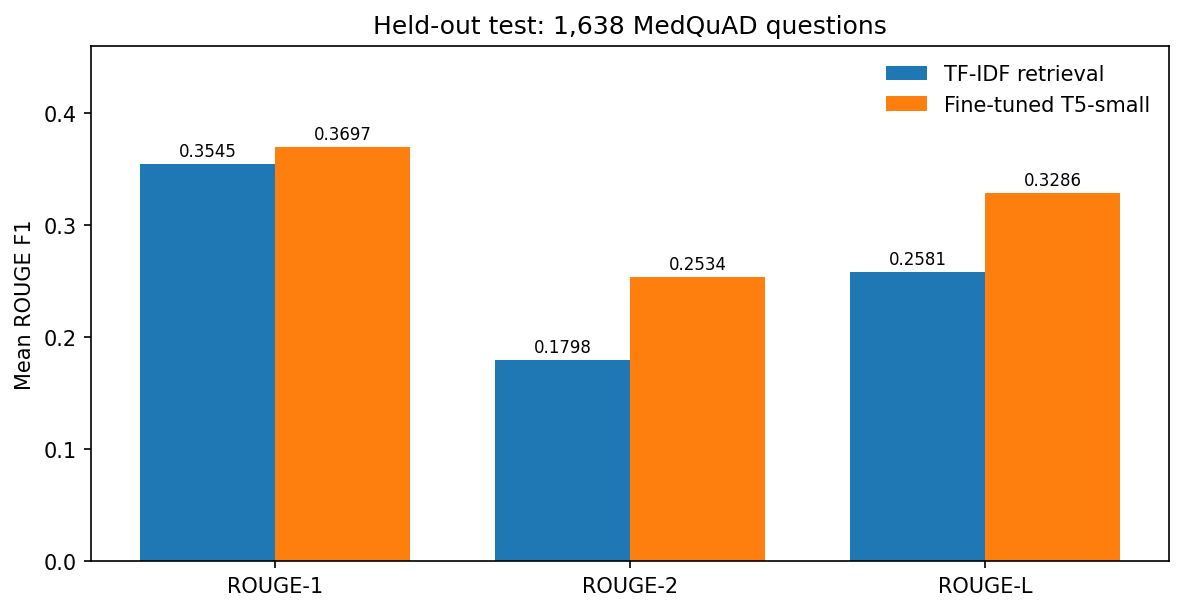

In [ ]:
# Saved research figure: rendered from the recorded experimental metrics.
# This figure is embedded; no model training or data download is required.


### Figure 2 — HealthAssist v6 functional question coverage
The 20 questions were selected and examined during prototype development.
These outcomes describe answer availability, **not independent generalization,
clinical correctness, or safety**.

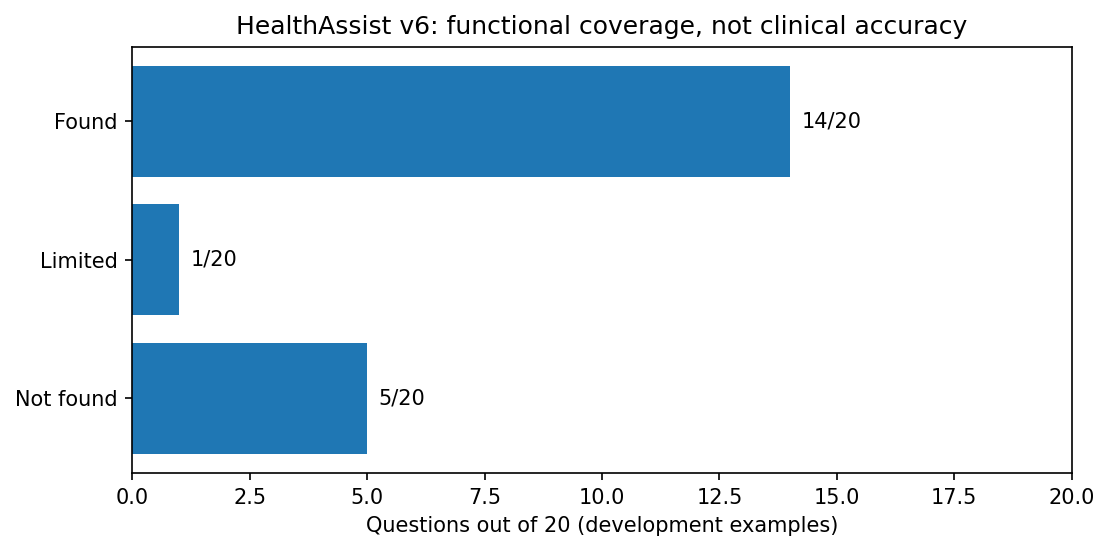

In [ ]:
# Saved research figure: rendered from the recorded experimental metrics.
# This figure is embedded; no model training or data download is required.


## Submission Audit — Static Checks Only

- No training or inference was rerun for this review.
- Saved experimental outputs were retained.
- Historical TF-IDF evaluation: **1,675** validation questions; ROUGE-1/2/L
  **0.3465 / 0.1618 / 0.2424**, before the final two-record cleaning.
- Final dataset: **13,045 training / 1,674 validation / 1,638 testing**.
- Final model comparison: TF-IDF vs. T5-small on the same 1,638 test questions.
- Final prototype: 14 found, 1 limited, 5 not found among 20 development questions.
- A clean full sequential execution is **not certified**; Colab Drive paths,
  checkpoints, package versions and function-definition order may require attention.
- Demo video and public hosting were intentionally **not claimed or fabricated**.

**Important:** Do not choose Colab's *Run all* merely to inspect these figures.
The charts above are already embedded in this notebook's saved outputs.